# Paper figures: main article and sensitivity

Run the **two setup cells** below once. Then run any figure cell independently.
Each figure cell has a `SAVE` switch and editable settings at the top.
Exports go to **`figs/paper_2026/`**, leaving the original figures untouched:
vector PDF/SVG, 300-dpi PNG, CSV data, caption and scenario JSON.
To save a preview later, call `save_figure("F1_dna_trajectories")` with its figure ID.
The final optional cell bundles only the figures you have run into a PDF.

**Contents:** F1; F2a-c unit costs; F3a-c lifecycle components; F4a-b outlook
and lifecycle; F5a-c encoding/addressing; F6a-b historical fits; M1 tornado;
S1-S11 sensitivity figures from `Figures_Sensitivity_Paper.ipynb`.

**Conventions:** the economic figures use the calculator's 2026 baseline and
decimal MB/TB. A retention of d years charges exactly d years. Annual decline
percentages are not continuous exponential coefficients. The legacy figure
topics are retained, but these are recalculations, not pixel-identical reproductions.
F4a's target-year guide curves are illustrative interpolations, not fitted forecasts.
F5 retains the legacy addressing/overhead convention; F6 refits historical data
without changing the economic model's established DNA fits.

Tape declines still follow the current configuration (media 20%, hardware 0%,
energy 15%). The suggested 10%/0%/0% alternative has **not** been silently
adopted. Edit `BASE = replace(BASE, ...)` below when that decision is made.
No inflation or PPP adjustment is performed. All future trends are scenarios.

Requirements: repository Python environment plus Jupyter/IPython and nbformat.
No website server, downloads, browser, or LaTeX installation is required.

## Setup 1: baseline, style and output

In [2]:
from pathlib import Path
from dataclasses import asdict, replace
import hashlib
import importlib.metadata
import json
import math
import os
import subprocess
import sys
import textwrap
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
import seaborn as sns
from IPython.display import display

# Open this notebook with the repository as its working directory.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "economic_dna" / "scenario.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the Economic_DNA repository.")
sys.path.insert(0, str(ROOT))

from economic_dna import (
    Scenario, dna_cost_sensitivity, dna_cost_advantage,
    simulate_scenario, simulate_start_years, find_breakeven_synthesis_cost,
)
from economic_dna.sensitivity import DNA_SENSITIVITY_PARAMETERS

from economic_dna.assumptions import model_metadata
from economic_dna import simulate_dna_unit_costs, find_crossover_years, load_observed_sequencing_costs
from preamble import calc_index_size
from scipy.optimize import curve_fit

# Uses assumptions.yaml, including corrected cloud units and 2026 price anchors.
BASE = Scenario()
# Example alternative, pending the paper's assumption review:
# BASE = replace(BASE, tape_media_decline_percent=10,
#                tape_hardware_decline_percent=0, tape_energy_decline_percent=0)
SAVE = True
FUTURE_START = 2050
FINAL_START = 2400
RARE_RETRIEVAL = 0.001  # percent/year; 1,000x less than the baseline's 1%
COMPARATOR = "Amazon Deep Archive"
# Point this environment variable at a temporary directory for validation only.
OUT = Path(os.environ.get("DNA_PAPER_FIGURE_OUTPUT", str(ROOT / "figs" / "paper_2026")))


sns.set_theme(style="white", context="notebook", font_scale=1.1, palette="deep")
mpl.rcParams.update({
    "mathtext.fontset": "cm", "axes.labelweight": "medium",
    "axes.titleweight": "semibold", "axes.titlesize": 13,
    "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.fontsize": 10, "lines.linewidth": 2,
    "axes.edgecolor": "#aeb8bf", "axes.linewidth": 0.8, "axes.labelpad": 9,
    "text.color": "#202b33", "axes.labelcolor": "#202b33",
    "xtick.color": "#46535d", "ytick.color": "#46535d",
    "legend.handlelength": 2.8, "legend.handletextpad": 0.8,
    "legend.labelspacing": 0.6, "legend.columnspacing": 1.8,
    "legend.edgecolor": "#dce2e6", "legend.facecolor": "white",
    "legend.fancybox": False, "legend.framealpha": 1,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "savefig.dpi": 300, "figure.dpi": 110,
})
PALETTE = sns.color_palette("deep")
COLORS = dict(zip(BASE.technologies, (PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[3])))
STYLES = dict(zip(BASE.technologies, ("-", "--", "-.", ":")))
PEERS = [t for t in BASE.technologies if t != "DNA"]
FIGURES, CAPTIONS, TABLES, SCENARIOS = {}, {}, {}, {}

display(pd.DataFrame({
    "Parameter": ["Archive (TB)", "Objects", "Object size (MB)", "Annual retrieval (%)",
                  "Start year", "Retention (years)", "Synthesis (USD/MB at anchor)",
                  "Sequencing (USD/MB at anchor)", "Synthesis annual decline (%)",
                  "Sequencing annual decline (%)"],
    "Value": [BASE.archive_size_tb, BASE.number_of_assets, BASE.average_asset_size_mb,
              BASE.annual_retrieval_percent, BASE.start_year, BASE.horizon_years,
              BASE.dna_synthesis_cost_per_mb, BASE.dna_sequencing_cost_per_mb,
              BASE.synthesis_decline_percent, BASE.sequencing_decline_percent],
}))
print(f"Output folder: {OUT}")

display(pd.DataFrame([asdict(BASE)]).T.rename(columns={0: "Baseline value"}))
print(model_metadata()["currency"])

,Parameter,Value
0,Archive (TB),1.000000
1,Objects,1000.000000
2,Object size (MB),1000.000000
3,Annual retrieval (%),1.000000
4,Start year,2026.000000
5,Retention (years),100.000000
6,Synthesis (USD/MB at anchor),16573.838544
7,Sequencing (USD/MB at anchor),0.134757
8,Synthesis annual decline (%),15.388500
9,Sequencing annual decline (%),38.065945


Output folder: C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


,Baseline value
archive_size_tb,1.0
average_asset_size_mb,1000.0
annual_retrieval_percent,1.0
start_year,2026
horizon_years,100
discount_rate_percent,0.0
dna_cost_base_year,2026
dna_synthesis_cost_per_mb,16573.838544
dna_sequencing_cost_per_mb,0.134757
synthesis_decline_percent,15.3885


United States dollars (USD); 2026 price baseline; no inflation or PPP adjustment


## Setup 2: shared plotting and export helpers

Run once. This cell is collapsed to keep the figure cells easy to scan.

In [3]:
def tidy(ax, xlabel=None, ylabel=None, title=None):
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title, loc="left", pad=12)
    ax.grid(axis="y", color="#e6eaed", linewidth=0.65)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)

def legend(ax, **kwargs):
    options = {"frameon": True, "borderpad": 0.65}
    options.update(kwargs)
    result = ax.legend(**options)
    result.get_title().set_fontweight("semibold")
    return result

def totals(scenario, present_value=False):
    column = "present_value_usd" if present_value else "total_cost_usd"
    return simulate_scenario(scenario).totals.set_index("technology")[column]

def describe(s):
    return (f"{s.archive_size_tb:g} TB; {s.average_asset_size_mb:g} MB/object; "
            f"{s.annual_retrieval_percent:g}% retrieval/year; start {s.start_year}; "
            f"{s.horizon_years} years; discount {s.discount_rate_percent:g}%/year")


def threshold_at_start(scenario, present_value=False):
    """Public solver reports the anchor-year price; also expose start-year prices."""
    frame = find_breakeven_synthesis_cost(scenario, present_value).copy()
    factor = (1 - scenario.synthesis_decline_percent / 100) ** (
        scenario.start_year - scenario.dna_cost_base_year)
    frame["threshold_start_usd_per_mb"] = (
        pd.to_numeric(frame["breakeven_synthesis_cost_usd_per_mb"], errors="coerce") * factor
    )
    frame["reachable"] = frame["threshold_start_usd_per_mb"].notna()
    frame["start_year"] = scenario.start_year
    frame["annual_retrieval_percent"] = scenario.annual_retrieval_percent
    return frame

def future_at_price(scenario, price_at_start):
    factor = (1 - scenario.synthesis_decline_percent / 100) ** (
        scenario.start_year - scenario.dna_cost_base_year)
    return replace(scenario, dna_synthesis_cost_per_mb=float(price_at_start / factor))

def dna_cost_with_floor(scenario, floor_usd_per_mb=0.0):
    """Supplement-only extension: clamp synthesis USD/MB in every calendar year.

    Sequencing, workload, and replacement timing are identical to the website.
    A floor of zero reproduces its DNA total. This extension is not in the app.
    """
    if floor_usd_per_mb < 0:
        raise ValueError("The synthesis floor must be nonnegative.")
    years = np.arange(scenario.start_year, scenario.start_year + scenario.horizon_years)
    prices = scenario.dna_synthesis_cost_per_mb * (
        1 - scenario.synthesis_decline_percent / 100) ** (years - scenario.dna_cost_base_year)
    write_mask = (years - scenario.start_year) % scenario.dna_durability_years == 0
    write = scenario.archive_size_mb * np.maximum(prices, floor_usd_per_mb) * write_mask
    read = (scenario.archive_size_mb * scenario.annual_retrieval_percent / 100
            * scenario.dna_sequencing_cost_per_mb
            * (1 - scenario.sequencing_decline_percent / 100) ** (years - scenario.dna_cost_base_year))
    return float((write + read).sum())

# S8/S9 configuration: the baseline is always shown alongside this explicit what-if.
HEATMAP_SYNTHESIS_DECLINE = 60.0  # actual annual percentage, anchored as in BASE
HEATMAP_MAX_RETENTION = 10_000   # model's supported horizon limit
from scipy.optimize import brentq

def heatmap_evaluator(scenario, max_horizon):
    """Scale public-model annual cost streams; retain its prices and replacement schedule."""
    flat = simulate_scenario(replace(
        scenario, horizon_years=int(max_horizon), sequencing_decline_percent=0.0,
        amazon_decline_percent=0.0, technologies=("DNA", "Amazon Deep Archive"),
    )).yearly
    dna = flat[flat.technology == "DNA"]
    amazon = flat[flat.technology == "Amazon Deep Archive"]
    write = dna.write_cost_usd.to_numpy()
    read = dna.read_cost_usd.to_numpy()
    cloud = amazon.total_cost_usd.to_numpy()
    dna_age = dna.year.to_numpy() - scenario.dna_cost_base_year
    cloud_age = amazon.year.to_numpy() - scenario.amazon_price_base_year

    def dna_cumulative(rate):
        return np.cumsum(write + read * np.power(1 - rate / 100, dna_age))

    def cloud_cumulative(rate):
        return np.cumsum(cloud * np.power(1 - rate / 100, cloud_age))

    def dna_total(rate, horizon):
        return float(write[:horizon].sum() + np.dot(
            read[:horizon], np.power(1 - rate / 100, dna_age[:horizon])))

    def cloud_total(rate, horizon):
        return float(np.dot(cloud[:horizon], np.power(1 - rate / 100, cloud_age[:horizon])))

    return dna_cumulative, cloud_cumulative, dna_total, cloud_total

def parity_root(function, lower, upper):
    """A root exists only with a bracket (or exact endpoint equality)."""
    left, right = function(lower), function(upper)
    if left == 0:
        return float(lower)
    if right == 0:
        return float(upper)
    if np.sign(left) == np.sign(right):
        return np.nan
    return float(brentq(function, lower, upper, xtol=1e-11))

def joint_heatmap_panels(grids, boundaries, scenarios, x_column, xlabel, reference_x,
                         log_x=False):
    """Shared S4 colour convention; draw numerically solved parity boundaries."""
    limit = max(1.0, float(np.ceil(np.abs(grids.log10_cost_ratio).max())))
    fig, axes = plt.subplots(1, 2, figsize=(13.8, 6.2))
    fig.subplots_adjust(left=0.065, right=0.88, bottom=0.20, top=0.85, wspace=0.13)
    fig.suptitle(
        f"DNA / Amazon cost sensitivity: archive starts in {next(iter(scenarios.values())).start_year}",
        fontsize=14, fontweight="bold", y=0.985,
    )
    for index, ((key, scenario), ax) in enumerate(zip(scenarios.items(), axes)):
        frame = grids[grids.scenario == key]
        grid = frame.pivot(index="amazon_decline_percent", columns=x_column,
                           values="log10_cost_ratio")
        mesh = ax.pcolormesh(grid.columns, grid.index, grid.to_numpy(), shading="auto",
                             cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
                             rasterized=True)
        boundary = boundaries[boundaries.scenario == key].sort_values(x_column)
        valid = boundary.dropna(subset=[x_column, "amazon_decline_percent"])
        if len(valid):
            # NaNs split disjoint segments; no line is fabricated beyond a root.
            ax.plot(boundary[x_column], boundary.amazon_decline_percent,
                    color="black", lw=2, label="Cost parity", zorder=5)
            point = valid.iloc[len(valid) // 2]
            ax.annotate("Cost parity", (point[x_column], point.amazon_decline_percent),
                        xytext=(8, 10), textcoords="offset points", fontsize=10,
                        bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none"},
                        zorder=6)
        else:
            ax.text(0.5, 0.68, "No cost parity\nwithin the displayed range",
                    ha="center", va="center", transform=ax.transAxes,
                    bbox={"facecolor": "white", "alpha": 0.92, "edgecolor": "none"}, fontsize=11)
        ax.scatter(reference_x, scenario.amazon_decline_percent, marker="*", s=160,
                   color="white", edgecolor="black", linewidth=1.2, zorder=7)
        star_label = (
            "Baseline DNA sequencing\nand Amazon decline rates"
            if x_column == "sequencing_decline_percent"
            else "Baseline retention\nand Amazon decline rate"
        )
        ax.annotate(
            star_label, (reference_x, scenario.amazon_decline_percent),
            xytext=(30, 12), textcoords="offset points", ha="left", va="bottom",
            fontsize=9, zorder=8,
            arrowprops={"arrowstyle": "->", "color": "0.2", "lw": 1.1, "shrinkB": 9},
            bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "none", "pad": 2.5},
        )
        if log_x:
            ax.set_xscale("log")
        ax.set_xlim(grid.columns.min(), grid.columns.max())
        ax.set_ylim(grid.index.min(), grid.index.max())
        tidy(ax, xlabel, "Amazon annual cost decline (%)" if index == 0 else None,
             f"({chr(97 + index)}) Synthesis decline: {scenario.synthesis_decline_percent:.2f}%/year")
        ax.grid(False)
    colorbar_ax = fig.add_axes([0.91, 0.20, 0.015, 0.65])
    fig.colorbar(mesh, cax=colorbar_ax,
                 label=r"$\log_{10}(C_{\mathrm{DNA}}/C_{\mathrm{Amazon}})$")
    fig.legend(handles=[
        Line2D([], [], color="black", lw=2, label="Cost parity (when present)"),
    ], loc="lower center", bbox_to_anchor=(0.48, 0.02), ncol=1, frameon=False)
    return fig

# S10/S11: illustrative annual synthesis declines, with all prices anchored as in BASE.
PARITY_SYNTHESIS_RATES = (50.0, 55.0, 60.0, 65.0)
PARITY_AMAZON_RANGE = (0.0, 30.0)

def synthesis_parity_lines(kind, x_values):
    """Solve Amazon decline at cost equality for each synthesis scenario and x."""
    x_values = np.asarray(x_values)
    max_horizon = BASE.horizon_years if kind == "sequencing" else int(x_values.max())
    scenarios = {
        f"synthesis_{rate:g}": replace(
            BASE, start_year=FUTURE_START, synthesis_decline_percent=float(rate),
            technologies=("DNA", "Amazon Deep Archive"),
        )
        for rate in (*PARITY_SYNTHESIS_RATES, float(BASE.synthesis_decline_percent))
    }
    rows = []
    for key, scenario in scenarios.items():
        dna_cumulative, _, dna_total, cloud_total = heatmap_evaluator(scenario, max_horizon)
        if kind == "retention":
            dna_values = dna_cumulative(scenario.sequencing_decline_percent)[x_values.astype(int) - 1]
        else:
            dna_values = [dna_total(float(x), BASE.horizon_years) for x in x_values]
        for x, dna_cost in zip(x_values, dna_values):
            horizon = BASE.horizon_years if kind == "sequencing" else int(x)
            def difference(rate):
                return dna_cost - cloud_total(rate, horizon)
            cloud_rate = parity_root(difference, *PARITY_AMAZON_RANGE)
            if np.isfinite(cloud_rate):
                status = "parity_in_range"
            elif difference(PARITY_AMAZON_RANGE[0]) > 0:
                status = "DNA_more_expensive_throughout_range"
            else:
                status = "DNA_cheaper_throughout_range"
            rows.append({
                "scenario": key,
                "synthesis_decline_percent": scenario.synthesis_decline_percent,
                "sequencing_decline_percent": float(x) if kind == "sequencing" else scenario.sequencing_decline_percent,
                "retention_years": horizon,
                "amazon_decline_percent": cloud_rate,
                "dna_cost_usd": float(dna_cost),
                "comparison_cost_usd": cloud_total(cloud_rate, horizon) if np.isfinite(cloud_rate) else np.nan,
                "root_exists": bool(np.isfinite(cloud_rate)), "status": status,
            })
    return pd.DataFrame(rows), scenarios

def plot_synthesis_parity_lines(frame, kind):
    x_column = "sequencing_decline_percent" if kind == "sequencing" else "retention_years"
    xlabel = "DNA sequencing annual decline (%)" if kind == "sequencing" else "Data retention (years)"
    fig, ax = plt.subplots(figsize=(9.5, 6.0), layout="constrained")
    for index, rate in enumerate(PARITY_SYNTHESIS_RATES):
        part = frame[frame.synthesis_decline_percent == rate].sort_values(x_column)
        ax.plot(part[x_column], part.amazon_decline_percent, color=PALETTE[index],
                ls=("-", "--", "-.", ":")[index], lw=2.2, label=f"{rate:g}%/year")
    baseline = frame[np.isclose(frame.synthesis_decline_percent, BASE.synthesis_decline_percent)]
    if baseline.root_exists.any():
        ax.plot(baseline[x_column], baseline.amazon_decline_percent,
                color="0.25", ls=(0, (1, 2)), label=f"Baseline: {BASE.synthesis_decline_percent:.2f}%/year")
    else:
        ax.text(0.98, 0.98, f"Baseline synthesis ({BASE.synthesis_decline_percent:.2f}%/year):\n"
                "no parity within this range", ha="right", va="top",
                transform=ax.transAxes, fontsize=9)
    reference_x = BASE.sequencing_decline_percent if kind == "sequencing" else BASE.horizon_years
    label = ("Baseline DNA sequencing\nand Amazon decline rates" if kind == "sequencing"
             else "Baseline retention\nand Amazon decline rate")
    ax.scatter(reference_x, BASE.amazon_decline_percent, marker="*", s=160, facecolor="white",
               edgecolor="black", linewidth=1.2, zorder=5)
    ax.annotate(label, (reference_x, BASE.amazon_decline_percent),
                xytext=(34, 0), textcoords="offset points", ha="left", va="center",
                fontsize=9, zorder=6,
                arrowprops={"arrowstyle": "->", "color": "0.2", "lw": 1.1, "shrinkB": 9},
                bbox={"facecolor": "white", "alpha": 0.92, "edgecolor": "none", "pad": 2.5})
    if kind == "retention":
        ax.set_xscale("log")
    ax.set_xlim(frame[x_column].min(), frame[x_column].max())
    ax.set_ylim(*PARITY_AMAZON_RANGE)
    tidy(ax, xlabel, "Amazon annual cost decline at parity (%)",
         f"DNA / Amazon cost parity: archive starts in {FUTURE_START}")
    legend(ax, title="Annual synthesis decline", loc="upper left", ncol=2)
    return fig


def save_figure(name):
    """Export a previously rendered figure, its exact input scenarios and data."""
    if name not in FIGURES:
        raise KeyError(f"Run the figure cell first: {name}")
    OUT.mkdir(parents=True, exist_ok=True)
    fig = FIGURES[name]
    for extension in ("pdf", "svg", "png"):
        fig.savefig(OUT / f"{name}.{extension}", bbox_inches="tight", facecolor="white")
    for suffix, frame in TABLES[name].items():
        frame.to_csv(OUT / f"{name}_{suffix}.csv", index=False)
    source_names = ["assumptions.yaml", "economic_dna/scenario.py", "economic_dna/simulation.py",
                    "economic_dna/sensitivity.py", "economic_dna/viability.py", "preamble.py",
                    "Figures_Paper_2026.ipynb"]
    metadata = {
        "figure": name, "caption": CAPTIONS[name], "scenarios": SCENARIOS[name],
        "currency": model_metadata()["currency"],
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "source_sha256": {p: hashlib.sha256((ROOT / p).read_bytes()).hexdigest() for p in source_names},
        "versions": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "scipy", "seaborn")},
    }
    (OUT / f"{name}.json").write_text(json.dumps(metadata, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    (OUT / f"{name}_caption.txt").write_text(CAPTIONS[name] + "\n", encoding="utf-8")
    print(f"Saved {name}: PDF, SVG, PNG, CSV and metadata in {OUT}")

def record(name, fig, caption, tables, scenarios):
    """Keep preview and exports tied to this figure, never to plt's current axes."""
    if name in FIGURES:
        plt.close(FIGURES[name])
    FIGURES[name] = fig
    CAPTIONS[name] = caption
    TABLES[name] = {key: value.copy() for key, value in tables.items()}
    SCENARIOS[name] = {key: asdict(value) for key, value in scenarios.items()}
    if SAVE:
        save_figure(name)
    display(fig)
    plt.close(fig)

def mark_parity(ax, years, dna, peer, color="0.4", label="Parity"):
    valid = np.flatnonzero(np.asarray(dna) <= np.asarray(peer))
    if len(valid):
        year = np.asarray(years)[valid[0]]
        ax.axvline(year, color=color, ls=":", lw=1)
        ax.annotate(f"{label}: {year:g}", (year, np.asarray(peer)[valid[0]]),
                    xytext=(5, 12), textcoords="offset points", fontsize=9, color=color)

def addressing_table(scenario, primer_count=10, primer_size=30,
                     oligo_sizes=(100, 150, 300, 500, 1000, 10000)):
    rows = []
    price_per_base = scenario.dna_synthesis_cost_per_mb / 4e6 * (
        1 - scenario.synthesis_decline_percent / 100) ** (scenario.start_year - scenario.dna_cost_base_year)
    for objects in (100, 1000, 10000, 100000, 1000000, 10000000):
        for length in oligo_sizes:
            info = calc_index_size(n_objects=objects, n_primers=primer_count,
                obj_size_mb=scenario.average_asset_size_mb, oligo_size=length,
                primer_size=primer_size, base_synthesis_cost=price_per_base)
            if info:
                rows.append({"Objects": objects, "Oligo bases": str(length), **info})
    return pd.DataFrame(rows)

def s4_synthesis_parity(amazon_decline_percent=10.0, start_year=None):
    """Annual synthesis decline at S4 lifecycle parity, not unit-price parity."""
    scenario = replace(BASE, start_year=FUTURE_START if start_year is None else start_year,
                       amazon_decline_percent=amazon_decline_percent,
                       technologies=("DNA", "Amazon Deep Archive"))
    def difference(rate):
        costs = totals(replace(scenario, synthesis_decline_percent=float(rate)))
        return costs["DNA"] - costs["Amazon Deep Archive"]
    rate = parity_root(difference, 0.0, 99.0)
    return rate

def f2_alternative_declines():
    threshold = s4_synthesis_parity(10.0, start_year=2026)
    if not np.isfinite(threshold):
        return [60.0, 70.0, 80.0]
    # Avoid a nearly duplicate illustrative 60% line within two percentage points.
    return [threshold] + ([60.0] if abs(threshold - 60.0) > 2.0 else []) + [70.0, 80.0]

def s8_sequencing_parity(amazon_decline_percent=10.0, start_year=None):
    """Conditional S8(b) lifecycle parity with accelerated synthesis."""
    scenario = replace(BASE, start_year=FUTURE_START if start_year is None else start_year,
                       synthesis_decline_percent=HEATMAP_SYNTHESIS_DECLINE,
                       amazon_decline_percent=amazon_decline_percent,
                       technologies=("DNA", "Amazon Deep Archive"))
    def difference(rate):
        costs = totals(replace(scenario, sequencing_decline_percent=float(rate)))
        return costs["DNA"] - costs["Amazon Deep Archive"]
    rate = parity_root(difference, 0.0, 99.0)
    return rate


## F1: DNA synthesis and sequencing trajectories

Historical-fit trajectories extended from the configured price anchor. USD per logical MB, not per nucleotide.

F1 goodness of fit: displayed model trajectories, no refitting.
R^2 and RMSE use historical observations on the original (non-logarithmic) cost scale.
Synthesis: R^2 = 0.984887; RMSE = 94,907.937078 USD/logical MB (n = 12, years 1995.00-2017.00).
Sequencing: R^2 = 0.890022; RMSE = 1,242.476941 USD/logical MB (n = 78, years 2001.74-2022.41).
Saved F1_dna_trajectories: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


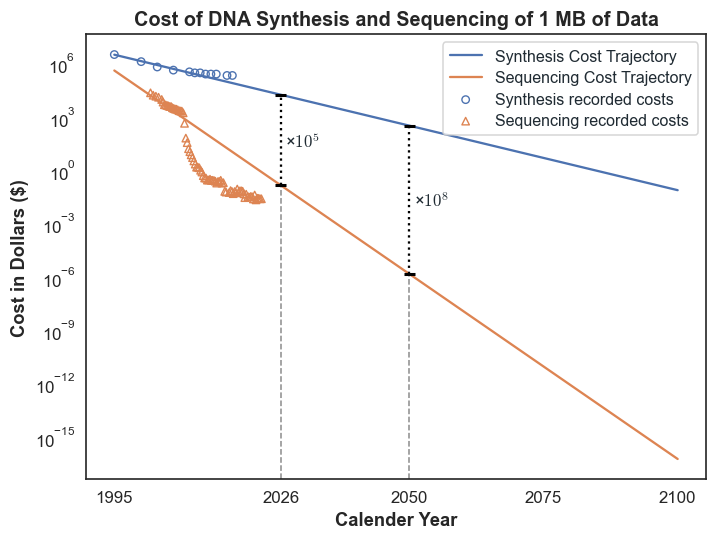

In [3]:
SAVE = True  # False previews only; True exports this figure and its data.
SHOW_RECORDED_COSTS = True  # False hides historical points; fitted curves stay unchanged.
years = np.arange(1995 if SHOW_RECORDED_COSTS else 2000, 2101)
frame = pd.DataFrame({"year": years})
fig, ax = plt.subplots(figsize=(6.4, 4.8), layout="constrained")
line_styles = {"Synthesis": (PALETTE[0], "-"), "Sequencing": (PALETTE[1], "-")}
for name, price, decline in (
    ("Synthesis", BASE.dna_synthesis_cost_per_mb, BASE.synthesis_decline_percent),
    ("Sequencing", BASE.dna_sequencing_cost_per_mb, BASE.sequencing_decline_percent),
):
    frame[name] = price * (1 - decline / 100) ** (years - BASE.dna_cost_base_year)
    color, dash = line_styles[name]
    ax.plot(years, frame[name], label=f"{name} Cost Trajectory", color=color, ls=dash, lw=1.5)
anchor_year = BASE.dna_cost_base_year
gap_years = [anchor_year, 2050]
gaps = []
for year in dict.fromkeys(gap_years):
    synthesis = BASE.dna_synthesis_cost_per_mb * (1 - BASE.synthesis_decline_percent / 100) ** (year - anchor_year)
    sequencing = BASE.dna_sequencing_cost_per_mb * (1 - BASE.sequencing_decline_percent / 100) ** (year - anchor_year)
    orders = np.log10(synthesis / sequencing)
    ax.vlines(year, sequencing, synthesis, color="black", ls=":", lw=1.5)
    ax.hlines([sequencing, synthesis], year - 1, year + 1, color="black", lw=2)
    label = rf"×$10^{{{int(round(orders))}}}$"
    ax.annotate(label, (year, np.sqrt(synthesis * sequencing)),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=11)
    gaps.append({"year": year, "synthesis_usd_per_mb": synthesis,
                 "sequencing_usd_per_mb": sequencing, "synthesis_to_sequencing_ratio": synthesis / sequencing,
                 "orders_of_magnitude": orders})
observations = pd.DataFrame(columns=["year", "process", "recorded_cost", "recorded_unit", "cost_usd_per_logical_mb", "source"])
from economic_dna.assumptions import load_assumptions
dna_units = load_assumptions()["dna"]
synthesis_observed = pd.DataFrame({
    "year": [1995, 2000, 2003, 2006, 2009, 2010, 2011, 2012, 2013, 2014, 2016, 2017],
    "recorded_cost": [0.75, 0.30, 0.15, 0.10, 0.08, 0.07, 0.07, 0.06, 0.06, 0.06, 0.05, 0.05],
})
synthesis_observed["process"] = "Synthesis"
synthesis_observed["recorded_unit"] = "USD/base"
synthesis_observed["cost_usd_per_logical_mb"] = synthesis_observed.recorded_cost * dna_units["bases_per_byte"] * dna_units["bytes_per_mb"]
synthesis_observed["source"] = "Figures.ipynb, Figure 6a historical observations"
sequencing_observed = load_observed_sequencing_costs().rename(columns={"sequencing_cost_usd_per_mb": "recorded_cost"}).copy()
sequencing_observed["process"] = "Sequencing"
sequencing_observed["recorded_unit"] = "USD per million sequenced bases"
sequencing_observed["cost_usd_per_logical_mb"] = sequencing_observed.recorded_cost * dna_units["bases_per_byte"] * dna_units["bytes_per_mb"] / 1e6
sequencing_observed["source"] = "NHGRI Sequencing_Cost_Data_Table_May2022.csv"
observations = pd.concat([synthesis_observed, sequencing_observed], ignore_index=True)

# Evaluate at observation dates, including fractional sequencing years, not future projections.
fit_observations = observations.copy()
fit_rows = []
for process, price, decline in (
    ("Synthesis", BASE.dna_synthesis_cost_per_mb, BASE.synthesis_decline_percent),
    ("Sequencing", BASE.dna_sequencing_cost_per_mb, BASE.sequencing_decline_percent),
):
    mask = fit_observations.process == process
    points = fit_observations.loc[mask]
    actual = points.cost_usd_per_logical_mb.to_numpy()
    predicted = price * (1 - decline / 100) ** (points.year.to_numpy() - BASE.dna_cost_base_year)
    residual = actual - predicted
    sse = float(np.sum(residual ** 2))
    sst = float(np.sum((actual - actual.mean()) ** 2))
    r_squared = 1 - sse / sst if sst > 0 else np.nan
    rmse = float(np.sqrt(np.mean(residual ** 2)))
    fit_observations.loc[mask, "predicted_usd_per_logical_mb"] = predicted
    fit_observations.loc[mask, "residual_usd_per_logical_mb"] = residual
    fit_rows.append({"process": process, "n_observations": len(points),
                     "first_year": float(points.year.min()), "last_year": float(points.year.max()),
                     "r_squared": r_squared, "rmse_usd_per_logical_mb": rmse})
f1_fit_metrics = pd.DataFrame(fit_rows)
print("F1 goodness of fit: displayed model trajectories, no refitting.")
print("R^2 and RMSE use historical observations on the original (non-logarithmic) cost scale.")
for row in f1_fit_metrics.itertuples():
    print(f"{row.process}: R^2 = {row.r_squared:.6f}; RMSE = {row.rmse_usd_per_logical_mb:,.6f} "
          f"USD/logical MB (n = {row.n_observations}, years {row.first_year:.2f}-{row.last_year:.2f}).")
f1_metrics_caption = " Goodness of fit against historical observations, on the original USD/logical MB scale: " + "; ".join(
    f"{row.process}: R2={row.r_squared:.4f}, RMSE={row.rmse_usd_per_logical_mb:.6g} USD/logical MB "
    f"(n={row.n_observations})" for row in f1_fit_metrics.itertuples()) + ". The plotted trajectories are not refitted."
if not SHOW_RECORDED_COSTS:
    observations = observations.iloc[:0].copy()

if SHOW_RECORDED_COSTS:
    for process, marker in (("Synthesis", "o"), ("Sequencing", "^")):
        points = observations[observations.process == process]
        ax.scatter(points.year, points.cost_usd_per_logical_mb, marker=marker, s=24,
                   facecolors="none", edgecolors=line_styles[process][0], linewidths=0.9,
                   label=f"{process} recorded costs", zorder=4)
ax.set_xticks(sorted({int(years[0]), anchor_year, 2050, 2075, 2100}))
ax.set_yscale("log")
# Freeze the log limits before adding guides so their lower ends meet the axis.
limits = ax.get_ylim()
for gap in gaps:
    ax.vlines(gap["year"], limits[0], gap["sequencing_usd_per_mb"],
              color="0.55", ls="--", lw=1, zorder=0,
              label="_nolegend_")
ax.set_ylim(limits)
ax.set_title("Cost of DNA Synthesis and Sequencing of 1 MB of Data",
             fontsize=13, fontweight="bold", color="0.15", pad=6)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.set_xlabel("Calender Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.legend(loc="upper right", frameon=True, fancybox=True,
          facecolor="white", edgecolor="0.8", framealpha=0.8, fontsize=10.5,
          handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.4)
record("F1_dna_trajectories", fig, "Historical-fit DNA unit-cost trajectories; extensions are scenarios, not observations. Capped vertical markers show synthesis / sequencing at the price anchor and in 2050, rounded to the nearest power of ten; exact ratios are exported in the gaps table. "
       + ("Historical points are enabled: synthesis observations from Figures.ipynb Figure 6a and NHGRI sequencing data, converted to USD per logical MB using the model's bases-per-byte convention. Observations are not inflation-adjusted and do not replace the established fits." if SHOW_RECORDED_COSTS else "Historical points are disabled.") + f1_metrics_caption,
       {"costs": frame, "gaps": pd.DataFrame(gaps), "observations": observations, "fit_metrics": f1_fit_metrics, "fit_observations": fit_observations}, {"baseline": BASE})

## F2a: synthesis and Amazon unit costs

Alternative continuous coefficients from the original figure are converted to actual annual percentage declines. First sampled parity years are marked when present. Cloud request costs are allocated using the configured object size.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F2a_unit_costs: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


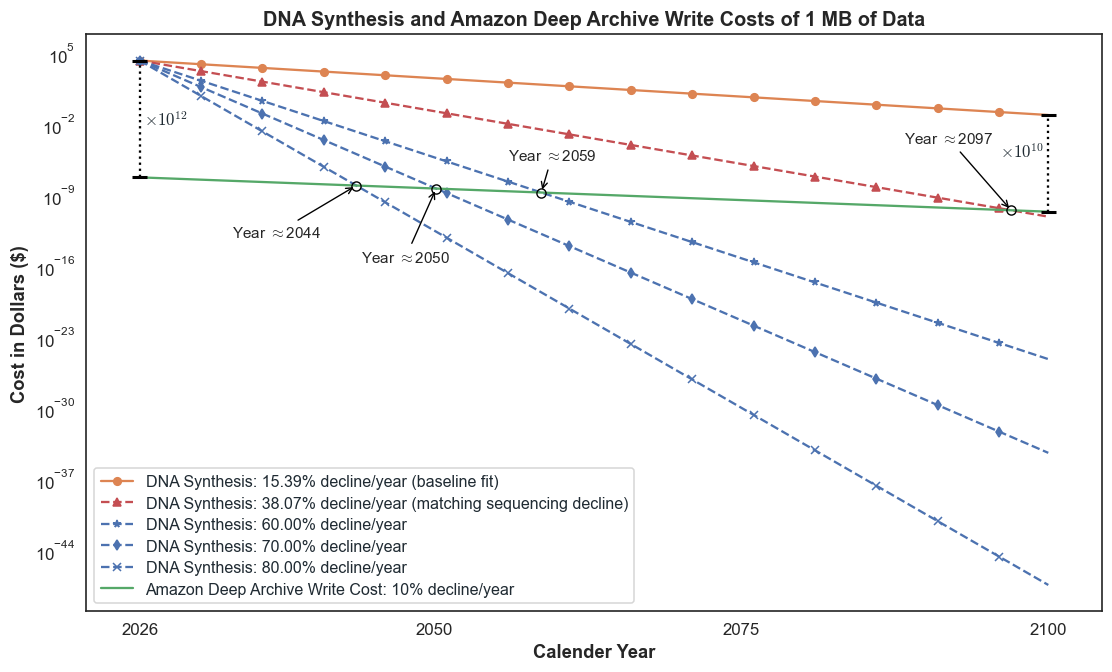

In [41]:
SAVE = True  # False previews only; True exports this figure and its data.
years = np.arange(BASE.start_year, 2101)
annual_declines = np.array([BASE.synthesis_decline_percent, BASE.sequencing_decline_percent, *f2_alternative_declines()])
coefficients = -np.log1p(-annual_declines / 100)
markers = ["o", "^", "*", "d", "x", "+"]
colors = [PALETTE[1], PALETTE[3], *([PALETTE[0]] * 4)]
arrow_offsets = [(0, 0), (-41, 42), (7, 19), (-20, -40), (-52, -26), (-75, -60)]
factor = (1 - BASE.amazon_decline_percent / 100) ** (years - BASE.amazon_price_base_year)
cloud = BASE.amazon_put_usd_per_request / BASE.average_asset_size_mb * factor
frame = pd.DataFrame({"year": years, "Amazon": cloud})
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
crossings = []
for index, coefficient in enumerate(coefficients):
    decline = 100 * (1 - np.exp(-coefficient))
    values = BASE.dna_synthesis_cost_per_mb * np.exp(-coefficient * (years - BASE.dna_cost_base_year))
    frame[f"DNA: {decline:.2f}% annual decline"] = values
    qualifier = " (baseline fit)" if index == 0 else " (matching sequencing decline)" if index == 1 else ""
    if index == 2 and np.isfinite(s4_synthesis_parity(10.0, start_year=2026)):
        qualifier = " (S4 2026 lifecycle parity, Amazon 10%)"
    label = f"DNA Synthesis: {decline:.2f}% decline/year{qualifier}"
    ax.plot(years, values, color=colors[index], marker=markers[index],
            markevery=5, markersize=5, lw=1.5, ls="-" if index == 0 else "--", label=label)
    # Log interpolation matches the exponential curves between sampled years.
    candidates = np.flatnonzero(values <= cloud)
    if len(candidates) and candidates[0] > 0:
        i = candidates[0]
        before, after = np.log(values[i - 1] / cloud[i - 1]), np.log(values[i] / cloud[i])
        year = years[i - 1] + before / (before - after) * (years[i] - years[i - 1])
        cost = np.exp(np.interp(year, years, np.log(cloud)))
        ax.plot(year, cost, "o", ms=6, mfc="none", mec="black", mew=0.9, zorder=5)
        ax.annotate(rf"Year $\approx${year:.0f}", (year, cost),
                    xytext=arrow_offsets[index], textcoords="offset points", ha="center",
                    va="bottom" if arrow_offsets[index][1] > 0 else "top", fontsize=10,
                    color="0.15", arrowprops={"arrowstyle": "->", "lw": 0.9, "color": "black"})
        crossings.append({"coefficient": coefficient, "annual_decline_percent": decline,
                          "parity_year": year, "cost_usd_per_mb": cost})
ax.plot(years, cloud, color=PALETTE[2], lw=1.5,
        label=f"Amazon Deep Archive Write Cost: {BASE.amazon_decline_percent:g}% decline/year")
gaps = []
baseline_values = frame[f"DNA: {100 * (1 - np.exp(-coefficients[0])):.2f}% annual decline"]
for i in (0, len(years) - 1):
    year, dna_cost, cloud_cost = years[i], baseline_values.iloc[i], cloud[i]
    orders = np.log10(dna_cost / cloud_cost)
    ax.vlines(year, cloud_cost, dna_cost, color="black", ls=":", lw=1.5)
    ax.hlines([cloud_cost, dna_cost], year - 0.6, year + 0.6, color="black", lw=2)
    ax.annotate(rf"$\times 10^{{{round(orders)}}}$", (year, np.sqrt(dna_cost * cloud_cost)),
                xytext=(3 if i == 0 else -3, 0 if i == 0 else 8), textcoords="offset points",
                ha="left" if i == 0 else "right", va="center", fontsize=11)
    gaps.append({"year": int(year), "synthesis_usd_per_mb": dna_cost,
                 "amazon_write_usd_per_mb": cloud_cost, "orders_of_magnitude": orders})
ax.set_yscale("log")
ax.set_xticks(sorted({BASE.start_year, 2050, 2075, 2100}))
ax.set_title("DNA Synthesis and Amazon Deep Archive Write Costs of 1 MB of Data",
             fontsize=13, fontweight="bold", color="0.15", pad=6)
ax.set_xlabel("Calender Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.legend(loc="lower left", frameon=True, fancybox=True,
          facecolor="white", edgecolor="0.8", framealpha=0.8, fontsize=10.5,
          handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.4)
record("F2a_unit_costs", fig,
       "DNA synthesis and Amazon write costs per logical MB. The original Figure 2a styling is retained, "
       "with the current price baseline and actual annual percentage declines. Circle/arrow markers "
       "show log-interpolated parity years; capped endpoint gaps are rounded to powers of ten.",
       {"costs": frame, "crossings": pd.DataFrame(crossings), "gaps": pd.DataFrame(gaps)}, {"baseline": BASE})

## F2b: sequencing and Amazon unit costs

Alternative continuous coefficients from the original figure are converted to actual annual percentage declines. First sampled parity years are marked when present. Cloud request costs are allocated using the configured object size.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F2b_unit_costs: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


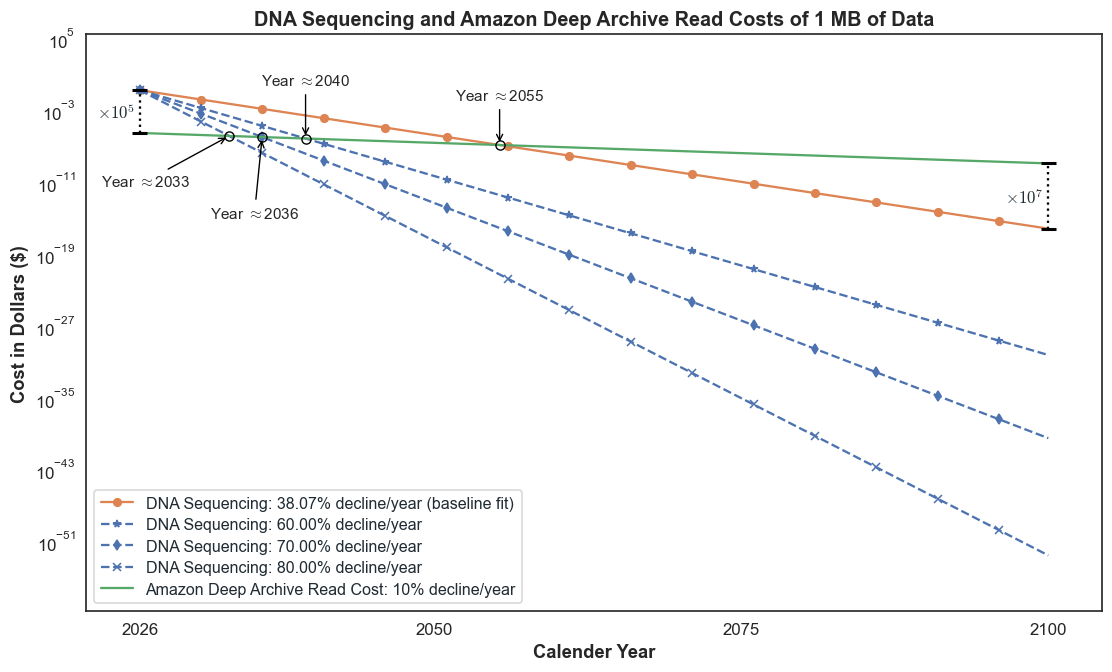

In [5]:
SAVE = True  # False previews only; True exports this figure and its data.
years = np.arange(BASE.start_year, 2101)
kind = 'Sequencing'
include_storage = False
factor = (1 - BASE.amazon_decline_percent / 100) ** (years - BASE.amazon_price_base_year)
if kind == "Synthesis":
    cloud_price = BASE.amazon_put_usd_per_request / BASE.average_asset_size_mb
    anchor_price = BASE.dna_synthesis_cost_per_mb
else:
    cloud_price = BASE.amazon_bulk_restore_usd_per_request / BASE.average_asset_size_mb + BASE.amazon_bulk_retrieval_usd_per_mb
    anchor_price = BASE.dna_sequencing_cost_per_mb
    if include_storage:
        if BASE.annual_retrieval_percent <= 0:
            raise ValueError("Per-retrieved-MB storage allocation requires positive retrieval.")
        cloud_price += BASE.amazon_storage_usd_per_mb_month * 12 / (BASE.annual_retrieval_percent / 100)
cloud = cloud_price * factor
frame = pd.DataFrame({"year": years, "Amazon": cloud})
sequencing_threshold = s8_sequencing_parity(10.0, start_year=2026)
has_threshold = np.isfinite(sequencing_threshold)
annual_declines = np.array([BASE.sequencing_decline_percent,
                           *([sequencing_threshold] if has_threshold else []), 60, 70, 80])
coefficients = -np.log1p(-annual_declines / 100)
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
markers = ["o", "^", "*", "d", "x"]
arrow_offsets = [(0, 27.5), (20, 30), (0, 33), (-5, -45), (-55, -25)]
if include_storage:
    arrow_offsets = [(10, 35), (25, 30), (20, 18), (10, -55), (-20, -25)]
if not has_threshold:
    markers.pop(1)
    arrow_offsets.pop(1)
crossings = []
for index, coefficient in enumerate(coefficients):
    decline = 100 * (1 - np.exp(-coefficient))
    values = anchor_price * np.exp(-coefficient * (years - BASE.dna_cost_base_year))
    frame[f"DNA: {decline:.2f}% annual decline"] = values
    ax.plot(years, values, color=PALETTE[1] if index == 0 else PALETTE[3] if index == 1 and has_threshold else PALETTE[0],
            label=f"DNA Sequencing: {decline:.2f}% decline/year" + (" (baseline fit)" if index == 0 else f" (S8 2026 parity; synthesis {HEATMAP_SYNTHESIS_DECLINE:g}%, Amazon 10%)" if index == 1 and has_threshold else ""),
            ls="-" if index == 0 else "--", lw=1.5, marker=markers[index], markevery=5, markersize=5)
    # Locate parity in log space, matching the exponential cost trajectories.
    candidates = np.flatnonzero(values <= cloud)
    if len(candidates) and candidates[0] > 0:
        i = candidates[0]
        before, after = np.log(values[i - 1] / cloud[i - 1]), np.log(values[i] / cloud[i])
        year = years[i - 1] + before / (before - after) * (years[i] - years[i - 1])
        cost = np.exp(np.interp(year, years, np.log(cloud)))
        ax.plot(year, cost, "o", ms=6, mfc="none", mec="black", mew=0.9, zorder=5)
        ax.annotate(rf"Year $\approx${year:.0f}", (year, cost),
                    xytext=arrow_offsets[index], textcoords="offset points", ha="center",
                    va="bottom" if arrow_offsets[index][1] > 0 else "top", fontsize=10,
                    color="0.15", arrowprops={"arrowstyle": "->", "lw": 0.9, "color": "black"})
        crossings.append({"coefficient": coefficient, "annual_decline_percent": decline,
                          "parity_year": year, "cost_usd_per_mb": cost})
cloud_label = "Read + Allocated Storage" if include_storage else "Read"
ax.plot(years, cloud, color=PALETTE[2], lw=1.5,
        label=f"Amazon Deep Archive {cloud_label} Cost: {BASE.amazon_decline_percent:g}% decline/year")
gaps = []
baseline_values = frame[f"DNA: {100 * (1 - np.exp(-coefficients[0])):.2f}% annual decline"]
for i in (0, len(years) - 1):
    year, dna_cost, cloud_cost = years[i], baseline_values.iloc[i], cloud[i]
    orders = abs(np.log10(dna_cost / cloud_cost))
    ax.vlines(year, min(dna_cost, cloud_cost), max(dna_cost, cloud_cost), color="black", ls=":", lw=1.5)
    ax.hlines([cloud_cost, dna_cost], year - 0.6, year + 0.6, color="black", lw=2)
    ax.annotate(rf"$\times 10^{{{round(orders)}}}$", (year, np.sqrt(dna_cost * cloud_cost)),
                xytext=(-3, 0), textcoords="offset points",
                ha="right", va="center", fontsize=11)
    gaps.append({"year": int(year), "sequencing_usd_per_mb": dna_cost,
                 "amazon_usd_per_mb": cloud_cost, "orders_of_magnitude": orders})
ax.set_yscale("log")
ax.margins(y=0.12)
ax.set_xticks(sorted({BASE.start_year, 2050, 2075, 2100}))
title = ("DNA Sequencing and Amazon Deep Archive Read + Storage Costs\nper Retrieved MB"
         if include_storage else "DNA Sequencing and Amazon Deep Archive Read Costs of 1 MB of Data")
ax.set_title(title, fontsize=13, fontweight="bold", color="0.15", pad=6)
ax.set_xlabel("Calender Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.legend(loc="lower left", frameon=True, fancybox=True,
          facecolor="white", edgecolor="0.8", framealpha=0.8, fontsize=10.5,
          handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.4)
record("F2b_unit_costs", fig,
       f"DNA alternative decline scenarios versus Amazon. S8(b) lifecycle parity is checked for deployment 2026 with synthesis decline {HEATMAP_SYNTHESIS_DECLINE:g}%/year and Amazon decline 10%/year. "
       + ("A conditional sequencing threshold is included. " if has_threshold else "No sequencing threshold exists; the illustrative 60/70/80% scenarios are not lifecycle parity rates. ")
       + "Actual annual declines are shown; storage allocation uses annual retrieved volume where included. Circle/arrow markers show log-interpolated unit-cost parity years; capped gaps show the larger-to-smaller cost ratio rounded to powers of ten.",
       {"costs": frame, "crossings": pd.DataFrame(crossings), "gaps": pd.DataFrame(gaps)}, {"baseline": BASE})

## F2c: sequencing and Amazon unit costs

Alternative continuous coefficients from the original figure are converted to actual annual percentage declines. First sampled parity years are marked when present. Storage is allocated per retrieved MB using the configured retrieval fraction.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F2c_unit_costs: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


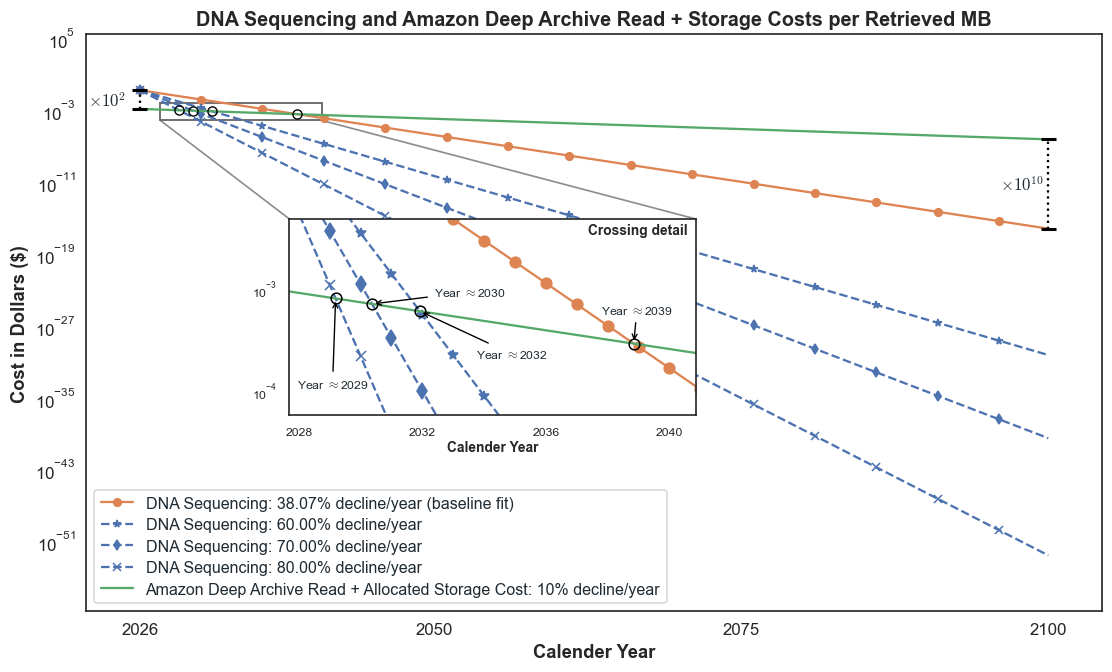

In [8]:
SAVE = True  # False previews only; True exports this figure and its data.
years = np.arange(BASE.start_year, 2101)
kind = 'Sequencing'
include_storage = True
factor = (1 - BASE.amazon_decline_percent / 100) ** (years - BASE.amazon_price_base_year)
if kind == "Synthesis":
    cloud_price = BASE.amazon_put_usd_per_request / BASE.average_asset_size_mb
    anchor_price = BASE.dna_synthesis_cost_per_mb
else:
    cloud_price = BASE.amazon_bulk_restore_usd_per_request / BASE.average_asset_size_mb + BASE.amazon_bulk_retrieval_usd_per_mb
    anchor_price = BASE.dna_sequencing_cost_per_mb
    if include_storage:
        if BASE.annual_retrieval_percent <= 0:
            raise ValueError("Per-retrieved-MB storage allocation requires positive retrieval.")
        cloud_price += BASE.amazon_storage_usd_per_mb_month * 12 / (BASE.annual_retrieval_percent / 100)
cloud = cloud_price * factor
frame = pd.DataFrame({"year": years, "Amazon": cloud})
sequencing_threshold = s8_sequencing_parity(10.0, start_year=2026)
has_threshold = np.isfinite(sequencing_threshold)
annual_declines = np.array([BASE.sequencing_decline_percent,
                           *([sequencing_threshold] if has_threshold else []), 60, 70, 80])
coefficients = -np.log1p(-annual_declines / 100)
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
if include_storage:
    zoom_ax = ax.inset_axes([0.20, 0.34, 0.40, 0.34], zorder=6)
markers = ["o", "^", "*", "d", "x"]
arrow_offsets = [(0, 27.5), (20, 30), (0, 33), (-5, -45), (-55, -25)]
if include_storage:
    arrow_offsets = [(10, 35), (25, 30), (20, 18), (10, -55), (-20, -25)]
if not has_threshold:
    markers.pop(1)
    arrow_offsets.pop(1)
crossings = []
for index, coefficient in enumerate(coefficients):
    decline = 100 * (1 - np.exp(-coefficient))
    values = anchor_price * np.exp(-coefficient * (years - BASE.dna_cost_base_year))
    frame[f"DNA: {decline:.2f}% annual decline"] = values
    ax.plot(years, values, color=PALETTE[1] if index == 0 else PALETTE[3] if index == 1 and has_threshold else PALETTE[0],
            label=f"DNA Sequencing: {decline:.2f}% decline/year" + (" (baseline fit)" if index == 0 else f" (S8 2026 parity; synthesis {HEATMAP_SYNTHESIS_DECLINE:g}%, Amazon 10%)" if index == 1 and has_threshold else ""),
            ls="-" if index == 0 else "--", lw=1.5, marker=markers[index], markevery=5, markersize=5)
    # Locate parity in log space, matching the exponential cost trajectories.
    candidates = np.flatnonzero(values <= cloud)
    if len(candidates) and candidates[0] > 0:
        i = candidates[0]
        before, after = np.log(values[i - 1] / cloud[i - 1]), np.log(values[i] / cloud[i])
        year = years[i - 1] + before / (before - after) * (years[i] - years[i - 1])
        cost = np.exp(np.interp(year, years, np.log(cloud)))
        ax.plot(year, cost, "o", ms=6, mfc="none", mec="black", mew=0.9, zorder=5)
        if not include_storage:
            ax.annotate(rf"Year $\approx${year:.0f}", (year, cost),
                        xytext=arrow_offsets[index], textcoords="offset points", ha="center",
                        va="bottom" if arrow_offsets[index][1] > 0 else "top", fontsize=10,
                        color="0.15", arrowprops={"arrowstyle": "->", "lw": 0.9, "color": "black"})
        crossings.append({"coefficient": coefficient, "annual_decline_percent": decline,
                          "parity_year": year, "cost_usd_per_mb": cost})
cloud_label = "Read + Allocated Storage" if include_storage else "Read"
ax.plot(years, cloud, color=PALETTE[2], lw=1.5,
        label=f"Amazon Deep Archive {cloud_label} Cost: {BASE.amazon_decline_percent:g}% decline/year")
gaps = []
baseline_values = frame[f"DNA: {100 * (1 - np.exp(-coefficients[0])):.2f}% annual decline"]
for i in (0, len(years) - 1):
    year, dna_cost, cloud_cost = years[i], baseline_values.iloc[i], cloud[i]
    orders = abs(np.log10(dna_cost / cloud_cost))
    ax.vlines(year, min(dna_cost, cloud_cost), max(dna_cost, cloud_cost), color="black", ls=":", lw=1.5)
    ax.hlines([cloud_cost, dna_cost], year - 0.6, year + 0.6, color="black", lw=2)
    ax.annotate(rf"$\times 10^{{{round(orders)}}}$", (year, np.sqrt(dna_cost * cloud_cost)),
                xytext=(-9 if include_storage and i == 0 else -3, 0), textcoords="offset points",
                ha="right", va="center", fontsize=11)
    gaps.append({"year": int(year), "sequencing_usd_per_mb": dna_cost,
                 "amazon_usd_per_mb": cloud_cost, "orders_of_magnitude": orders})
ax.set_yscale("log")
ax.margins(y=0.12)
ax.set_xticks(sorted({BASE.start_year, 2050, 2075, 2100}))
title = ("DNA Sequencing and Amazon Deep Archive Read + Storage Costs per Retrieved MB"
         if include_storage else "DNA Sequencing and Amazon Deep Archive Read Costs of 1 MB of Data")
ax.set_title(title, fontsize=13, fontweight="bold", color="0.15", pad=6)
ax.set_xlabel("Calender Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.legend(loc="lower left", frameon=True, fancybox=True,
          facecolor="white", edgecolor="0.8", framealpha=0.8, fontsize=10.5,
          handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.4)
if include_storage:
    zoom_ax.text(0.98, 0.98, "Crossing detail", transform=zoom_ax.transAxes,
                 ha="right", va="top", fontsize=9, fontweight="bold", color="0.15")
    for line in ax.lines:
        if not line.get_label().startswith("_"):
            zoom_ax.plot(line.get_xdata(), line.get_ydata(), color=line.get_color(),
                         ls=line.get_linestyle(), lw=1.5, marker=line.get_marker(),
                         markevery=1, markersize=7)
    ordered = sorted(crossings, key=lambda point: point["parity_year"])
    if ordered:
        left, right = ordered[0]["parity_year"] - 1.5, ordered[-1]["parity_year"] + 2
        lower = min(point["cost_usd_per_mb"] for point in ordered) / 5
        upper = max(point["cost_usd_per_mb"] for point in ordered) * 6
        zoom_ax.set_xlim(left, right)
        zoom_ax.set_ylim(lower, upper)
        ax.add_patch(mpl.patches.Rectangle((left, lower), right - left, upper - lower,
                     fill=False, edgecolor="0.4", lw=1.2))
        for source_x, detail_x in ((left, 0), (right, 1)):
            connector = mpl.patches.ConnectionPatch(
                xyA=(source_x, lower), coordsA=ax.transData,
                xyB=(detail_x, 1), coordsB=zoom_ax.transAxes,
                color="0.55", lw=1.1, clip_on=False, zorder=0.5)
            connector.set_in_layout(False)
            ax.add_artist(connector)
        offsets = [(-2, -52), (64, 4), (60, -24), (2, 18), (0, -25)]
        for index, point in enumerate(ordered):
            year, cost = point["parity_year"], point["cost_usd_per_mb"]
            offset = offsets[index % len(offsets)]
            zoom_ax.plot(year, cost, "o", ms=7, mfc="none", mec="black", mew=1, zorder=5)
            zoom_ax.annotate(rf'Year $\approx${year:.0f}',
                             (year, cost), xytext=offset, textcoords="offset points", ha="center",
                             va="bottom" if offset[1] > 0 else "top", fontsize=8,
                             arrowprops={"arrowstyle": "->", "color": "black", "lw": 0.9})
    else:
        zoom_ax.text(0.5, 0.5, "No crossings in the displayed timeline",
                     transform=zoom_ax.transAxes, ha="center")
    zoom_ax.set_yscale("log")
    zoom_ax.set_xlabel("Calender Year", fontsize=9, fontweight="bold", color="0.15", labelpad=2)
    zoom_ax.tick_params(axis="both", labelsize=8, colors="0.15", pad=2)
    zoom_ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4, integer=True))
    zoom_ax.grid(False, which="both")
    for spine in zoom_ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
record("F2c_unit_costs", fig,
       f"DNA alternative decline scenarios versus Amazon. S8(b) lifecycle parity is checked for deployment 2026 with synthesis decline {HEATMAP_SYNTHESIS_DECLINE:g}%/year and Amazon decline 10%/year. "
       + ("A conditional sequencing threshold is included. " if has_threshold else "No sequencing threshold exists; the illustrative 60/70/80% scenarios are not lifecycle parity rates. ")
       + "Actual annual declines are shown; storage allocation uses annual retrieved volume where included. Circle/arrow markers show log-interpolated unit-cost parity years; capped gaps show the larger-to-smaller cost ratio rounded to powers of ten.",
       {"costs": frame, "crossings": pd.DataFrame(crossings), "gaps": pd.DataFrame(gaps)}, {"baseline": BASE})

## F3a: total lifecycle cost by deployment year

Every deployment is an independent archive with the same retention and workload.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F3a_lifecycle_components: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


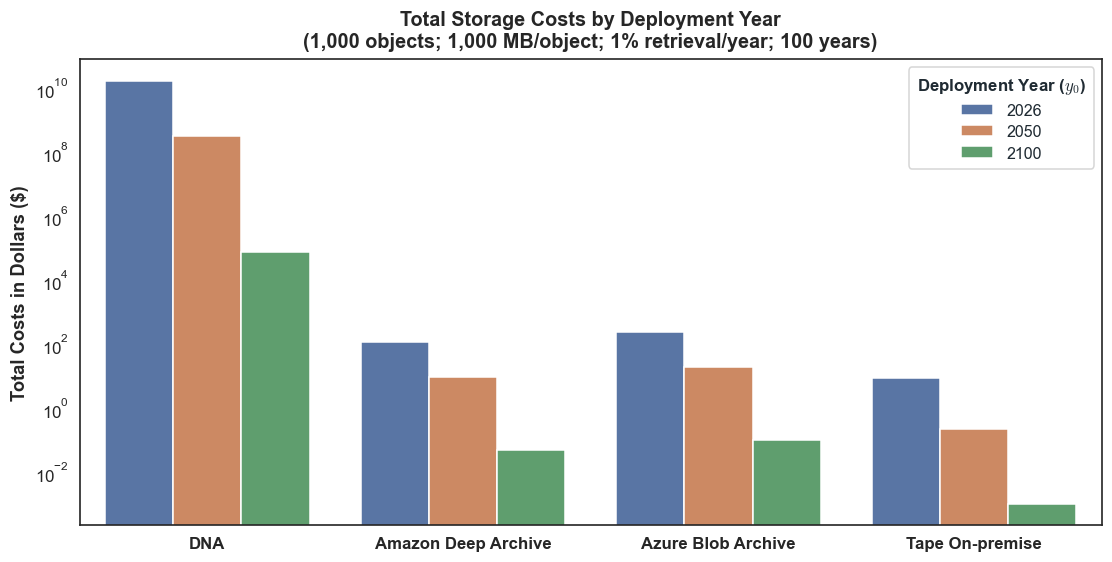

In [9]:
SAVE = True  # False previews only; True exports this figure and its data.
start_years = [BASE.start_year, 2050, 2100]
columns = ['total_cost_usd']
scenarios = {str(year): replace(BASE, start_year=year) for year in start_years}
frames = []
for year, scenario in scenarios.items():
    data = simulate_scenario(scenario).totals.copy()
    data["Start year"] = year
    data["Cost"] = data[columns].sum(axis=1)
    frames.append(data)
frame = pd.concat(frames, ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.barplot(data=frame, x="technology", y="Cost", hue="Start year", errorbar=None, ax=ax)
ax.set_yscale("log")
ax.set_title(
    "Total Storage Costs by Deployment Year\n"
    f"({BASE.number_of_assets:,.0f} objects; {BASE.average_asset_size_mb:,.0f} MB/object; "
    f"{BASE.annual_retrieval_percent:g}% retrieval/year; {BASE.horizon_years} years)",
    fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("")
ax.set_ylabel("Total Costs in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
key = ax.legend(title=r"Deployment Year ($y_0$)", loc="upper right",
                frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
                framealpha=0.8, fontsize=10.5, title_fontsize=11,
                handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
key.get_title().set_fontweight("semibold")
record("F3a_lifecycle_components", fig, "Total lifecycle cost for independent archives; " + describe(BASE), {"costs": frame}, scenarios)

## F3b: writing and storage cost by deployment year

Every deployment is an independent archive with the same retention and workload.

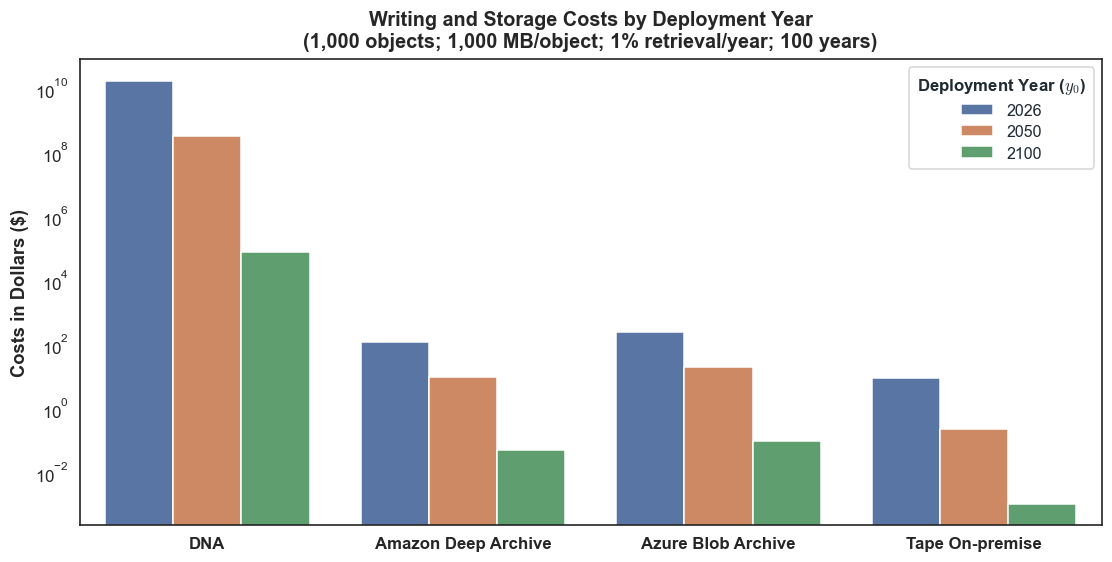

In [9]:
SAVE = True  # False previews only; True exports this figure and its data.
start_years = [BASE.start_year, 2050, 2100]
columns = ['write_cost_usd', 'maintenance_cost_usd']
scenarios = {str(year): replace(BASE, start_year=year) for year in start_years}
frames = []
for year, scenario in scenarios.items():
    data = simulate_scenario(scenario).totals.copy()
    data["Start year"] = year
    data["Cost"] = data[columns].sum(axis=1)
    frames.append(data)
frame = pd.concat(frames, ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.barplot(data=frame, x="technology", y="Cost", hue="Start year", errorbar=None, ax=ax)
ax.set_yscale("log")
ax.set_title(
    "Writing and Storage Costs by Deployment Year\n"
    f"({BASE.number_of_assets:,.0f} objects; {BASE.average_asset_size_mb:,.0f} MB/object; "
    f"{BASE.annual_retrieval_percent:g}% retrieval/year; {BASE.horizon_years} years)",
    fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("")
ax.set_ylabel("Costs in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
key = ax.legend(title=r"Deployment Year ($y_0$)", loc="upper right",
                frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
                framealpha=0.8, fontsize=10.5, title_fontsize=11,
                handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
key.get_title().set_fontweight("semibold")
record("F3b_lifecycle_components", fig, "Writing and storage cost for independent archives; " + describe(BASE), {"costs": frame}, scenarios)

## F3c: retrieval and storage cost by deployment year

Every deployment is an independent archive with the same retention and workload.

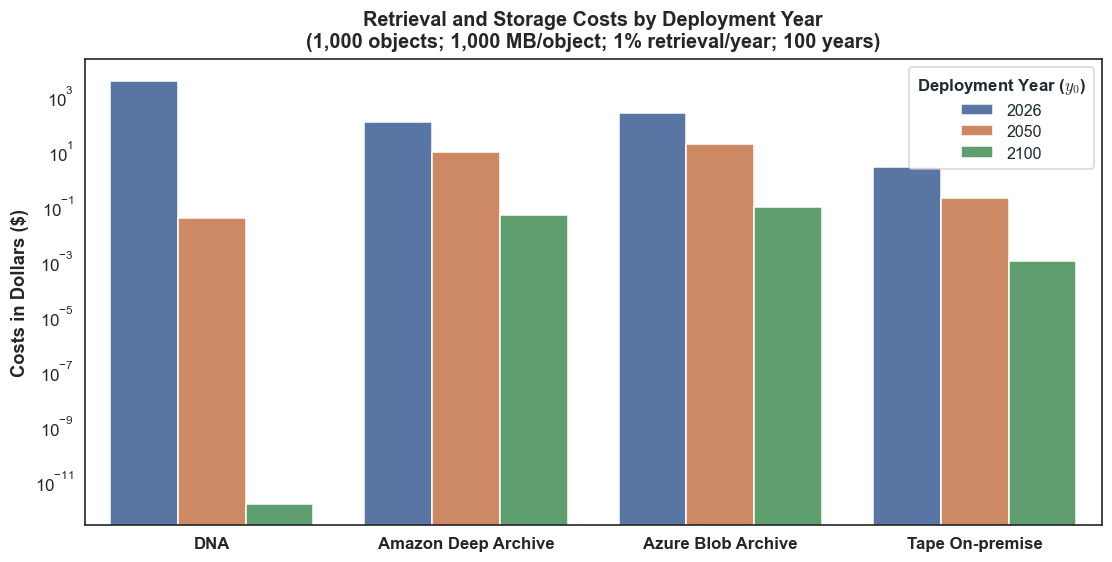

In [10]:
SAVE = True  # False previews only; True exports this figure and its data.
start_years = [BASE.start_year, 2050, 2100]
columns = ['read_cost_usd', 'maintenance_cost_usd']
scenarios = {str(year): replace(BASE, start_year=year) for year in start_years}
frames = []
for year, scenario in scenarios.items():
    data = simulate_scenario(scenario).totals.copy()
    data["Start year"] = year
    data["Cost"] = data[columns].sum(axis=1)
    frames.append(data)
frame = pd.concat(frames, ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.barplot(data=frame, x="technology", y="Cost", hue="Start year", errorbar=None, ax=ax)
ax.set_yscale("log")
ax.set_title(
    "Retrieval and Storage Costs by Deployment Year\n"
    f"({BASE.number_of_assets:,.0f} objects; {BASE.average_asset_size_mb:,.0f} MB/object; "
    f"{BASE.annual_retrieval_percent:g}% retrieval/year; {BASE.horizon_years} years)",
    fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("")
ax.set_ylabel("Costs in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
key = ax.legend(title=r"Deployment Year ($y_0$)", loc="upper right",
                frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
                framealpha=0.8, fontsize=10.5, title_fontsize=11,
                handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
key.get_title().set_fontweight("semibold")
record("F3c_lifecycle_components", fig, "Retrieval and storage cost for independent archives; " + describe(BASE), {"costs": frame}, scenarios)

## F4a: start-year outlook

Includes the original target-year guide curves. These interpolate total costs geometrically; they do not solve for a feasible synthesis decline rate.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F4a_start_year_outlook: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


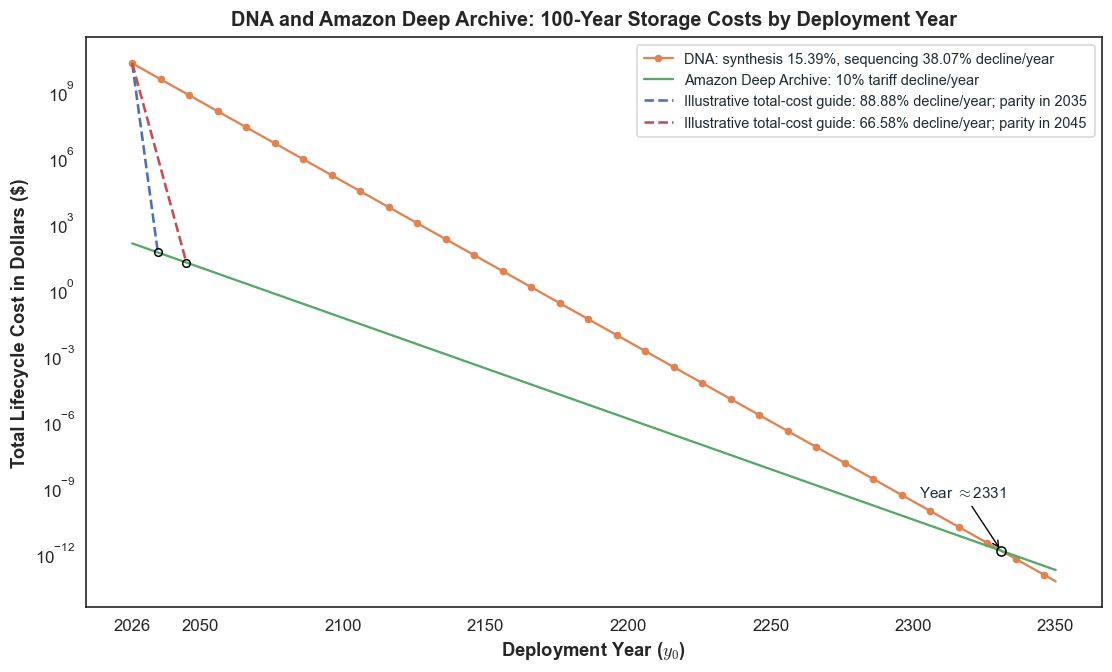

In [13]:
SAVE = True  # False previews only; True exports this figure and its data.
final_year = 2350
target_years = [2035, 2045]
scenario = replace(BASE, technologies=("DNA", "Amazon Deep Archive"))
frame = simulate_start_years(scenario, final_year)
pivot = frame.pivot(index="start_year", columns="technology", values="total_cost_usd")
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
ax.plot(pivot.index, pivot.DNA, color=PALETTE[1], lw=1.5, marker="o", markevery=10, ms=4,
        label=f"DNA: synthesis {BASE.synthesis_decline_percent:.2f}%, sequencing {BASE.sequencing_decline_percent:.2f}% decline/year")
ax.plot(pivot.index, pivot["Amazon Deep Archive"], color=PALETTE[2], lw=1.5,
        label=f"Amazon Deep Archive: {BASE.amazon_decline_percent:g}% tariff decline/year")
guides = []
for index, target in enumerate(target_years):
    if not BASE.start_year < target <= final_year:
        raise ValueError("Target year must follow the baseline and lie within the outlook.")
    years = np.arange(BASE.start_year, target + 1)
    values = np.geomspace(pivot.DNA.iloc[0], pivot.loc[target, "Amazon Deep Archive"], len(years))
    guide_decline = 100 * (1 - (values[-1] / values[0]) ** (1 / (target - BASE.start_year)))
    ax.plot(years, values, ls="--", lw=1.7, color=(PALETTE[0], PALETTE[3])[index % 2],
            label=f"Illustrative total-cost guide: {guide_decline:.2f}% decline/year; parity in {target}")
    ax.plot(target, values[-1], "o", ms=5, mfc="none", mec="black", mew=1, zorder=5)
    guides.append(pd.DataFrame({"year": years, "target": target, "cost_usd": values,
                               "total_cost_decline_percent": guide_decline}))
crossings = []
ratio = np.log(pivot.DNA.to_numpy() / pivot["Amazon Deep Archive"].to_numpy())
candidates = np.flatnonzero(ratio <= 0)
if len(candidates) and candidates[0] > 0:
    i = candidates[0]
    year = pivot.index[i - 1] + ratio[i - 1] / (ratio[i - 1] - ratio[i])
    cost = np.exp(np.interp(year, pivot.index, np.log(pivot["Amazon Deep Archive"])))
    ax.plot(year, cost, "o", ms=6, mfc="none", mec="black", mew=1, zorder=5)
    ax.annotate(rf"Year $\approx${year:.0f}", (year, cost), xytext=(-25, 35),
                textcoords="offset points", ha="center", fontsize=10,
                arrowprops={"arrowstyle": "->", "lw": 0.9, "color": "black"})
    crossings.append({"parity_year": year, "cost_usd": cost})
ax.set_yscale("log")
ax.set_xticks(sorted({BASE.start_year, 2050, *range(2100, final_year + 1, 50)}))
ax.set_title(f"DNA and Amazon Deep Archive: {BASE.horizon_years}-Year Storage Costs by Deployment Year", fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel(r"Deployment Year ($y_0$)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Total Lifecycle Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.legend(loc="upper right", frameon=True, fancybox=True, facecolor="white",
          edgecolor="0.8", framealpha=0.8, fontsize=9.5, handlelength=2,
          handletextpad=0.8, labelspacing=0.5, borderpad=0.5)
record("F4a_start_year_outlook", fig,
       "Independent archive deployments with fixed workload and retention. DNA legend rates apply to synthesis and sequencing unit prices; Amazon's rate applies to all tariffs. "
       "Dashed guides interpolate total lifecycle costs geometrically to Amazon parity in the labeled target year. Their percentages describe reductions in total cost per year of delayed deployment, not synthesis or sequencing decline rates, fitted forecasts, or solved technology trajectories.",
       {"costs": frame, "guides": pd.concat(guides), "crossings": pd.DataFrame(crossings)}, {"baseline": scenario})

## F4b: lifecycle costs around parity

Selects three deployments around the first start-year parity; it does not hard-code obsolete crossover years.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F4b_lifecycle_near_parity: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


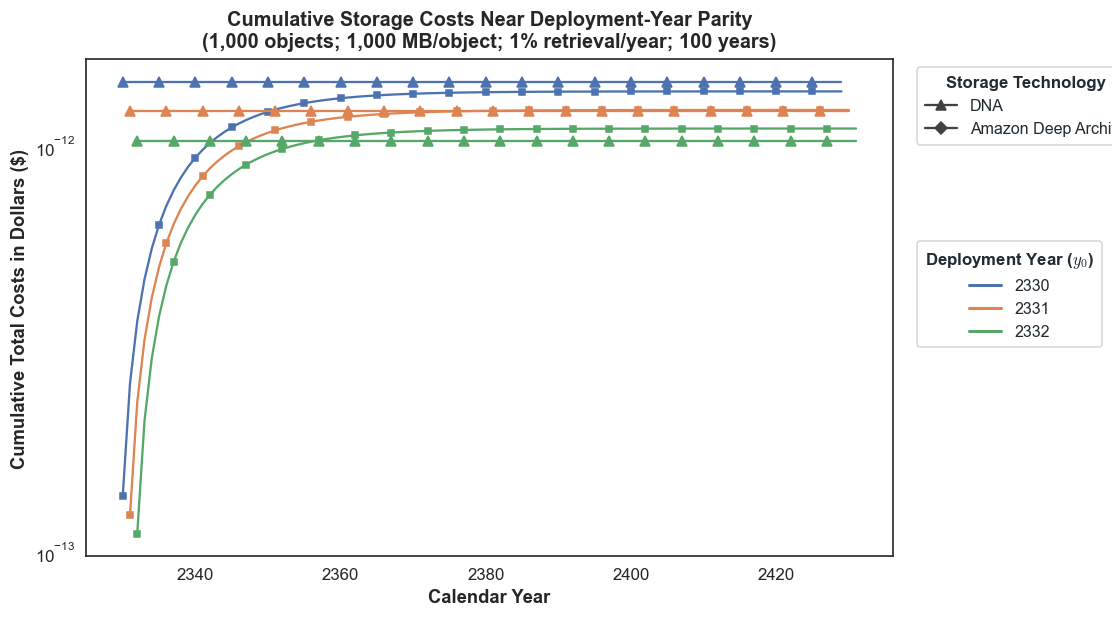

In [16]:
SAVE = True  # False previews only; True exports this figure and its data.
scenario = replace(BASE, technologies=("DNA", "Amazon Deep Archive"))
crossing = find_crossover_years(simulate_start_years(scenario, 2500))["Amazon Deep Archive"]
center = crossing if crossing is not None else FUTURE_START
start_years = sorted(set(max(BASE.start_year, min(2500, center + offset)) for offset in (-1, 0, 1)))
scenarios = {str(year): replace(scenario, start_year=year) for year in start_years}
frames = []
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
for index, (year, current) in enumerate(scenarios.items()):
    data = simulate_scenario(current).yearly.copy()
    data["deployment"] = year
    for name, part in data.groupby("technology", sort=False):
        ax.plot(part.year, part.total_cost_usd.cumsum(), color=PALETTE[index],
                ls="-", lw=1.5, marker="^" if name == "DNA" else "s",
                markersize=6 if name == "DNA" else 4, markevery=5, label=f"{year}: {name}")
    frames.append(data)
ax.set_yscale("log")
ax.set_title("Cumulative Storage Costs Near Deployment-Year Parity\n"
             f"({BASE.number_of_assets:,.0f} objects; {BASE.average_asset_size_mb:,.0f} MB/object; "
             f"{BASE.annual_retrieval_percent:g}% retrieval/year; {BASE.horizon_years} years)",
             fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("Calendar Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cumulative Total Costs in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
technology_handles = [Line2D([], [], color="0.25", marker=marker, lw=1.5,
                             markersize=6, label=name)
                      for name, marker in (("DNA", "^"), ("Amazon Deep Archive", "s"))]
year_handles = [Line2D([], [], color=PALETTE[index], lw=2, label=year)
                for index, year in enumerate(scenarios)]
options = dict(loc="upper left", frameon=True, fancybox=True, facecolor="white",
               edgecolor="0.8", framealpha=0.8, fontsize=10.5, title_fontsize=11,
               handlelength=2, handletextpad=0.8, labelspacing=0.5, borderpad=0.5)
technology_key = ax.legend(handles=technology_handles, title="Storage Technology",
                           bbox_to_anchor=(1.02, 1), **options)
technology_key.get_title().set_fontweight("semibold")
ax.add_artist(technology_key)
year_key = ax.legend(handles=year_handles, title=r"Deployment Year ($y_0$)",
                     bbox_to_anchor=(1.02, 0.65), **options)
year_key.get_title().set_fontweight("semibold")
record("F4b_lifecycle_near_parity", fig, "Three independent archive deployments near first sampled start-year parity; fallback to the configured future year if none exists.", {"annual_costs": pd.concat(frames)}, scenarios)

## F5a: encoding density and address overhead

Retains the legacy multiplicative overhead convention. The physical range is limited to at most 2 bits/base; prices are scaled relative to the model's 4 bases/byte convention.

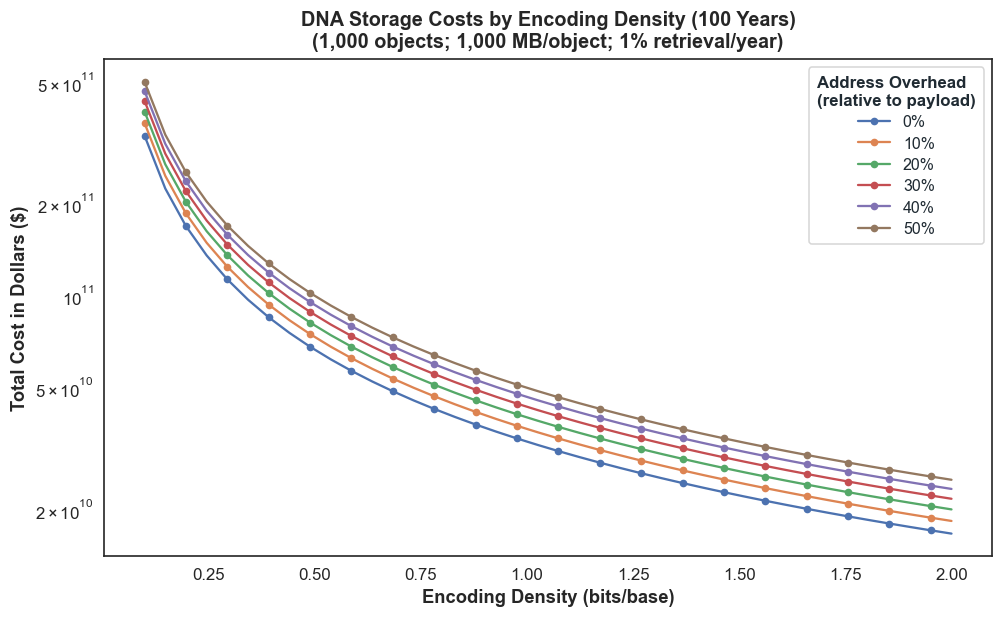

In [15]:
SAVE = True  # False previews only; True exports this figure and its data.
bits_per_base = np.linspace(0.1, 2.0, 40)
overhead_percentages = [0, 10, 20, 30, 40, 50]
copies = 1
baseline_cost = totals(replace(BASE, technologies=("DNA",)))["DNA"]
rows = []
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
for overhead in overhead_percentages:
    multiplier = 2 / bits_per_base * copies * (1 + overhead / 100)
    costs = baseline_cost * multiplier
    ax.plot(bits_per_base, costs, label=f"{overhead}%", ls="-", lw=1.5,
            marker="o", markersize=4, markevery=2)
    rows.extend({"bits_per_base": b, "overhead_percent": overhead, "copies": copies, "cost_usd": c} for b, c in zip(bits_per_base, costs))
ax.set_yscale("log")
ax.set_title(f"DNA Storage Costs by Encoding Density ({BASE.horizon_years} Years)\n"
             f"({BASE.number_of_assets:,.0f} objects; {BASE.average_asset_size_mb:,.0f} MB/object; "
             f"{BASE.annual_retrieval_percent:g}% retrieval/year)",
             fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("Encoding Density (bits/base)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Total Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5), numticks=12))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation(
    base=10, labelOnlyBase=False, minor_thresholds=(np.inf, np.inf)))
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
key = ax.legend(title="Address Overhead\n(relative to payload)", loc="upper right",
                frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
                framealpha=0.8, fontsize=10.5, title_fontsize=11,
                handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
key.get_title().set_fontweight("semibold")
record("F5a_encoding_overhead", fig, "DNA costs scaled by (2 / bits per base) * copies * (1 + address overhead / 100), following the legacy convention; overhead is relative to payload, not a fraction of total oligo length.", {"costs": pd.DataFrame(rows)}, {"baseline": BASE})

## F5b: index length (bases)

Uses the existing oligo-addressing helper on only the plotted combinations. Object count varies, so total archive size varies too; primers/indexes retain the original convention.

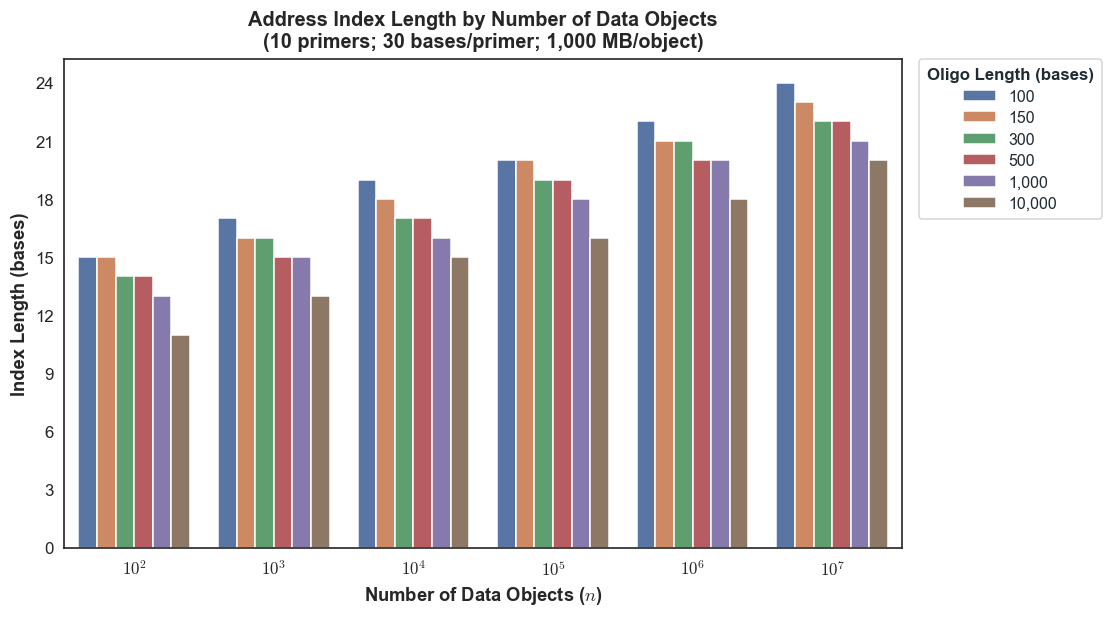

In [17]:
SAVE = True  # False previews only; True exports this figure and its data.
primer_count = 10
primer_bases = 30
oligo_sizes = (100, 150, 300, 500, 1000, 10000)
frame = addressing_table(BASE, primer_count, primer_bases, oligo_sizes)
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
sns.barplot(data=frame, x="Objects", y='Index Size', hue="Oligo bases", errorbar=None, ax=ax)

ax.set_xticks(range(6), [r"$10^{%d}$" % power for power in range(2, 8)])
ax.set_title("Address Index Length by Number of Data Objects\n"
             f"({primer_count} primers; {primer_bases} bases/primer; {BASE.average_asset_size_mb:,.0f} MB/object)",
             fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel(r"Number of Data Objects ($n$)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Index Length (bases)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
handles, labels = ax.get_legend_handles_labels()
key = ax.legend(handles, [f"{int(label):,}" for label in labels], title="Oligo Length (bases)",
                loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0,
                frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
                framealpha=0.8, fontsize=10.5, title_fontsize=11,
                handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
key.get_title().set_fontweight("semibold")
record("F5b_addressing", fig, "Legacy oligo-level addressing calculation at the configured deployment-year synthesis price; archive size varies with object count.", {"addressing": frame}, {"baseline": BASE})

## F5c: initial synthesis cost (usd)

Uses the existing oligo-addressing helper on only the plotted combinations. Object count varies, so total archive size varies too; primers/indexes retain the original convention.

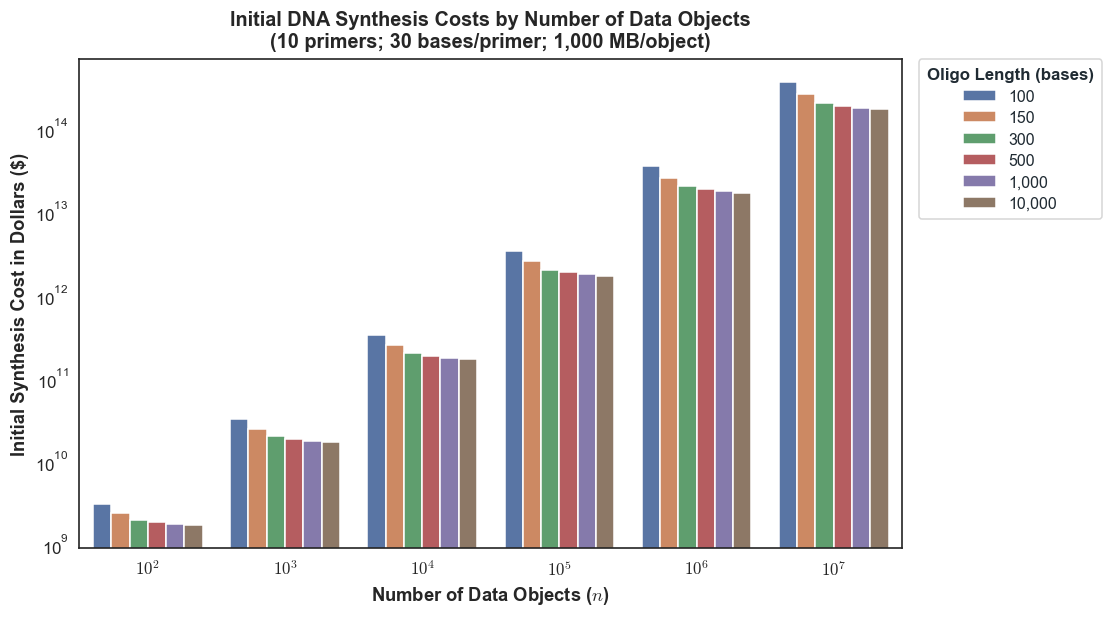

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
primer_count = 10
primer_bases = 30
oligo_sizes = (100, 150, 300, 500, 1000, 10000)
frame = addressing_table(BASE, primer_count, primer_bases, oligo_sizes)
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
sns.barplot(data=frame, x="Objects", y='Total Synthesis Cost', hue="Oligo bases", errorbar=None, ax=ax)
ax.set_yscale("log")
ax.set_xticks(range(6), [r"$10^{%d}$" % power for power in range(2, 8)])
ax.set_title("Initial DNA Synthesis Costs by Number of Data Objects\n"
             f"({primer_count} primers; {primer_bases} bases/primer; {BASE.average_asset_size_mb:,.0f} MB/object)",
             fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel(r"Number of Data Objects ($n$)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Initial Synthesis Cost in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for label in ax.get_xticklabels():
    label.set_fontweight("bold")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
handles, labels = ax.get_legend_handles_labels()
key = ax.legend(handles, [f"{int(label):,}" for label in labels], title="Oligo Length (bases)",
                loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0,
                frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
                framealpha=0.8, fontsize=10.5, title_fontsize=11,
                handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
key.get_title().set_fontweight("semibold")
record("F5c_addressing", fig, "Legacy oligo-level addressing calculation at the configured deployment-year synthesis price; archive size varies with object count.", {"addressing": frame}, {"baseline": BASE})

## F6a: historical synthesis fit

Refits the historical observations embedded in Figures.ipynb. This diagnostic does not replace the economic model's established synthesis fit.

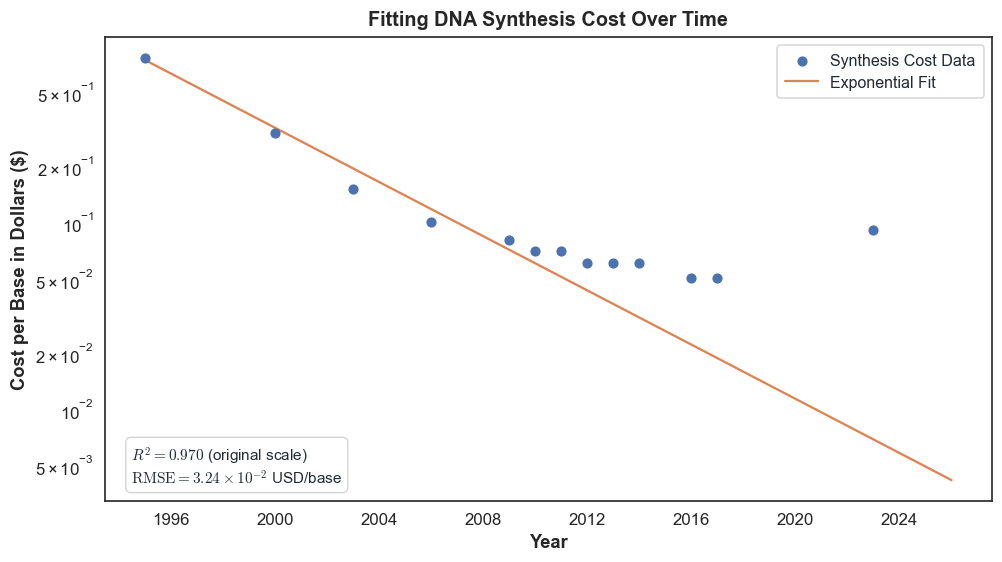

In [20]:
SAVE = True  # False previews only; True exports this figure and its data.
years = np.array([1995, 2000, 2003, 2006, 2009, 2010, 2011, 2012, 2013, 2014, 2016, 2017, 2023])
costs = np.array([0.75, 0.30, 0.15, 0.10, 0.08, 0.07, 0.07, 0.06, 0.06, 0.06, 0.05, 0.05, 0.09])
def fit_function(year, amplitude, coefficient):
    return amplitude * np.exp(-coefficient * (year - 1995))
parameters, _ = curve_fit(fit_function, years, costs, p0=[1, 0.1])
predicted = fit_function(years, *parameters)
rmse = np.sqrt(np.mean((costs - predicted)**2))
r2 = 1 - np.sum((costs - predicted)**2) / np.sum((costs - costs.mean())**2)
fine_years = np.linspace(years.min(), BASE.start_year, 250)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.scatter(years, costs, label="Synthesis Cost Data", color=PALETTE[0], s=32, zorder=3)
ax.plot(fine_years, fit_function(fine_years, *parameters), label="Exponential Fit", color=PALETTE[1], lw=1.5)
ax.set_yscale("log")
ax.set_title("Fitting DNA Synthesis Cost Over Time", fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cost per Base in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.legend(loc="upper right", frameon=True, fancybox=True, facecolor="white",
          edgecolor="0.8", framealpha=0.8, fontsize=10.5,
          handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
mantissa, exponent = f"{rmse:.2e}".split("e")
metrics = (rf"$R^2 = {r2:.3f}$" + " (original scale)\n"
           + rf"$\mathrm{{RMSE}} = {mantissa}\times10^{{{int(exponent)}}}$" + " USD/base")
ax.text(0.03, 0.03, metrics, transform=ax.transAxes, ha="left", va="bottom", fontsize=10,
        bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "0.8",
              "linewidth": 0.8, "alpha": 0.92})
ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5), numticks=12))
ax.yaxis.set_major_formatter(mpl.ticker.LogFormatterSciNotation(base=10, labelOnlyBase=False, minor_thresholds=(np.inf, np.inf)))
caption = f"Legacy synthesis observations; nonlinear least-squares refit in original units. R2={r2:.4f}; RMSE={rmse:.6g} USD/base. This refit is not substituted into the economic model."
record("F6a_synthesis_fit", fig, caption, {"observations": pd.DataFrame({"year": years, "cost_usd_per_base": costs, "fitted": predicted}), "fit": pd.DataFrame({"year": fine_years, "cost_usd_per_base": fit_function(fine_years, *parameters)})}, {"baseline": BASE})

## F6b: historical sequencing fit

Uses the local NHGRI CSV. Units are USD per million sequenced bases (Mb), not USD per logical MB of stored data.

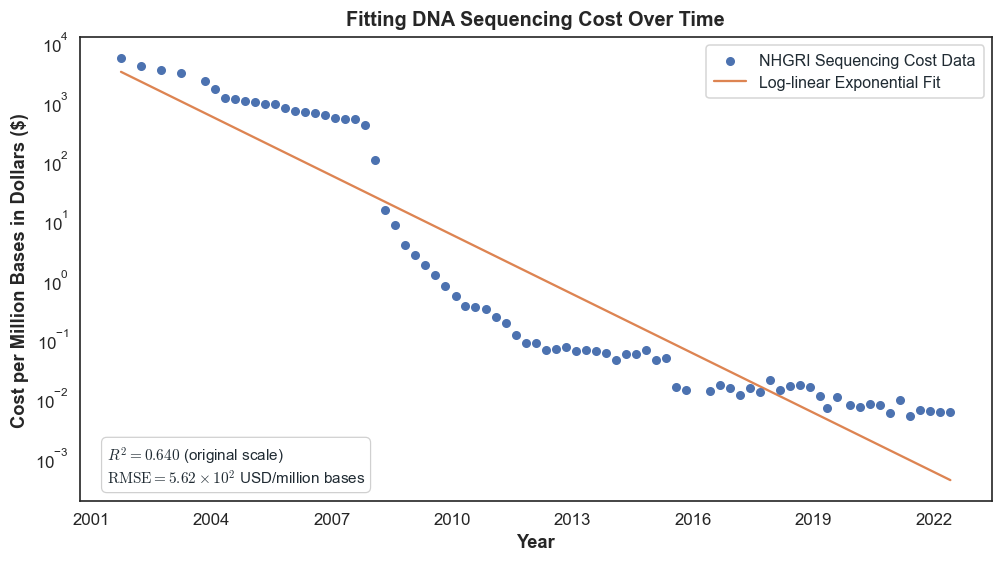

In [21]:
SAVE = True  # False previews only; True exports this figure and its data.
frame = load_observed_sequencing_costs().copy()
years = frame.year.to_numpy()
costs = frame.sequencing_cost_usd_per_mb.to_numpy()
origin = years.min()
slope, intercept = np.polyfit(years - origin, np.log(costs), 1)
fine_years = np.linspace(years.min(), years.max(), 250)
fit_costs = np.exp(intercept + slope * (fine_years - origin))
predicted = np.exp(intercept + slope * (years - origin))
rmse = np.sqrt(np.mean((costs - predicted)**2))
r2 = 1 - np.sum((costs - predicted)**2) / np.sum((costs - costs.mean())**2)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.scatter(years, costs, label="NHGRI Sequencing Cost Data", color=PALETTE[0], s=24, zorder=3)
ax.plot(fine_years, fit_costs, label="Log-linear Exponential Fit", color=PALETTE[1], lw=1.5)
ax.set_yscale("log")
ax.set_title("Fitting DNA Sequencing Cost Over Time", fontsize=13, fontweight="bold", color="0.15", pad=8)
ax.set_xlabel("Year", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.set_ylabel("Cost per Million Bases in Dollars ($)", fontsize=12, fontweight="bold", color="0.15", labelpad=4)
ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
ax.grid(False, which="both")
ax.tick_params(axis="both", which="major", labelsize=11, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
ax.legend(loc="upper right", frameon=True, fancybox=True, facecolor="white",
          edgecolor="0.8", framealpha=0.8, fontsize=10.5,
          handlelength=2, handletextpad=0.8, labelspacing=0.4, borderpad=0.5)
mantissa, exponent = f"{rmse:.2e}".split("e")
metrics = (rf"$R^2 = {r2:.3f}$" + " (original scale)\n"
           + rf"$\mathrm{{RMSE}} = {mantissa}\times10^{{{int(exponent)}}}$" + " USD/million bases")
ax.text(0.03, 0.03, metrics, transform=ax.transAxes, ha="left", va="bottom", fontsize=10,
        bbox={"boxstyle": "round,pad=0.35", "facecolor": "white", "edgecolor": "0.8",
              "linewidth": 0.8, "alpha": 0.92})
caption = f"NHGRI local observations, nominal USD at reporting dates; log-linear refit. Original-scale R2={r2:.4f}; RMSE={rmse:.6g} USD per million bases. Model fit unchanged."
record("F6b_sequencing_fit", fig, caption, {"observations": frame, "fit": pd.DataFrame({"year": fine_years, "cost_usd_per_million_bases": fit_costs})}, {"baseline": BASE})

# Sensitivity figures

The following figure code is carried over from the sensitivity notebook, using the shared 2026 baseline and export controls above. Each cell is independent of the other figure cells.

## M1 — proposed main figure: what drives DNA lifecycle cost?

Two tornado panels compare the configured baseline start year with a future deployment year. The horizontal coordinate is **cost divided by that panel's baseline cost**, on a logarithmic axis; the dashed line is 1. Low and high refer to the **input**, not to the resulting cost. Each input varies by ±50% while the others remain fixed. The zero baseline discount rate uses the calculator's 0–5% fallback, but has no effect here because costs are undiscounted.

A factor-of-two difference remains visible while the much stronger future sensitivity to synthesis decline fits on the same axis. Tiny effects should be read from the CSV, not interpreted as exact zero. The notebook does not describe these perturbations as an uncertainty interval.

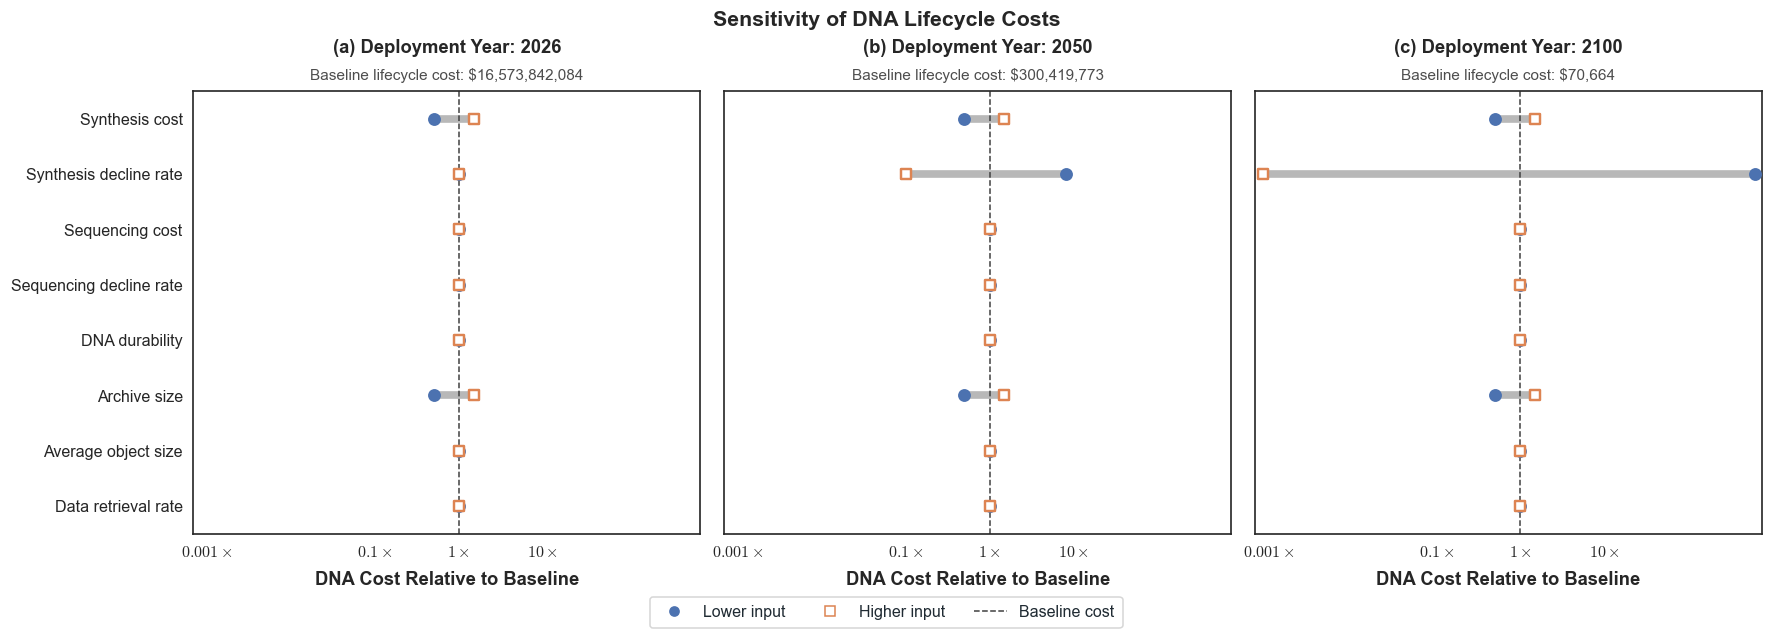

In [24]:
SAVE = True  # False previews only; True exports this figure and its data.
m1_scenarios = {"baseline": BASE, "future": replace(BASE, start_year=FUTURE_START),
                "2100": replace(BASE, start_year=2100)}
frames = []
for label, scenario in m1_scenarios.items():
    frame = dna_cost_sensitivity(scenario, use_present_value=False)
    frame = frame[frame.parameter != "Discount rate"].copy()
    frame["scenario"] = label
    frame["start_year"] = scenario.start_year
    frame["low_ratio"] = frame.low_cost / frame.baseline_cost
    frame["high_ratio"] = frame.high_cost / frame.baseline_cost
    frames.append(frame)
m1 = pd.concat(frames, ignore_index=True)
order = [
    "Synthesis cost", "Synthesis decline rate",
    "Sequencing cost", "Sequencing decline rate",
    "DNA durability", "Archive size", "Average asset size", "Annual retrieval",
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.7), sharey=True, layout="constrained")
for index, ((label, scenario), ax) in enumerate(zip(m1_scenarios.items(), axes)):
    frame = m1[m1.scenario == label].set_index("parameter").loc[order]
    for y, row in enumerate(frame.itertuples()):
        ax.plot([row.low_ratio, row.high_ratio], [y, y], color="0.72", lw=5,
                solid_capstyle="butt", zorder=1)
        ax.scatter(row.low_ratio, y, marker="o", s=55, color=PALETTE[0], zorder=3)
        ax.scatter(row.high_ratio, y, marker="s", s=48, facecolor="white",
                   edgecolor=PALETTE[1], linewidth=1.6, zorder=4)
    ax.axvline(1, color="0.25", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_xticks([0.001, 0.1, 1, 10, 1000])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: rf"${x:g}\times$"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(min(0.08, m1[["low_ratio", "high_ratio"]].min().min() * 0.8),
                max(12, m1[["low_ratio", "high_ratio"]].max().max() * 1.2))
    ax.set_yticks(range(len(order)), [p.replace("Average asset size", "Average object size").replace("Annual retrieval", "Data retrieval rate") for p in order])
    ax.set_ylim(len(order) - 0.5, -0.5)
    cost = frame.baseline_cost.iloc[0]
    ax.set_title(f"({chr(97 + index)}) Deployment Year: {scenario.start_year}",
                 fontsize=12, fontweight="bold", color="0.15", pad=25)
    ax.text(0.5, 1.025, f"Baseline lifecycle cost: ${cost:,.0f}",
            transform=ax.transAxes, fontsize=10, ha="center", color="0.3")
    ax.set_xlabel("DNA Cost Relative to Baseline", fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    ax.grid(False, which="both")
    ax.tick_params(axis="both", which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
handles = [
    Line2D([], [], marker="o", color=PALETTE[0], ls="", label="Lower input"),
    Line2D([], [], marker="s", markerfacecolor="white", color=PALETTE[1], ls="", label="Higher input"),
]
handles.append(Line2D([], [], color="0.25", ls="--", lw=1, label="Baseline cost"))
fig.suptitle("Sensitivity of DNA Lifecycle Costs", fontsize=14, fontweight="bold", color="0.15")
fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=True,
           fancybox=True, facecolor="white", edgecolor="0.8", framealpha=0.8,
           fontsize=10.5, handlelength=2, handletextpad=0.8, borderpad=0.5)
record("M1_dna_cost_sensitivity", fig,
       f"One-at-a-time sensitivity of DNA lifecycle cost for archives starting in {BASE.start_year}, "
       f"{FUTURE_START}, and 2100. Workload: {describe(BASE)}. Inputs vary by +/-50%. Data retrieval rate is the percentage of archive volume retrieved per year. "
       "Discount rate is omitted because costs here are undiscounted. Inputs appear in a fixed order across deployment years. Symbols identify lower and higher "
       "inputs, while connecting segments span their costs. Each panel is normalized to its own "
       "baseline (dashed line); the horizontal scale is logarithmic. DNA prices are anchored in "
       f"{BASE.dna_cost_base_year}. Small or overlapping effects are quantified in the accompanying CSV.",
       {"sensitivity": m1}, m1_scenarios)

## S1 — DNA cost advantage: synthesis price and retrieval

This reproduces the calculator's **DNA cost advantage** analysis with a common nonnegative price axis. Positive \(C_{\mathrm{comparison}}-C_{\mathrm{DNA}}\) favours DNA. Panel (a) uses the baseline workload; panel (b) changes only retrieval to 0.001%/year. The second panel is a conditional rare-access case, not a new baseline.

The displayed range is near hypothetical break-even prices and is far below the fitted synthesis price. Unreachable parity at nonnegative prices is explicitly retained. CSVs include gains and both underlying lifecycle costs.

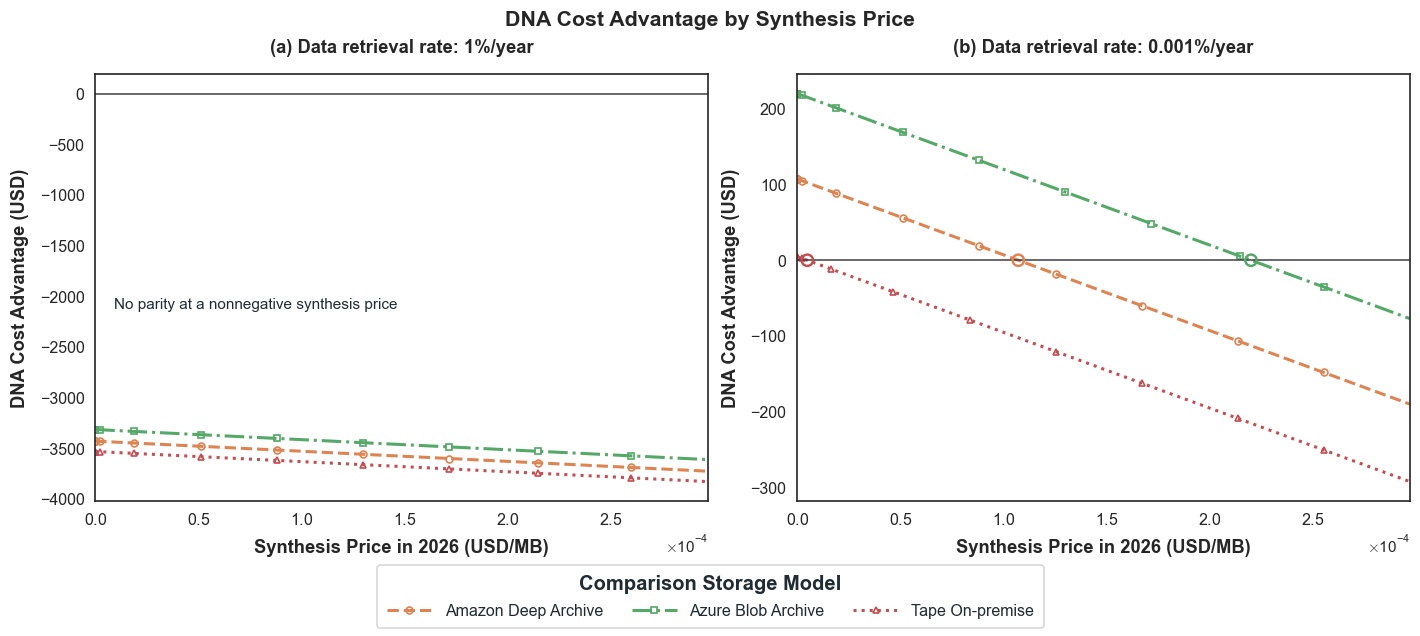

In [25]:
SAVE = True  # False previews only; True exports this figure and its data.
s1_scenarios = {"baseline": BASE, "rare_retrieval": replace(BASE, annual_retrieval_percent=RARE_RETRIEVAL)}
rare_thresholds = threshold_at_start(s1_scenarios["rare_retrieval"])
positive = rare_thresholds.threshold_start_usd_per_mb.dropna()
price_max = float(positive.max() * 1.35) if len(positive) else 0.001
factor = (1 - BASE.synthesis_decline_percent / 100) ** (BASE.start_year - BASE.dna_cost_base_year)
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.7), layout="constrained")
curves, crossings = [], []
for index, ((label, scenario), ax) in enumerate(zip(s1_scenarios.items(), axes)):
    for tech in PEERS:
        result = dna_cost_advantage(
            scenario, "dna_synthesis_cost_per_mb", tech, False,
            focus=False, x_range=(0.0, price_max / factor),
        )
        frame = result.curve.copy()
        frame["price_at_start_usd_per_mb"] = frame.parameter_value * factor
        frame["scenario"] = label
        curves.append(frame)
        ax.plot(frame.price_at_start_usd_per_mb, frame.gain_usd,
                label=tech, color=COLORS[tech], ls=STYLES[tech])
        for crossing in result.crossings:
            if crossing.value >= 0:
                price = crossing.value * factor
                ax.scatter(price, 0, color=COLORS[tech], s=40, zorder=5)
                crossings.append({"scenario": label, "technology": tech,
                                  "threshold_start_usd_per_mb": price})
    ax.axhline(0, color="0.25", lw=1)
    ax.ticklabel_format(axis="x", style="sci", scilimits=(0, 0), useMathText=True)
    ax.set_xlim(0, price_max)
    tidy(ax, f"Synthesis Price in {BASE.start_year} (USD/MB)",
         "DNA Cost Advantage (USD)",
         f"({chr(97 + index)}) Data retrieval rate: {scenario.annual_retrieval_percent:g}%/year")
    if label == "baseline" and not threshold_at_start(scenario).reachable.any():
        ax.text(0.03, 0.45, "No parity at a nonnegative synthesis price",
                transform=ax.transAxes, fontsize=10)


for ax in axes:
    ax.grid(False, which="both")
    ax.tick_params(axis="both", which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
    ax.set_xlabel(ax.get_xlabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    ax.set_ylabel(ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    panel_title = ax.get_title(loc="left")
    ax.set_title("", loc="left")
    ax.set_title(panel_title, fontsize=12, fontweight="bold", color="0.15", pad=14)
    for line, marker in zip(ax.lines[:3], ("o", "s", "^")):
        line.set_linewidth(2)
        line.set_marker(marker)
        line.set_markersize(4.5)
        line.set_markerfacecolor("none")
        line.set_markeredgewidth(1.1)
        line.set_markevery(max(1, len(line.get_xdata()) // 12))
    for collection in ax.collections:
        collection.set_sizes([55])
        collection.set_facecolor("none")
        collection.set_linewidth(1.6)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle('DNA Cost Advantage by Synthesis Price', fontsize=14, fontweight="bold", color="0.15")
shared_legend = fig.legend(handles, labels, title='Comparison Storage Model',
           loc="outside lower center", ncol=len(handles), frameon=True,
           fancybox=True, facecolor="white", edgecolor="0.8", framealpha=0.8,
           fontsize=10.5, handlelength=2.8, handletextpad=0.8, borderpad=0.6)
shared_legend.get_title().set_fontweight("bold")
record("S1_synthesis_cost_advantage", fig,
       f"DNA cost advantage over three alternatives, defined as comparator lifecycle cost minus "
       f"DNA lifecycle cost. Baseline: {describe(BASE)}. Panel (b) changes retrieval only to "
       f"{RARE_RETRIEVAL:g}%/year. Positive values favour DNA; dots denote exact nonnegative "
       f"price thresholds. The fitted synthesis price is USD {BASE.dna_synthesis_cost_per_mb:,.2f}/MB "
       f"in {BASE.dna_cost_base_year}, far outside this hypothetical price window. Sequencing and all "
       "other costs remain at their baseline trajectories. No negative-price subsidy is plotted.",
       {"curves": pd.concat(curves, ignore_index=True),
        "crossings": pd.DataFrame(crossings, columns=["scenario", "technology", "threshold_start_usd_per_mb"])},
       s1_scenarios)

## S2 — how retrieval constrains the synthesis break-even price

The vertical axis reports the **maximum nonnegative synthesis price at deployment** that makes total DNA cost equal to the comparator. Higher thresholds mean more room for synthesis cost. Beyond a curve's endpoint, sequencing alone is too expensive. Those missing values are not set to zero or joined across.

Prices are converted from the solver's anchor-year units into the labelled deployment-year units. The marked baseline retrieval remains fixed at 1%/year in both panels.

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
retrieval_grid = np.unique(np.r_[np.geomspace(1e-5, 100, 101), BASE.annual_retrieval_percent, RARE_RETRIEVAL])
s2_scenarios = {"baseline": BASE, "future": replace(BASE, start_year=FUTURE_START),
                "2100": replace(BASE, start_year=2100)}
rows = []
for label, scenario in s2_scenarios.items():
    for retrieval in retrieval_grid:
        frame = threshold_at_start(replace(scenario, annual_retrieval_percent=float(retrieval)))
        frame["scenario"] = label
        rows.append(frame)
s2 = pd.concat(rows, ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 6.7), layout="constrained")
for index, ((label, scenario), ax) in enumerate(zip(s2_scenarios.items(), axes)):
    for tech in PEERS:
        frame = s2[(s2.scenario == label) & (s2.technology == tech)].sort_values("annual_retrieval_percent")
        ax.plot(frame.annual_retrieval_percent, frame.threshold_start_usd_per_mb,
                color=COLORS[tech], ls=STYLES[tech], label=tech)
    ax.axvline(BASE.annual_retrieval_percent, color="0.4", ls=":", lw=1, label="Baseline retrieval rate")
    ax.set_xscale("log")
    ax.set_xlim(retrieval_grid.min(), retrieval_grid.max())
    ax.set_xticks([0.00001, 0.001, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.5f}".rstrip("0").rstrip(".") + "%"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_yscale("log")
    tidy(ax, "Data Retrieval Rate (% of Archive/Year)", "Break-Even Synthesis Price (USD/MB)",
         f"({chr(97 + index)}) Deployment Year $y_0$: {scenario.start_year}")

handles, labels = axes[1].get_legend_handles_labels()


for ax in axes:
    ax.grid(False, which="both")
    ax.tick_params(axis="both", which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
    ax.set_xlabel(ax.get_xlabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    ax.set_ylabel(ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    panel_title = ax.get_title(loc="left")
    ax.set_title("", loc="left")
    ax.set_title(panel_title, fontsize=12, fontweight="bold", color="0.15", pad=14)
    for line, marker in zip(ax.lines[:3], ("o", "s", "^")):
        line.set_linewidth(2)
        line.set_marker(marker)
        line.set_markersize(4.5)
        line.set_markerfacecolor("none")
        line.set_markeredgewidth(1.1)
        line.set_markevery(max(1, len(line.get_xdata()) // 12))
    for collection in ax.collections:
        collection.set_sizes([55])
        collection.set_facecolor("none")
        collection.set_linewidth(1.6)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle("Break-even Synthesis Price by Data Retrieval Rate",
             fontsize=14, fontweight="bold", color="0.15")
shared_legend = fig.legend(handles, labels, title="Comparison Storage Model",
           loc="outside lower center", ncol=len(handles), frameon=True,
           fancybox=True, facecolor="white", edgecolor="0.8", framealpha=0.8,
           fontsize=10.5, handlelength=2.8, handletextpad=0.8, borderpad=0.6)
shared_legend.get_title().set_fontweight("bold")
from matplotlib.offsetbox import TextArea
legend_note = TextArea('Curves ending before 100% retrieval: at higher retrieval rates, even free synthesis cannot achieve parity.', textprops={"fontsize": 9, "fontstyle": "italic",
                                      "fontweight": "normal", "color": "0.3"})
legend_note.set_figure(fig)
# Pack both text styles inside the legend so constrained layout reserves their space.
shared_legend._legend_box.get_children().insert(0, legend_note)

record("S2_retrieval_vs_synthesis_threshold", fig,
       f"Maximum synthesis price at archive deployment that gives lifecycle cost parity with each "
       f"alternative. Deployment years are {BASE.start_year}, {FUTURE_START}, and 2100; annual retrieval is varied "
       f"and the remaining baseline is {describe(BASE)}. The vertical dotted line marks "
       f"{BASE.annual_retrieval_percent:g}% annual retrieval. Each plotted threshold solves the full "
       "lifecycle model. When a curve ends before the 100% retrieval boundary, higher retrieval rates "
       "cannot achieve parity even with free synthesis: DNA sequencing costs alone exceed the "
       "comparator's total cost. Curves reaching the right boundary are only limited by the plotted range. "
       "Both axes are logarithmic.",
       {"thresholds": s2}, s2_scenarios)


## S2b: retrieval vs. synthesis decline needed for parity

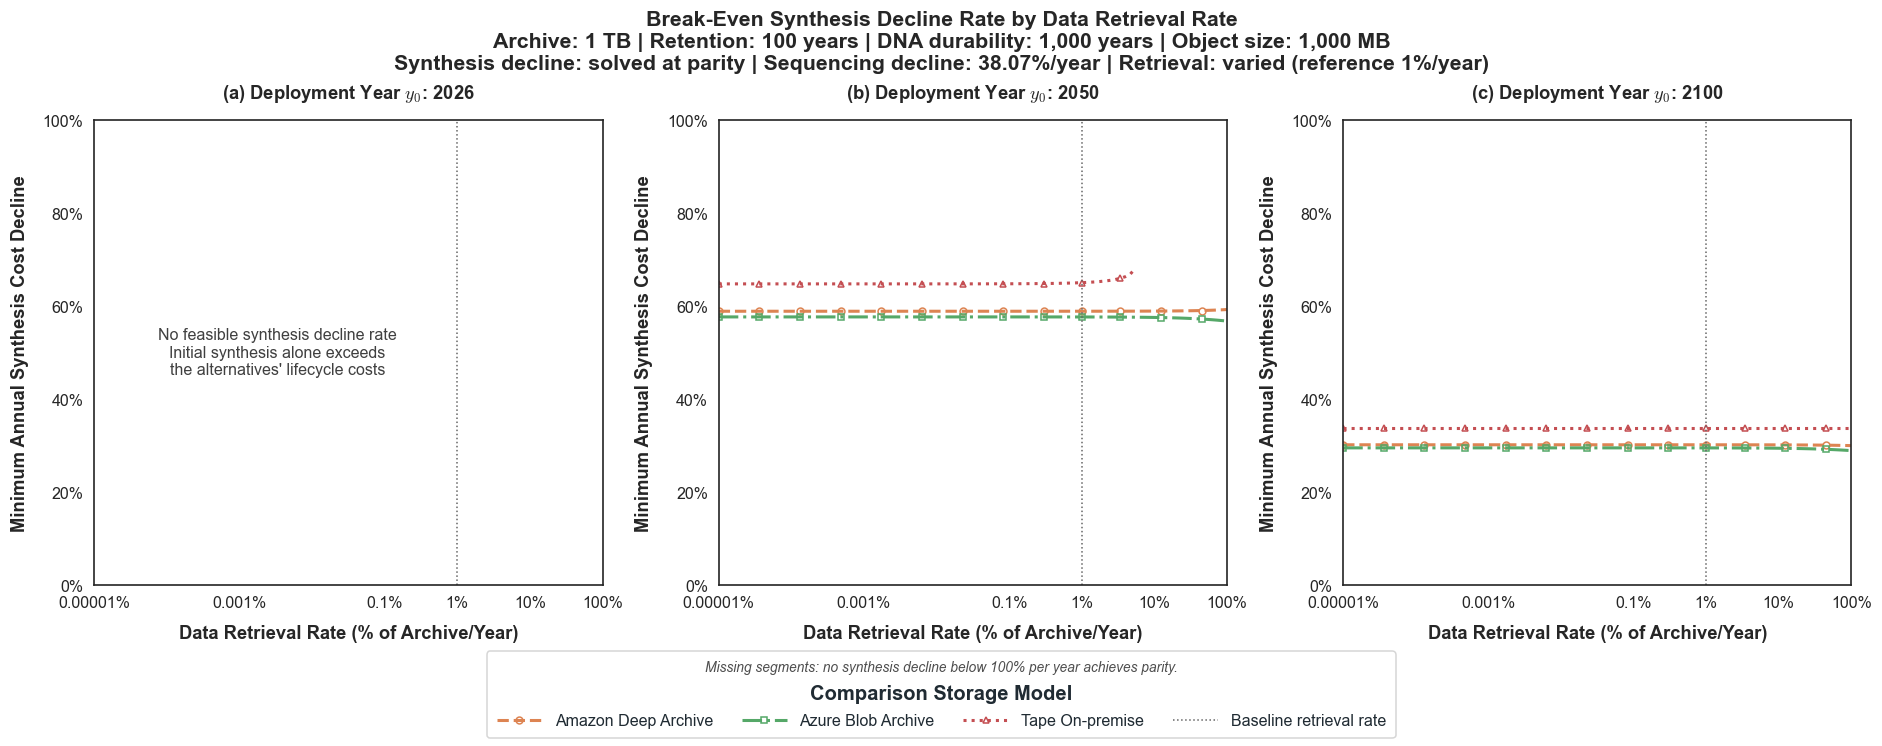

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
retrieval_grid = np.unique(np.r_[np.geomspace(1e-5, 100, 101), BASE.annual_retrieval_percent])
scenarios = {str(year): replace(BASE, start_year=year) for year in (BASE.start_year, 2050, 2100)}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.7), layout="constrained")
rows = []
MAX_DECLINE = 99.999999  # Annual declines must stay below 100%.
for (label, scenario), ax in zip(scenarios.items(), axes):
    # Public-model streams at 0% synthesis decline and 1% retrieval permit exact rescaling.
    reference = simulate_scenario(replace(scenario, synthesis_decline_percent=0,
                                         annual_retrieval_percent=1)).yearly
    dna = reference[reference.technology == "DNA"]
    age = dna.year.to_numpy() - scenario.dna_cost_base_year
    writes = dna.write_cost_usd.to_numpy()
    reads = dna.read_cost_usd.sum()
    for tech, marker in zip(PEERS, ("o", "s", "^")):
        peer = reference[reference.technology == tech]
        peer_fixed = peer.write_cost_usd.sum() + peer.maintenance_cost_usd.sum()
        peer_reads = peer.read_cost_usd.sum()
        rates = []
        for retrieval in retrieval_grid:
            peer_cost = peer_fixed + peer_reads * retrieval
            def difference(rate):
                return np.dot(writes, np.power(1 - rate / 100, age)) + reads * retrieval - peer_cost
            if difference(0) <= 0:
                rate, status = 0.0, "DNA_already_at_or_below_comparator"
            elif difference(MAX_DECLINE) > 0:
                rate, status = np.nan, "no_parity_below_100_percent_decline"
            else:
                rate = parity_root(difference, 0, MAX_DECLINE)
                status = "parity"
            rates.append(rate)
            rows.append({"start_year": scenario.start_year, "technology": tech,
                         "annual_retrieval_percent": retrieval,
                         "synthesis_decline_percent": rate, "status": status})
        ax.plot(retrieval_grid, rates, color=COLORS[tech], ls=STYLES[tech],
                marker=marker, markersize=4.5, markerfacecolor="none", markevery=8, label=tech)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
    if not any(np.isfinite(line.get_ydata()).any() for line in ax.lines):
        ax.text(0.36, 0.5, "No feasible synthesis decline rate\nInitial synthesis alone exceeds\nthe alternatives' lifecycle costs",
                transform=ax.transAxes, ha="center", va="center", fontsize=10.5, color="0.25")

for index, ((label, scenario), ax) in enumerate(zip(scenarios.items(), axes)):
    ax.set_xscale("log")
    ax.set_xlim(retrieval_grid.min(), retrieval_grid.max())
    ax.set_xticks([0.00001, 0.001, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.5f}".rstrip("0").rstrip(".") + "%"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axvline(BASE.annual_retrieval_percent, color="0.4", ls=":", lw=1,
               label="Baseline retrieval rate")
    ax.set_title(f"({chr(97 + index)}) Deployment Year $y_0$: {scenario.start_year}",
                 fontsize=12, fontweight="bold", color="0.15", pad=14)
    ax.set_xlabel("Data Retrieval Rate (% of Archive/Year)", fontsize=12, fontweight="bold", color="0.15")
    ax.set_ylabel('Minimum Annual Synthesis Cost Decline', fontsize=12, fontweight="bold", color="0.15")
    ax.grid(False, which="both")
    ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
handles, labels = axes[-1].get_legend_handles_labels()
fig.suptitle(
    "Break-Even Synthesis Decline Rate by Data Retrieval Rate\n"
    f"Archive: {BASE.archive_size_tb:,g} TB | Retention: {BASE.horizon_years:,g} years | "
    f"DNA durability: {BASE.dna_durability_years:,g} years | Object size: {BASE.average_asset_size_mb:,g} MB\n"
    f"Synthesis decline: solved at parity | Sequencing decline: {BASE.sequencing_decline_percent:.2f}%/year | "
    f"Retrieval: varied (reference {BASE.annual_retrieval_percent:g}%/year)"
    , fontsize=14, fontweight="bold", color="0.15")
shared_legend = fig.legend(handles, labels, loc="outside lower center", ncol=len(handles),
    title="Comparison Storage Model", frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
    framealpha=0.8, fontsize=10.5, handlelength=2.8, borderpad=0.6)
shared_legend.get_title().set_fontweight("bold")
from matplotlib.offsetbox import TextArea
legend_note = TextArea('Missing segments: no synthesis decline below 100% per year achieves parity.', textprops={"fontsize": 9, "fontstyle": "italic",
                                      "fontweight": "normal", "color": "0.3"})
legend_note.set_figure(fig)
# Pack both text styles inside the legend so constrained layout reserves their space.
shared_legend._legend_box.get_children().insert(0, legend_note)


s2b = pd.DataFrame(rows)
record("S2b_retrieval_vs_synthesis_decline", fig,
       f"Minimum annual synthesis decline required for DNA lifecycle cost to be no greater than each alternative. "
       f"Deployments: {BASE.start_year}, 2050, 2100. Baseline: {describe(BASE)}. "
       "Only retrieval and synthesis decline vary; sequencing decline and all price anchors remain unchanged. "
       "Positive thresholds solve full lifecycle parity; zero means DNA is already competitive without synthesis decline. "
       "Missing values mean no solution up to 99.999999% annual decline. In the anchor year, future declines "
       "cannot reduce the initial synthesis bill. The retrieval axis is logarithmic with plain percentage labels.",
       {"thresholds": s2b}, scenarios)


## S2c: retrieval vs. break-even average object size

Archive volume stays fixed. Smaller objects increase cloud request charges; tape has no per-object threshold. Sub-byte thresholds are theoretical.

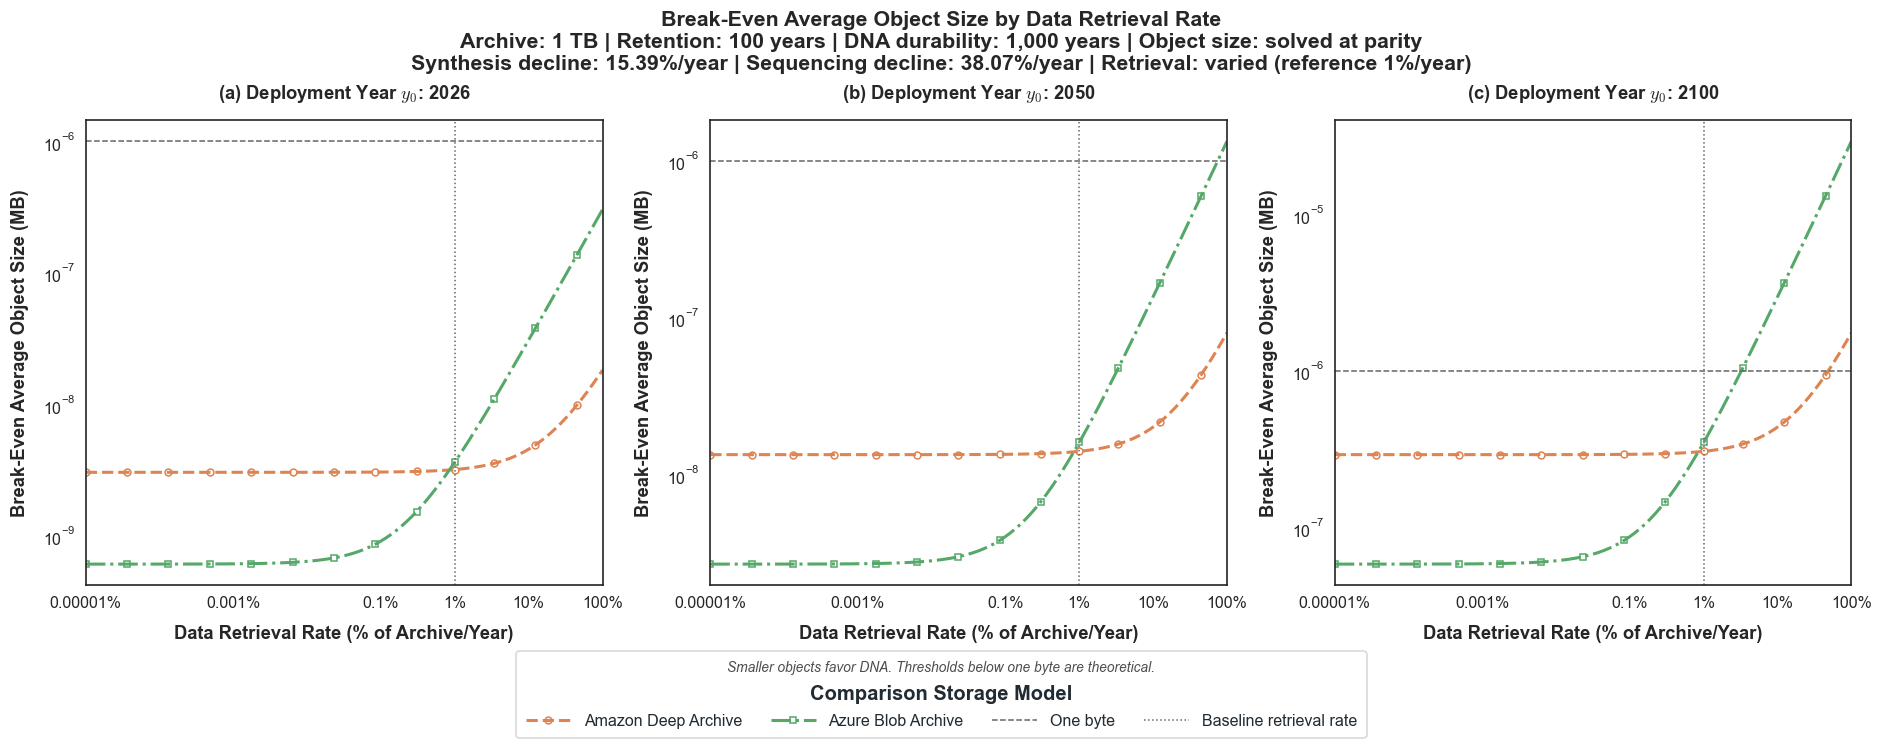

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
retrieval_grid = np.unique(np.r_[np.geomspace(1e-5, 100, 101), BASE.annual_retrieval_percent])
scenarios = {str(year): replace(BASE, start_year=year) for year in (BASE.start_year, 2050, 2100)}
fig, axes = plt.subplots(1, 3, figsize=(17, 6.7), layout="constrained")
rows = []

object_comparators = [tech for tech in PEERS if tech != "Tape On-premise"]
for (label, scenario), ax in zip(scenarios.items(), axes):
    reference_scenario = replace(scenario, annual_retrieval_percent=1)
    reference = simulate_scenario(reference_scenario).yearly
    # Removing request fees isolates the volume-dependent cost A in C = A + B/object_size.
    volume_only = simulate_scenario(replace(reference_scenario,
        amazon_put_usd_per_request=0, amazon_bulk_restore_usd_per_request=0,
        azure_write_usd_per_request=0, azure_read_usd_per_request=0)).yearly
    dna = reference[reference.technology == "DNA"]
    dna_cost = dna.write_cost_usd.sum() + dna.read_cost_usd.sum() * retrieval_grid
    for tech, marker in zip(object_comparators, ("o", "s")):
        peer = reference[reference.technology == tech]
        volume = volume_only[volume_only.technology == tech]
        fixed = volume.write_cost_usd.sum() + volume.maintenance_cost_usd.sum()
        volume_cost = fixed + volume.read_cost_usd.sum() * retrieval_grid
        request_write = peer.write_cost_usd.sum() - volume.write_cost_usd.sum()
        request_read = peer.read_cost_usd.sum() - volume.read_cost_usd.sum()
        coefficient = (request_write + request_read * retrieval_grid) * scenario.average_asset_size_mb
        thresholds = []
        for retrieval, dna_total, volume_total, b in zip(retrieval_grid, dna_cost, volume_cost, coefficient):
            gap = dna_total - volume_total
            threshold = np.nan
            if b <= 0:
                status = "no_object_size_dependence"
            elif gap <= 0:
                status = "DNA_competitive_at_every_object_size"
            else:
                candidate = b / gap
                if candidate <= scenario.archive_size_mb:
                    threshold, status = candidate, "parity"
                else:
                    status = "DNA_competitive_at_every_valid_object_size"
            thresholds.append(threshold)
            rows.append({"start_year": scenario.start_year, "technology": tech,
                         "annual_retrieval_percent": retrieval, "object_size_mb": threshold,
                         "object_size_bytes": threshold * 1e6, "status": status})
        ax.plot(retrieval_grid, thresholds, color=COLORS[tech], ls=STYLES[tech],
                marker=marker, markersize=4.5, markerfacecolor="none", markevery=8, label=tech)
    ax.set_yscale("log")
    ax.axhline(1e-6, color="0.4", ls="--", lw=1, label="One byte")

for index, ((label, scenario), ax) in enumerate(zip(scenarios.items(), axes)):
    ax.set_xscale("log")
    ax.set_xlim(retrieval_grid.min(), retrieval_grid.max())
    ax.set_xticks([0.00001, 0.001, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.5f}".rstrip("0").rstrip(".") + "%"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axvline(BASE.annual_retrieval_percent, color="0.4", ls=":", lw=1,
               label="Baseline retrieval rate")
    ax.set_title(f"({chr(97 + index)}) Deployment Year $y_0$: {scenario.start_year}",
                 fontsize=12, fontweight="bold", color="0.15", pad=14)
    ax.set_xlabel("Data Retrieval Rate (% of Archive/Year)", fontsize=12, fontweight="bold", color="0.15")
    ax.set_ylabel('Break-Even Average Object Size (MB)', fontsize=12, fontweight="bold", color="0.15")
    ax.grid(False, which="both")
    ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
handles, labels = axes[-1].get_legend_handles_labels()
fig.suptitle(
    "Break-Even Average Object Size by Data Retrieval Rate\n"
    f"Archive: {BASE.archive_size_tb:,g} TB | Retention: {BASE.horizon_years:,g} years | "
    f"DNA durability: {BASE.dna_durability_years:,g} years | Object size: solved at parity\n"
    f"Synthesis decline: {BASE.synthesis_decline_percent:.2f}%/year | Sequencing decline: {BASE.sequencing_decline_percent:.2f}%/year | "
    f"Retrieval: varied (reference {BASE.annual_retrieval_percent:g}%/year)"
    , fontsize=14, fontweight="bold", color="0.15")
shared_legend = fig.legend(handles, labels, loc="outside lower center", ncol=len(handles),
    title="Comparison Storage Model", frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
    framealpha=0.8, fontsize=10.5, handlelength=2.8, borderpad=0.6)
shared_legend.get_title().set_fontweight("bold")
from matplotlib.offsetbox import TextArea
legend_note = TextArea('Smaller objects favor DNA. Thresholds below one byte are theoretical.', textprops={"fontsize": 9, "fontstyle": "italic",
                                      "fontweight": "normal", "color": "0.3"})
legend_note.set_figure(fig)
# Pack both text styles inside the legend so constrained layout reserves their space.
shared_legend._legend_box.get_children().insert(0, legend_note)


s2c = pd.DataFrame(rows)
record("S2c_retrieval_vs_object_size", fig,
       f"Average object size giving DNA/comparator lifecycle parity for deployments in {BASE.start_year}, "
       f"2050, and 2100. Baseline: {describe(BASE)}. Archive volume is fixed; the number of objects varies "
       "inversely with average object size. Cloud request charges rise for smaller objects, while DNA cost "
       "is unchanged. Sizes below a plotted threshold favor DNA; larger sizes favor the comparator. "
       "Thresholds below one byte are mathematical extrapolations, not physically attainable objects. "
       "Tape has no per-object charges and therefore no unique object-size threshold. Other absent values "
       "are classified in the CSV. Both axes are logarithmic; decimal MB are used. Storage-service minimum "
       "billable object sizes and extra DNA addressing overhead are not added to the existing model.",
       {"thresholds": s2c}, scenarios)


## S2d: break-even object size with synthesis calibrated to Amazon parity in 2050

One synthesis price calibration at baseline retrieval and object size is carried forward to 2050, 2075, and 2100 with the original decline rate.

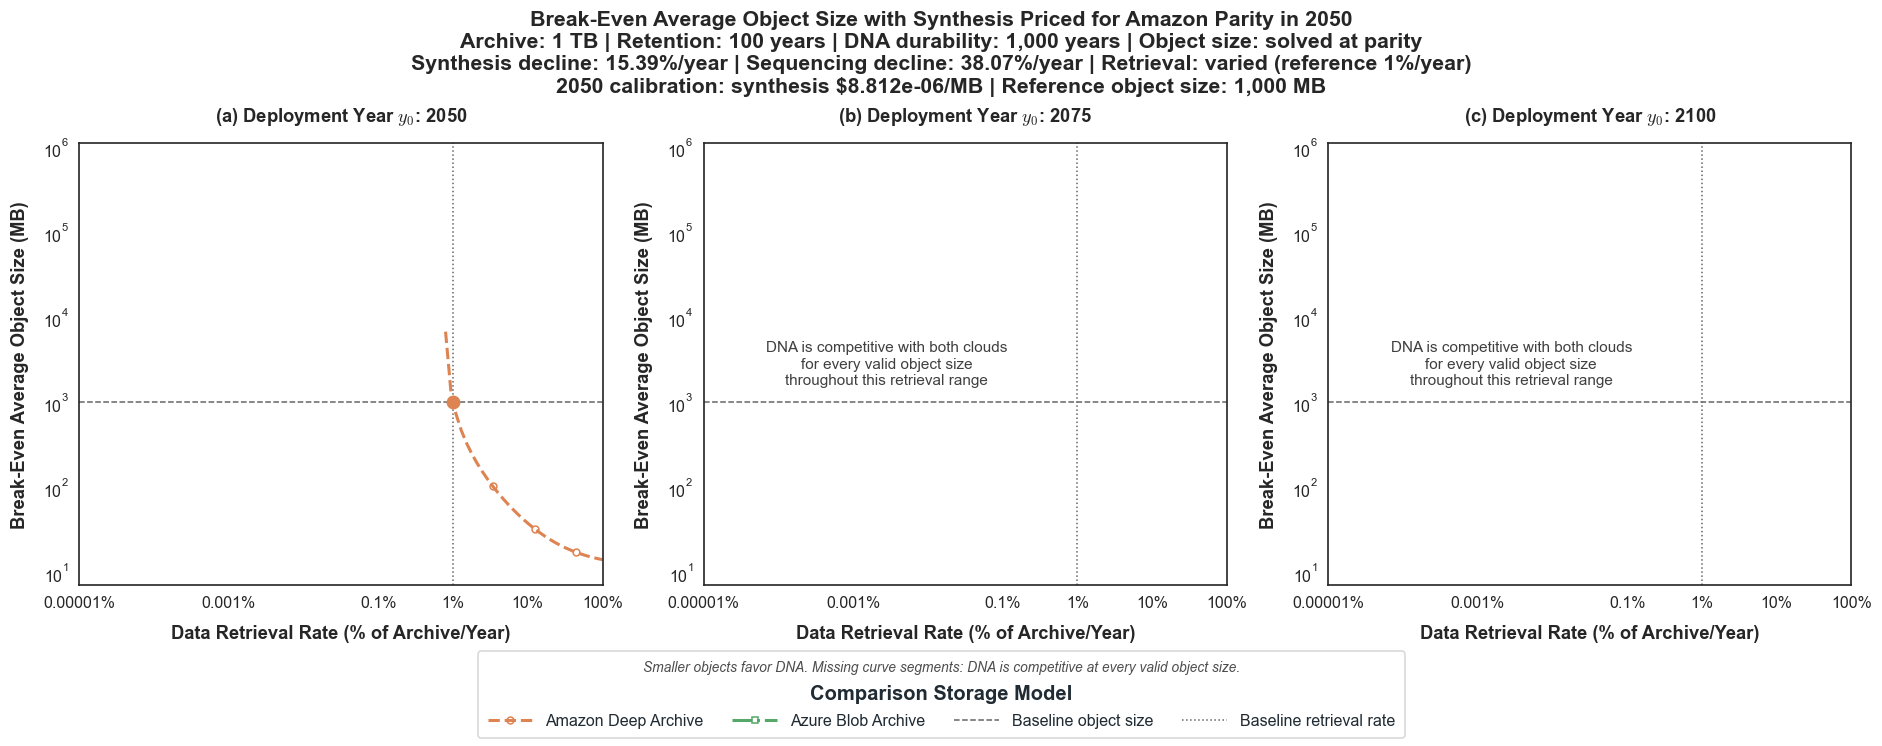

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
retrieval_grid = np.unique(np.r_[np.geomspace(1e-5, 100, 101), BASE.annual_retrieval_percent])
calibration_scenario = replace(BASE, start_year=2050)
calibration_thresholds = threshold_at_start(calibration_scenario).set_index("technology")
parity_price_2050 = float(calibration_thresholds.loc["Amazon Deep Archive", "threshold_start_usd_per_mb"])
if not np.isfinite(parity_price_2050) or parity_price_2050 < 0:
    raise ValueError("No nonnegative synthesis price gives Amazon parity in 2050 with this baseline.")
calibrated_base = future_at_price(calibration_scenario, parity_price_2050)
scenarios = {str(year): replace(calibrated_base, start_year=year) for year in (2050, 2075, 2100)}
calibration = pd.DataFrame([{
    "deployment_year": 2050, "annual_retrieval_percent": BASE.annual_retrieval_percent,
    "average_object_size_mb": BASE.average_asset_size_mb,
    "synthesis_price_2050_usd_per_mb": parity_price_2050,
    "synthesis_anchor_year": BASE.dna_cost_base_year,
    "synthesis_anchor_usd_per_mb": calibrated_base.dna_synthesis_cost_per_mb,
}])
fig, axes = plt.subplots(1, 3, figsize=(17, 6.7), layout="constrained")
rows = []

object_comparators = [tech for tech in PEERS if tech != "Tape On-premise"]
for (label, scenario), ax in zip(scenarios.items(), axes):
    reference_scenario = replace(scenario, annual_retrieval_percent=1)
    reference = simulate_scenario(reference_scenario).yearly
    # Removing request fees isolates the volume-dependent cost A in C = A + B/object_size.
    volume_only = simulate_scenario(replace(reference_scenario,
        amazon_put_usd_per_request=0, amazon_bulk_restore_usd_per_request=0,
        azure_write_usd_per_request=0, azure_read_usd_per_request=0)).yearly
    dna = reference[reference.technology == "DNA"]
    dna_cost = dna.write_cost_usd.sum() + dna.read_cost_usd.sum() * retrieval_grid
    for tech, marker in zip(object_comparators, ("o", "s")):
        peer = reference[reference.technology == tech]
        volume = volume_only[volume_only.technology == tech]
        fixed = volume.write_cost_usd.sum() + volume.maintenance_cost_usd.sum()
        volume_cost = fixed + volume.read_cost_usd.sum() * retrieval_grid
        request_write = peer.write_cost_usd.sum() - volume.write_cost_usd.sum()
        request_read = peer.read_cost_usd.sum() - volume.read_cost_usd.sum()
        coefficient = (request_write + request_read * retrieval_grid) * scenario.average_asset_size_mb
        thresholds = []
        for retrieval, dna_total, volume_total, b in zip(retrieval_grid, dna_cost, volume_cost, coefficient):
            gap = dna_total - volume_total
            threshold = np.nan
            if b <= 0:
                status = "no_object_size_dependence"
            elif gap <= 0:
                status = "DNA_competitive_at_every_object_size"
            else:
                candidate = b / gap
                if candidate <= scenario.archive_size_mb:
                    threshold, status = candidate, "parity"
                else:
                    status = "DNA_competitive_at_every_valid_object_size"
            thresholds.append(threshold)
            rows.append({"start_year": scenario.start_year, "technology": tech,
                         "annual_retrieval_percent": retrieval, "object_size_mb": threshold,
                         "object_size_bytes": threshold * 1e6, "status": status})
        ax.plot(retrieval_grid, thresholds, color=COLORS[tech], ls=STYLES[tech],
                marker=marker, markersize=4.5, markerfacecolor="none", markevery=8, label=tech)
    ax.set_yscale("log")
    ax.axhline(BASE.average_asset_size_mb, color="0.4", ls="--", lw=1, label="Baseline object size")
    if not any(np.isfinite(line.get_ydata()).any() for line in ax.lines[:len(object_comparators)]):
        ax.text(0.35, 0.5, "DNA is competitive with both clouds\nfor every valid object size\nthroughout this retrieval range",
                transform=ax.transAxes, ha="center", va="center", fontsize=10, color="0.25")
    if scenario.start_year == 2050:
        ax.scatter(BASE.annual_retrieval_percent, BASE.average_asset_size_mb,
                   color=COLORS["Amazon Deep Archive"], s=65, zorder=5)

for index, ((label, scenario), ax) in enumerate(zip(scenarios.items(), axes)):
    ax.set_xscale("log")
    ax.set_xlim(retrieval_grid.min(), retrieval_grid.max())
    ax.set_xticks([0.00001, 0.001, 0.1, 1, 10, 100])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.5f}".rstrip("0").rstrip(".") + "%"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axvline(BASE.annual_retrieval_percent, color="0.4", ls=":", lw=1,
               label="Baseline retrieval rate")
    ax.set_title(f"({chr(97 + index)}) Deployment Year $y_0$: {scenario.start_year}",
                 fontsize=12, fontweight="bold", color="0.15", pad=14)
    ax.set_xlabel("Data Retrieval Rate (% of Archive/Year)", fontsize=12, fontweight="bold", color="0.15")
    ax.set_ylabel('Break-Even Average Object Size (MB)', fontsize=12, fontweight="bold", color="0.15")
    ax.grid(False, which="both")
    ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
handles, labels = axes[-1].get_legend_handles_labels()
fig.suptitle(
    "Break-Even Average Object Size with Synthesis Priced for Amazon Parity in 2050\n"
    f"Archive: {BASE.archive_size_tb:,g} TB | Retention: {BASE.horizon_years:,g} years | "
    f"DNA durability: {BASE.dna_durability_years:,g} years | Object size: solved at parity\n"
    f"Synthesis decline: {BASE.synthesis_decline_percent:.2f}%/year | Sequencing decline: {BASE.sequencing_decline_percent:.2f}%/year | "
    f"Retrieval: varied (reference {BASE.annual_retrieval_percent:g}%/year)"
    f"\n2050 calibration: synthesis ${parity_price_2050:.4g}/MB | "
    f"Reference object size: {BASE.average_asset_size_mb:,g} MB"
    , fontsize=14, fontweight="bold", color="0.15")
shared_legend = fig.legend(handles, labels, loc="outside lower center", ncol=len(handles),
    title="Comparison Storage Model", frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
    framealpha=0.8, fontsize=10.5, handlelength=2.8, borderpad=0.6)
shared_legend.get_title().set_fontweight("bold")
from matplotlib.offsetbox import TextArea
legend_note = TextArea('Smaller objects favor DNA. Missing curve segments: DNA is competitive at every valid object size.', textprops={"fontsize": 9, "fontstyle": "italic",
                                      "fontweight": "normal", "color": "0.3"})
legend_note.set_figure(fig)
# Pack both text styles inside the legend so constrained layout reserves their space.
shared_legend._legend_box.get_children().insert(0, legend_note)



s2d = pd.DataFrame(rows)
valid_sizes = s2d.object_size_mb.dropna()
for ax in axes:
    ax.set_ylim(min(BASE.average_asset_size_mb, valid_sizes.min()) * 0.5
                if len(valid_sizes) else BASE.average_asset_size_mb / 10,
                BASE.archive_size_mb * 1.1)
record("S2d_retrieval_vs_object_size_calibrated", fig,
       f"Break-even average object size at fixed archive volume for deployments in 2050, 2075, and 2100. "
       f"Synthesis price is calibrated once to full DNA/Amazon lifecycle parity for a 2050 deployment "
       f"at {BASE.annual_retrieval_percent:g}% annual retrieval and {BASE.average_asset_size_mb:,g} MB/object: "
       f"USD {parity_price_2050:.10g}/MB in 2050, equivalent to USD "
       f"{calibrated_base.dna_synthesis_cost_per_mb:.10g}/MB at the {BASE.dna_cost_base_year} anchor. "
       f"The original synthesis decline ({BASE.synthesis_decline_percent:g}%/year) and sequencing "
       "trajectory are retained; later deployments are not recalibrated. The orange point marks the "
       "2050 calibration. Below each threshold DNA is cheaper; above it the cloud comparator is cheaper. "
       "Absent thresholds indicate DNA is competitive for all valid object sizes (up to the archive size); "
       "statuses are exported in the CSV. Tape is excluded because it has no per-object costs. "
       "Both axes are logarithmic; no additional object-overhead or minimum-billing assumptions are added.",
       {"thresholds": s2d, "calibration": calibration}, scenarios)


## S3 — start-year parity under alternative synthesis declines

Each point represents a **different archive started in that year**, retained for the same duration; it is not the cumulative cost of a single archive aging through time. Only synthesis decline changes. The horizontal parity line is \(C_{\mathrm{DNA}}/C_{\mathrm{comparison}}=1\). Markers indicate the first sampled integer start year at or below parity. No crossing by the last sampled year remains missing in the CSV.

The faster rates below are explicit what-if annual percentages, not extrapolation estimates.

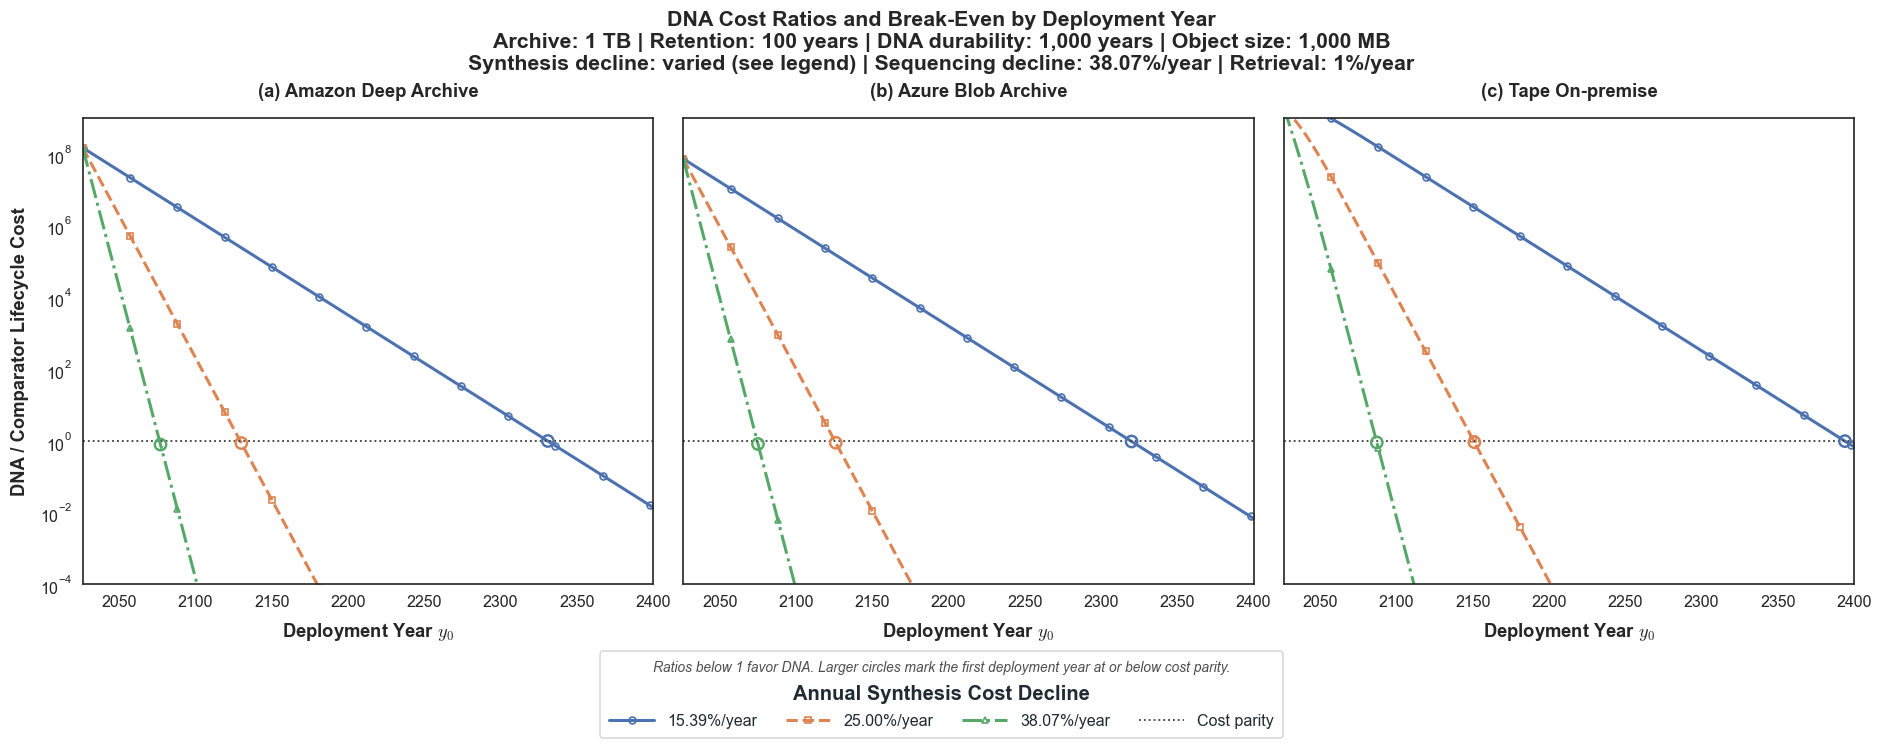

            technology  ...  search_end
0  Amazon Deep Archive  ...        2400
1   Azure Blob Archive  ...        2400
2      Tape On-premise  ...        2400
3  Amazon Deep Archive  ...        2400
4   Azure Blob Archive  ...        2400
5      Tape On-premise  ...        2400
6  Amazon Deep Archive  ...        2400
7   Azure Blob Archive  ...        2400
8      Tape On-premise  ...        2400

[9 rows x 4 columns]

In [27]:
SAVE = True  # False previews only; True exports this figure and its data.
synthesis_rates = [float(BASE.synthesis_decline_percent), 25.0, float(BASE.sequencing_decline_percent)]
s3_scenarios = {f"decline_{rate:.6g}": replace(BASE, synthesis_decline_percent=rate)
                for rate in synthesis_rates}
fig, axes = plt.subplots(1, len(PEERS), figsize=(17, 6.7), sharey=True, layout="constrained")
rows, parity_rows = [], []
for rate_index, (label, scenario) in enumerate(s3_scenarios.items()):
    projection = simulate_start_years(scenario, FINAL_START)
    wide = projection.pivot(index="start_year", columns="technology", values="total_cost_usd")
    for ax, tech in zip(axes, PEERS):
        ratio = wide["DNA"] / wide[tech]
        eligible = ratio.index[ratio <= 1]
        crossing = int(eligible[0]) if len(eligible) else None
        ax.plot(ratio.index, ratio, color=PALETTE[rate_index],
                ls=("-", "--", "-.")[rate_index],
                label=f"{scenario.synthesis_decline_percent:.2f}%/year")
        if crossing is not None:
            ax.scatter(crossing, ratio.loc[crossing], color=PALETTE[rate_index], s=35, zorder=5)
        rows.append(pd.DataFrame({"start_year": ratio.index, "technology": tech,
                                  "synthesis_decline_percent": scenario.synthesis_decline_percent,
                                  "dna_cost_usd": wide["DNA"].to_numpy(),
                                  "comparison_cost_usd": wide[tech].to_numpy(),
                                  "cost_ratio": ratio.to_numpy()}))
        parity_rows.append({"technology": tech, "synthesis_decline_percent": scenario.synthesis_decline_percent,
                            "first_integer_start_year_at_parity": crossing, "search_end": FINAL_START})
for index, (ax, tech) in enumerate(zip(axes, PEERS)):
    ax.axhline(1, color="0.25", ls=":", lw=1.2, label="Cost parity")
    ax.set_yscale("log")
    ax.set_xlim(BASE.start_year, FINAL_START)
    # Restrict the display to economically interpretable ratios; full tails stay in CSV.
    ax.set_ylim(1e-4, 1e9)
    tidy(ax, r"Deployment Year $y_0$", "DNA / Comparator Lifecycle Cost" if index == 0 else None,
         f"({chr(97 + index)}) {tech}")

s3_parity = pd.DataFrame(parity_rows)

for ax in axes:
    ax.grid(False, which="both")
    ax.tick_params(axis="both", which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
    ax.set_xlabel(ax.get_xlabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    ax.set_ylabel(ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    panel_title = ax.get_title(loc="left")
    ax.set_title("", loc="left")
    ax.set_title(panel_title, fontsize=12, fontweight="bold", color="0.15", pad=14)
    for line, marker in zip(ax.lines[:3], ("o", "s", "^")):
        line.set_linewidth(2)
        line.set_marker(marker)
        line.set_markersize(4.5)
        line.set_markerfacecolor("none")
        line.set_markeredgewidth(1.1)
        line.set_markevery(max(1, len(line.get_xdata()) // 12))
    for collection in ax.collections:
        collection.set_sizes([55])
        collection.set_facecolor("none")
        collection.set_linewidth(1.6)
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(
    "DNA Cost Ratios and Break-Even by Deployment Year\n"
    f"Archive: {BASE.archive_size_tb:,g} TB | Retention: {BASE.horizon_years:,g} years | "
    f"DNA durability: {BASE.dna_durability_years:,g} years | Object size: {BASE.average_asset_size_mb:,g} MB\n"
    f"Synthesis decline: varied (see legend) | Sequencing decline: {BASE.sequencing_decline_percent:.2f}%/year | "
    f"Retrieval: {BASE.annual_retrieval_percent:g}%/year",
    fontsize=14, fontweight="bold", color="0.15")
shared_legend = fig.legend(handles, labels, title='Annual Synthesis Cost Decline',
           loc="outside lower center", ncol=len(handles), frameon=True,
           fancybox=True, facecolor="white", edgecolor="0.8", framealpha=0.8,
           fontsize=10.5, handlelength=2.8, handletextpad=0.8, borderpad=0.6)
shared_legend.get_title().set_fontweight("bold")
from matplotlib.offsetbox import TextArea
legend_note = TextArea('Ratios below 1 favor DNA. Larger circles mark the first deployment year at or below cost parity.', textprops={"fontsize": 9, "fontstyle": "italic",
                                      "fontweight": "normal", "color": "0.3"})
legend_note.set_figure(fig)
# Pack both text styles inside the legend so constrained layout reserves their space.
shared_legend._legend_box.get_children().insert(0, legend_note)

record("S3_start_year_decline_scenarios", fig,
       f"DNA-to-comparator lifecycle cost ratios for different archive start years under three "
       f"synthesis-decline assumptions, stated as actual annual percentages. Workload and retention: "
       f"{describe(BASE)}. Sequencing decline remains {BASE.sequencing_decline_percent:.2f}%/year. "
       "Each point is a new archive deployment; the horizontal line is parity. Dots mark the first "
       f"integer start year reaching parity through {FINAL_START}; these are conditional scenario "
       "results, not calendar forecasts. Ratios outside the plotted range remain in the CSV.",
       {"ratios": pd.concat(rows, ignore_index=True), "parity_years": s3_parity}, s3_scenarios)
display(s3_parity)

## S4 — joint sensitivity to DNA and cloud cost declines

The colour is \(\log_{10}(C_{\mathrm{DNA}}/C_{\mathrm{Amazon}})\), evaluated for a future deployment. White is parity, red means DNA costs more, and blue means DNA costs less. The black contour marks parity when it is present.

Both decline assumptions affect all relevant years from their original fixed price anchors. These are equally spaced parameter sweeps, **not** probabilities.

S4 lifecycle parity at Amazon decline 10%/year: synthesis decline 58.925818%/year


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved S4_joint_decline_sensitivity: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


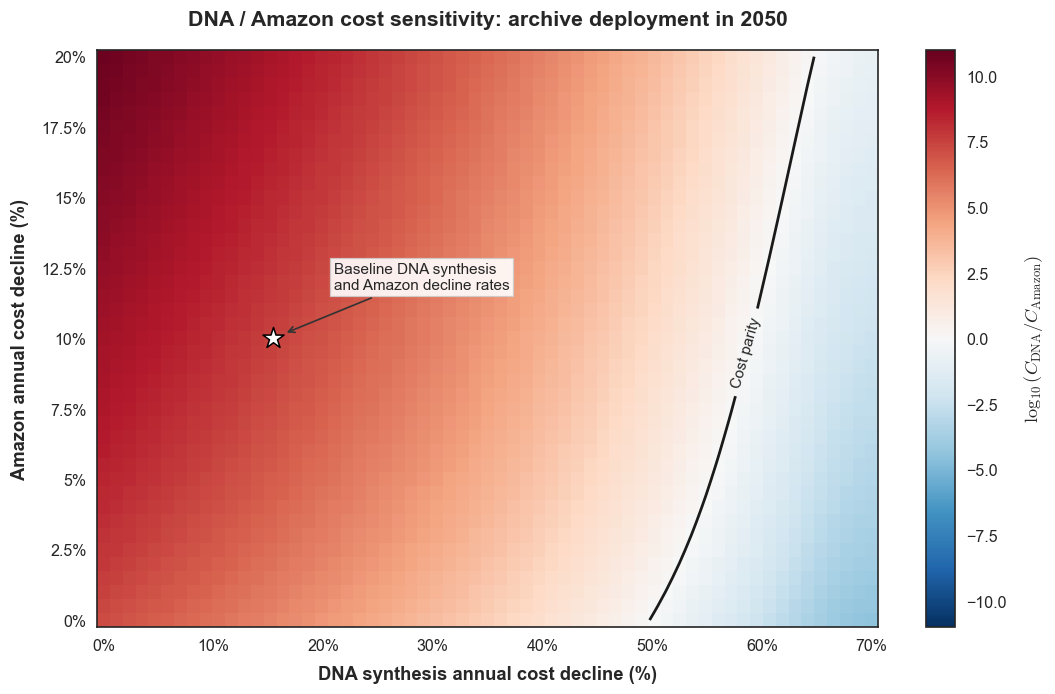

In [4]:
SAVE = True  # False previews only; True exports this figure and its data.
s4_scenario = replace(BASE, start_year=FUTURE_START, technologies=("DNA", COMPARATOR))
dna_rates = np.linspace(0, 70, 61)
cloud_rates = np.linspace(0, 20, 41)
rows = []
for cloud_rate in cloud_rates:
    for dna_rate in dna_rates:
        probe = replace(s4_scenario, synthesis_decline_percent=float(dna_rate),
                        amazon_decline_percent=float(cloud_rate))
        costs = totals(probe)
        rows.append({"synthesis_decline_percent": dna_rate, "amazon_decline_percent": cloud_rate,
                     "dna_cost_usd": costs["DNA"], "comparison_cost_usd": costs[COMPARATOR],
                     "log10_cost_ratio": np.log10(costs["DNA"] / costs[COMPARATOR])})
s4 = pd.DataFrame(rows)
z = s4.pivot(index="amazon_decline_percent", columns="synthesis_decline_percent",
             values="log10_cost_ratio").to_numpy()
limit = float(np.ceil(np.max(np.abs(z))))
fig, ax = plt.subplots(figsize=(9.5, 6.2), layout="constrained")
mesh = ax.pcolormesh(dna_rates, cloud_rates, z, shading="auto", cmap="RdBu_r",
                     norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), rasterized=True)
if z.min() <= 0 <= z.max():
    contour = ax.contour(dna_rates, cloud_rates, z, levels=[0], colors="0.1", linewidths=1.8)
    ax.clabel(contour, fmt={0: "Cost parity"}, fontsize=10)
ax.scatter(BASE.synthesis_decline_percent, BASE.amazon_decline_percent,
           marker="*", s=210, color="white", edgecolor="black", zorder=5)
ax.annotate(
    "Baseline DNA synthesis\nand Amazon decline rates",
    (BASE.synthesis_decline_percent, BASE.amazon_decline_percent),
    xytext=(40, 30), textcoords="offset points", ha="left", va="bottom",
    fontsize=10, zorder=6,
    arrowprops={"arrowstyle": "->", "color": "0.2", "lw": 1.1, "shrinkB": 10},
    bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "none", "pad": 2.5},
)
tidy(ax, "DNA synthesis annual cost decline (%)", "Amazon annual cost decline (%)",
     f"DNA / Amazon cost sensitivity: archive deployment in {FUTURE_START}")
ax.grid(False)
fig.colorbar(mesh, ax=ax, label=r"$\log_{10}(C_{\mathrm{DNA}}/C_{\mathrm{Amazon}})$")

ax.grid(False, which="both")
ax.set_xlabel(ax.get_xlabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel(ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=8)
plot_title = ax.get_title(loc="left")
ax.set_title("", loc="left")
ax.set_title(plot_title, fontsize=14, fontweight="bold", color="0.15", pad=16)
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
colorbar = mesh.colorbar
colorbar.ax.tick_params(labelsize=10.5, colors="0.15", length=0, pad=7)
colorbar.ax.set_ylabel(colorbar.ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=10)
colorbar.outline.set_edgecolor("0.15")
colorbar.outline.set_linewidth(1.1)
for text in ax.texts:
    text.set_color("0.15")
    box = text.get_bbox_patch()
    if box is not None:
        box.set_edgecolor("0.8")
        box.set_linewidth(0.8)
        box.set_alpha(0.9)
s4_threshold = s4_synthesis_parity(10.0)
print(f"S4 lifecycle parity at Amazon decline 10%/year: synthesis decline {s4_threshold:.6f}%/year")
record("S4_joint_decline_sensitivity", fig,
       f"Joint sensitivity of DNA versus Amazon Deep Archive lifecycle cost, for {describe(s4_scenario)}. "
       "The synthesis decline varies from 0 to 70%/year; all Amazon tariff components share a "
       "decline varied from 0 to 20%/year. Colour gives the base-10 log cost ratio: negative values "
       "favour DNA and positive values favour Amazon. A black contour marks parity; the star marks "
       "the baseline rates. Price anchors are held fixed, and sequencing follows its baseline trajectory. "
       "This grid is a scenario sweep, not a probability distribution.",
       {"grid": s4, "parity_at_amazon_10": pd.DataFrame([{"amazon_decline_percent": 10.0, "synthesis_decline_percent": s4_threshold}])}, {"future": s4_scenario})

## S4 (2026): synthesis and Amazon declines

Same sweep and price anchors as the 2050 figure, but the archive starts in 2026. With the baseline 100-year retention, the initial synthesis bill is paid immediately at the 2026 price. Later declines cannot reduce that bill, and there is no lifecycle break-even rate at Amazon decline 10%/year. A missing parity contour is intentional, not a plotting error.

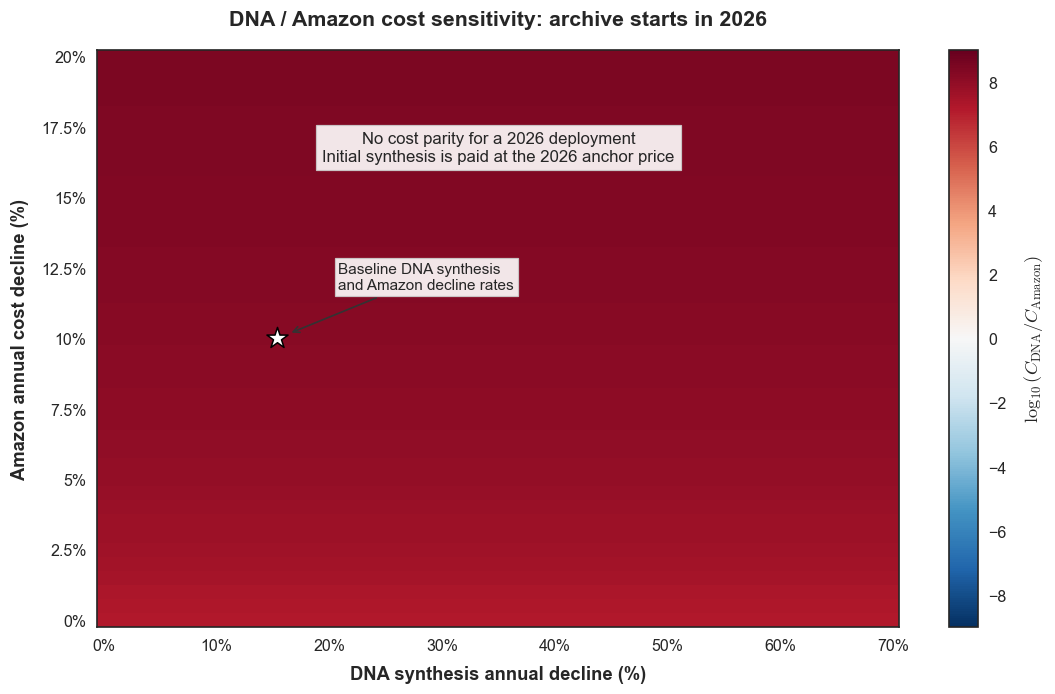

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
s4_scenario = replace(BASE, start_year=2026, technologies=("DNA", COMPARATOR))
dna_rates = np.linspace(0, 70, 61)
cloud_rates = np.linspace(0, 20, 41)
rows = []
for cloud_rate in cloud_rates:
    for dna_rate in dna_rates:
        probe = replace(s4_scenario, synthesis_decline_percent=float(dna_rate),
                        amazon_decline_percent=float(cloud_rate))
        costs = totals(probe)
        rows.append({"synthesis_decline_percent": dna_rate, "amazon_decline_percent": cloud_rate,
                     "dna_cost_usd": costs["DNA"], "comparison_cost_usd": costs[COMPARATOR],
                     "log10_cost_ratio": np.log10(costs["DNA"] / costs[COMPARATOR])})
s4 = pd.DataFrame(rows)
z = s4.pivot(index="amazon_decline_percent", columns="synthesis_decline_percent",
             values="log10_cost_ratio").to_numpy()
limit = float(np.ceil(np.max(np.abs(z))))
fig, ax = plt.subplots(figsize=(9.5, 6.2), layout="constrained")
mesh = ax.pcolormesh(dna_rates, cloud_rates, z, shading="auto", cmap="RdBu_r",
                     norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit), rasterized=True)
if z.min() <= 0 <= z.max():
    contour = ax.contour(dna_rates, cloud_rates, z, levels=[0], colors="0.1", linewidths=1.8)
    ax.clabel(contour, fmt={0: "Cost parity"}, fontsize=10)
if z.min() > 0:
    ax.text(0.5, 0.83, "No cost parity for a 2026 deployment\nInitial synthesis is paid at the 2026 anchor price",
            transform=ax.transAxes, ha="center", va="center", fontsize=11,
            bbox={"facecolor": "white", "alpha": 0.92, "edgecolor": "none"})
ax.scatter(BASE.synthesis_decline_percent, BASE.amazon_decline_percent,
           marker="*", s=210, color="white", edgecolor="black", zorder=5)
ax.annotate(
    "Baseline DNA synthesis\nand Amazon decline rates",
    (BASE.synthesis_decline_percent, BASE.amazon_decline_percent),
    xytext=(40, 30), textcoords="offset points", ha="left", va="bottom",
    fontsize=10, zorder=6,
    arrowprops={"arrowstyle": "->", "color": "0.2", "lw": 1.1, "shrinkB": 10},
    bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "none", "pad": 2.5},
)
tidy(ax, "DNA synthesis annual decline (%)", "Amazon annual cost decline (%)",
     f"DNA / Amazon cost sensitivity: archive starts in {2026}")
ax.grid(False)
fig.colorbar(mesh, ax=ax, label=r"$\log_{10}(C_{\mathrm{DNA}}/C_{\mathrm{Amazon}})$")

ax.grid(False, which="both")
ax.set_xlabel(ax.get_xlabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel(ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=8)
plot_title = ax.get_title(loc="left")
ax.set_title("", loc="left")
ax.set_title(plot_title, fontsize=14, fontweight="bold", color="0.15", pad=16)
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
colorbar = mesh.colorbar
colorbar.ax.tick_params(labelsize=10.5, colors="0.15", length=0, pad=7)
colorbar.ax.set_ylabel(colorbar.ax.get_ylabel(), fontsize=12, fontweight="bold", color="0.15", labelpad=10)
colorbar.outline.set_edgecolor("0.15")
colorbar.outline.set_linewidth(1.1)
for text in ax.texts:
    text.set_color("0.15")
    box = text.get_bbox_patch()
    if box is not None:
        box.set_edgecolor("0.8")
        box.set_linewidth(0.8)
        box.set_alpha(0.9)
s4_threshold = s4_synthesis_parity(10.0, start_year=2026)
print(f"Synthesis parity: {s4_threshold:.6f}%/year" if np.isfinite(s4_threshold) else "No synthesis-decline parity for a 2026 deployment at Amazon decline 10%/year.")
record("S4_joint_decline_sensitivity_2026", fig,
       f"Joint sensitivity of DNA versus Amazon Deep Archive lifecycle cost, for {describe(s4_scenario)}. "
       "The synthesis decline varies from 0 to 70%/year; all Amazon tariff components share a "
       "decline varied from 0 to 20%/year. Colour gives the base-10 log cost ratio: negative values "
       "favour DNA and positive values favour Amazon. A black contour marks parity; the star marks "
       "the baseline rates. Price anchors are held fixed, and sequencing follows its baseline trajectory. "
       "This grid is a scenario sweep, not a probability distribution.",
       {"grid": s4, "parity_at_amazon_10": pd.DataFrame([{"amazon_decline_percent": 10.0, "synthesis_decline_percent": s4_threshold}])}, {"future": s4_scenario})

## S4b: joint synthesis and sequencing prices at Amazon parity

Directly labeled cost-parity curves. No heatmap is drawn; numerical assumptions and search bounds are unchanged.

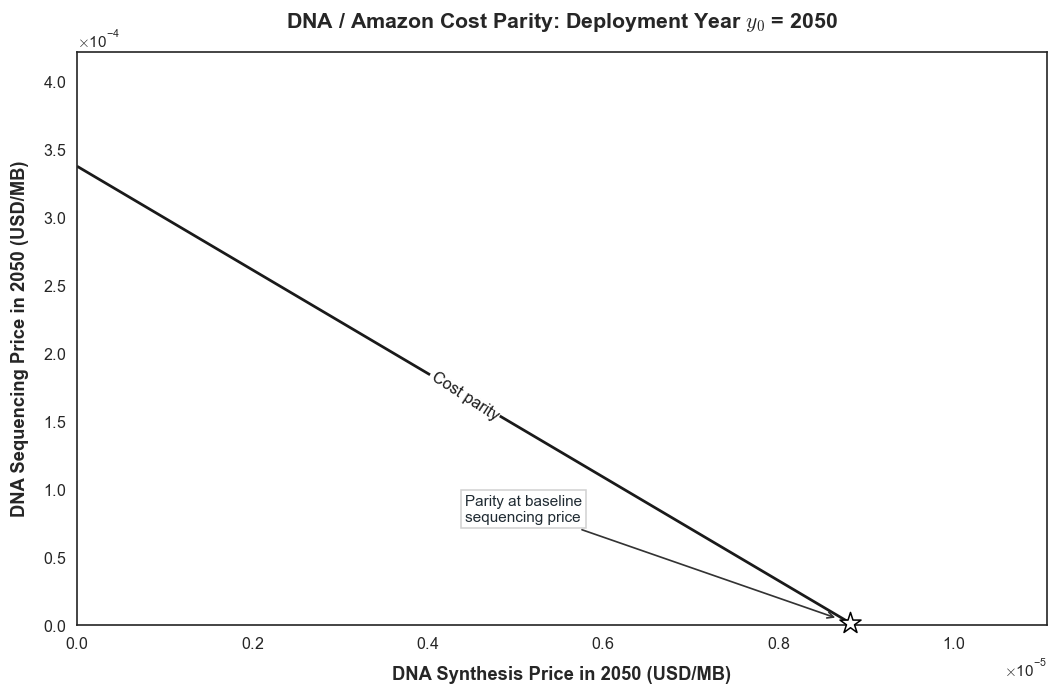

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
DEPLOYMENT_YEAR = FUTURE_START
SYNTHESIS_MAX_USD_PER_MB = None  # None focuses the plot on the parity boundary.
SEQUENCING_MAX_USD_PER_MB = None
GRID_POINTS = 201
s4b_scenario = replace(BASE, start_year=DEPLOYMENT_YEAR, technologies=("DNA", "Amazon Deep Archive"))
age = s4b_scenario.start_year - s4b_scenario.dna_cost_base_year
synthesis_factor = (1 - s4b_scenario.synthesis_decline_percent / 100) ** age
sequencing_factor = (1 - s4b_scenario.sequencing_decline_percent / 100) ** age
# Unit deployment-year prices give exact lifecycle coefficients from the public model.
unit_scenario = replace(s4b_scenario, dna_synthesis_cost_per_mb=1 / synthesis_factor,
                        dna_sequencing_cost_per_mb=1 / sequencing_factor)
unit = simulate_scenario(unit_scenario)
dna = unit.yearly[unit.yearly.technology == "DNA"]
write_coefficient = float(dna.write_cost_usd.sum())
read_coefficient = float(dna.read_cost_usd.sum())
amazon_total = float(unit.totals.set_index("technology").loc["Amazon Deep Archive", "total_cost_usd"])
if write_coefficient <= 0 or amazon_total <= 0:
    raise ValueError("This heatmap requires positive synthesis exposure and Amazon lifecycle cost.")
synthesis_intercept = amazon_total / write_coefficient
sequencing_intercept = amazon_total / read_coefficient if read_coefficient > 0 else np.nan
baseline_synthesis = s4b_scenario.dna_synthesis_cost_per_mb * synthesis_factor
baseline_sequencing = s4b_scenario.dna_sequencing_cost_per_mb * sequencing_factor
synthesis_max = (1.25 * synthesis_intercept if SYNTHESIS_MAX_USD_PER_MB is None
                 else float(SYNTHESIS_MAX_USD_PER_MB))
sequencing_max = (1.25 * sequencing_intercept if np.isfinite(sequencing_intercept)
                  else max(baseline_sequencing * 1.25, 1e-6)) if SEQUENCING_MAX_USD_PER_MB is None else float(SEQUENCING_MAX_USD_PER_MB)
if synthesis_max <= 0 or sequencing_max <= 0:
    raise ValueError("Both price limits must be positive.")
synthesis_prices = np.linspace(0, synthesis_max, GRID_POINTS)
sequencing_prices = np.linspace(0, sequencing_max, GRID_POINTS)
x, y = np.meshgrid(synthesis_prices, sequencing_prices)
dna_cost = write_coefficient * x + read_coefficient * y
ratio = dna_cost / amazon_total
s4b = pd.DataFrame({"synthesis_price_deployment_usd_per_mb": x.ravel(),
                    "sequencing_price_deployment_usd_per_mb": y.ravel(),
                    "synthesis_price_anchor_usd_per_mb": x.ravel() / synthesis_factor,
                    "sequencing_price_anchor_usd_per_mb": y.ravel() / sequencing_factor,
                    "dna_cost_usd": dna_cost.ravel(), "amazon_cost_usd": amazon_total,
                    "cost_ratio": ratio.ravel()})
fig, ax = plt.subplots(figsize=(9.5, 6.2), layout="constrained")
if read_coefficient > 0:
    lower = max(0, (amazon_total - read_coefficient * sequencing_max) / write_coefficient)
    upper = min(synthesis_intercept, synthesis_max)
    parity_x = np.linspace(lower, upper, GRID_POINTS) if lower <= upper else np.array([])
    parity_y = np.maximum(0, (amazon_total - write_coefficient * parity_x) / read_coefficient)
else:
    parity_x = np.full(GRID_POINTS, synthesis_intercept) if synthesis_intercept <= synthesis_max else np.array([])
    parity_y = np.linspace(0, sequencing_max, len(parity_x))
s4b_parity = pd.DataFrame({"synthesis_price_deployment_usd_per_mb": parity_x,
                          "sequencing_price_deployment_usd_per_mb": parity_y})
if len(parity_x):
    from matplotlib.contour import ContourSet
    parity_contour = ContourSet(ax, [0], [[np.column_stack([parity_x, parity_y])]],
                               colors=["0.1"], linewidths=1.8)
    midpoint = len(parity_x) // 2
    ax.clabel(parity_contour, fmt={0: "Cost parity"}, inline=True, inline_spacing=5,
              fontsize=10.5, manual=[(parity_x[midpoint], parity_y[midpoint])])
else:
    ax.text(0.5, 0.5, "No cost parity within the displayed price range",
            transform=ax.transAxes, ha="center", color="0.15")
parity_at_baseline_read = (amazon_total - read_coefficient * baseline_sequencing) / write_coefficient
if 0 <= parity_at_baseline_read <= synthesis_max and 0 <= baseline_sequencing <= sequencing_max:
    ax.scatter(parity_at_baseline_read, baseline_sequencing, marker="*", s=210,
               color="white", edgecolor="black", zorder=5, clip_on=False)
    ax.annotate("Parity at baseline\nsequencing price", (parity_at_baseline_read, baseline_sequencing),
                xytext=(0.46, 0.18), textcoords="axes fraction", ha="center", fontsize=10,
                arrowprops={"arrowstyle": "->", "color": "0.2", "lw": 1.1, "shrinkB": 10},
                bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "0.8", "pad": 2.5})
ax.set_xlim(0, synthesis_max)
ax.set_ylim(0, sequencing_max)
ax.set_xlabel(f"DNA Synthesis Price in {DEPLOYMENT_YEAR} (USD/MB)", fontsize=12, fontweight="bold", color="0.15")
ax.set_ylabel(f"DNA Sequencing Price in {DEPLOYMENT_YEAR} (USD/MB)", fontsize=12, fontweight="bold", color="0.15")
ax.set_title(f"DNA / Amazon Cost Parity: Deployment Year $y_0$ = {DEPLOYMENT_YEAR}",
             fontsize=14, fontweight="bold", color="0.15", pad=16)
ax.ticklabel_format(axis="both", style="sci", scilimits=(0, 0), useMathText=True)
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
ax.grid(False, which="both")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
s4b_reference = pd.DataFrame([{"deployment_year": DEPLOYMENT_YEAR,
    "baseline_synthesis_deployment_usd_per_mb": baseline_synthesis,
    "baseline_sequencing_deployment_usd_per_mb": baseline_sequencing,
    "synthesis_parity_at_baseline_sequencing_usd_per_mb": parity_at_baseline_read,
    "amazon_lifecycle_usd": amazon_total,
    "write_coefficient": write_coefficient, "read_coefficient": read_coefficient}])
record("S4b_joint_synthesis_sequencing_prices", fig,
       f"Joint synthesis and sequencing price sensitivity for DNA/Amazon lifecycle parity. {describe(s4b_scenario)}. "
       f"Both axes are USD per logical MB at deployment in {DEPLOYMENT_YEAR}, not anchor-year prices. "
       f"Synthesis and sequencing decline remain {s4b_scenario.synthesis_decline_percent:.4g}% and "
       f"{s4b_scenario.sequencing_decline_percent:.4g}% per year. Amazon tariffs and all other inputs remain unchanged. "
       "Only the parity boundary is drawn; combinations below it favor DNA and combinations above it favor Amazon. "
       "The exact black boundary includes nonnegative price combinations giving equal full lifecycle costs, "
       "including DNA replacements and retrieval over the retention period. The white star, when in range, "
       "marks parity holding sequencing at its baseline trajectory; it is not the original synthesis baseline. "
       "The default price window focuses on affordable combinations; the fitted baseline synthesis price may "
       "lie outside it and is recorded in the reference CSV. No negative prices are used.",
       {"grid": s4b, "parity": s4b_parity, "reference": s4b_reference}, {"deployment": s4b_scenario})


## S4c: cost-parity curves by deployment year

Search allows DNA price declines from 0% to just below 100%. Amazon price declines stay within 0-20% in S4c and at baseline in S4d. Near-100% annual declines are theoretical scenarios, not forecasts.

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
SYNTHESIS_RANGE = (0.0, float(np.nextafter(100.0, 0.0)))  # All nonnegative declines below 100%.
AMAZON_RANGE = (0.0, 20.0)
YEAR_OFFSETS = (0, 5, 10, 20)
SEARCH_END = 2500 - max(YEAR_OFFSETS)
SEARCH_START = max(BASE.start_year, BASE.dna_cost_base_year, BASE.amazon_price_base_year)

def s4c_cost_functions(year):
    scenario = replace(BASE, start_year=int(year), technologies=("DNA", "Amazon Deep Archive"))
    reference = simulate_scenario(replace(scenario, synthesis_decline_percent=0,
                                         amazon_decline_percent=0)).yearly
    dna = reference[reference.technology == "DNA"]
    amazon = reference[reference.technology == "Amazon Deep Archive"]
    write = dna.write_cost_usd.to_numpy()
    read = float(dna.read_cost_usd.sum())
    cloud = amazon.total_cost_usd.to_numpy()
    dna_age = dna.year.to_numpy() - scenario.dna_cost_base_year
    cloud_age = amazon.year.to_numpy() - scenario.amazon_price_base_year
    def dna_total(rate):
        return float(np.dot(write, np.power(1 - rate / 100, dna_age)) + read)
    def cloud_total(rate):
        return float(np.dot(cloud, np.power(1 - rate / 100, cloud_age)))
    return scenario, dna_total, cloud_total

# In this nonnegative-age domain, both costs decrease monotonically with their own decline rate.
audit_rows = []
first_viable_year = None
for year in range(SEARCH_START, SEARCH_END + 1):
    scenario, dna_total, cloud_total = s4c_cost_functions(year)
    best_gap = dna_total(SYNTHESIS_RANGE[1]) - cloud_total(AMAZON_RANGE[0])
    worst_gap = dna_total(SYNTHESIS_RANGE[0]) - cloud_total(AMAZON_RANGE[1])
    parity_possible = best_gap <= 0 <= worst_gap
    audit_rows.append({"deployment_year": year, "best_dna_minus_amazon_usd": best_gap,
                       "worst_dna_minus_amazon_usd": worst_gap, "parity_possible": parity_possible})
    if parity_possible:
        first_viable_year = year
        break
if first_viable_year is None:
    raise ValueError("No deployment year has parity in the chosen decline ranges within the search interval.")
deployment_years = [first_viable_year + offset for offset in YEAR_OFFSETS]
s4c_scenarios = {}
fig, ax = plt.subplots(figsize=(4.4, 4.7), layout="constrained")
curve_rows = []
for index, year in enumerate(deployment_years):
    scenario, dna_total, cloud_total = s4c_cost_functions(year)
    s4c_scenarios[str(year)] = scenario
    if index == 0:
        synthesis_grid = np.linspace(*SYNTHESIS_RANGE, 201)
        amazon_grid = np.linspace(*AMAZON_RANGE, 121)
        dna_values = np.array([dna_total(rate) for rate in synthesis_grid])
        amazon_values = np.array([cloud_total(rate) for rate in amazon_grid])
        z = np.log10(dna_values[None, :] / amazon_values[:, None])
        limit = max(1.0, float(np.ceil(np.abs(z).max())))
        grid_x, grid_y = np.meshgrid(synthesis_grid, amazon_grid)
        s4c_grid = pd.DataFrame({"deployment_year": year,
            "synthesis_decline_percent": grid_x.ravel(), "amazon_decline_percent": grid_y.ravel(),
            "log10_cost_ratio": z.ravel()})
    cloud_samples = np.linspace(*AMAZON_RANGE, 201)
    # Include exact intersections with the plot edges, even for a very short first-year curve.
    edge_rates = [parity_root(lambda rate: dna_total(synthesis_rate) - cloud_total(rate), *AMAZON_RANGE)
                  for synthesis_rate in SYNTHESIS_RANGE]
    cloud_samples = np.unique(np.r_[cloud_samples, [rate for rate in edge_rates if np.isfinite(rate)]])
    synthesis_samples = []
    for rate in cloud_samples:
        root = parity_root(lambda synthesis: dna_total(synthesis) - cloud_total(rate), *SYNTHESIS_RANGE)
        # Floating-point error at an exact edge can otherwise discard the endpoint.
        if not np.isfinite(root):
            for edge in SYNTHESIS_RANGE:
                if np.isclose(dna_total(edge), cloud_total(rate), rtol=1e-10, atol=0):
                    root = edge
        synthesis_samples.append(root)
        if np.isfinite(root):
            curve_rows.append({"deployment_year": year, "synthesis_decline_percent": root,
                "amazon_decline_percent": rate, "dna_cost_usd": dna_total(root),
                "amazon_cost_usd": cloud_total(rate)})
ax.set_xlim(*SYNTHESIS_RANGE)
ax.set_ylim(*AMAZON_RANGE)
ax.set_xlabel("DNA Synthesis Cost\nAnnual Decline (%)", fontsize=10, fontweight="bold", color="0.15")
ax.set_ylabel("Amazon Deep Archive Cost Annual Decline (%)\n(Storage, Upload and Retrieval)", fontsize=10, fontweight="bold", color="0.15")
ax.set_title("DNA / Amazon Cost Parity\nby Deployment Year $y_0$", fontsize=11, fontweight="bold", color="0.15", pad=16)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
ax.tick_params(which="major", labelsize=10, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
ax.grid(False, which="both")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
s4c_parity = pd.DataFrame(curve_rows)
s4c_audit = pd.DataFrame(audit_rows)

from matplotlib.contour import ContourSet
visible = s4c_parity.synthesis_decline_percent.dropna()
if len(visible):
    left = max(SYNTHESIS_RANGE[0], np.floor((visible.min() - 2) / 5) * 5)
    ax.set_xlim(left, SYNTHESIS_RANGE[1])
for index, year in enumerate(deployment_years):
    curve = s4c_parity[s4c_parity.deployment_year == year]
    if curve.empty:
        continue
    points = curve[["synthesis_decline_percent", "amazon_decline_percent"]].to_numpy()
    color = PALETTE[index]
    parity_contour = ContourSet(ax, [0], [[points]], colors=[color], linewidths=1.8)
    target = points[len(points) // 2]
    # Very short edge segments cannot hold an inline label; keep the year beside the segment.
    relative_height = np.ptp(points[:, 1]) / (ax.get_ylim()[1] - ax.get_ylim()[0])
    if relative_height < 0.08:
        near_top = target[1] > np.mean(ax.get_ylim())
        ax.annotate(f"$y_0 = {year}$", target, xytext=(-4, -16 if near_top else 4), textcoords="offset points",
                    fontsize=10, color=color, ha="right", va="top" if near_top else "bottom",
                    arrowprops={"arrowstyle": "->", "color": "black", "lw": 1.1,
                                "relpos": (0.5, 0.0), "patchA": None, "shrinkA": 1, "shrinkB": 0,
                                "mutation_scale": 9})
    else:
        ax.clabel(parity_contour, fmt={0: f"$y_0 = {year}$"}, inline=True, inline_spacing=5,
                  fontsize=10, manual=[tuple(target)])

record("S4c_deployment_year_parity", fig,
       f"DNA/Amazon lifecycle parity contours for deployments in {', '.join(map(str, deployment_years))}. "
       f"The first viable year is {first_viable_year}, searching integer deployments from {SEARCH_START} "
       f"within synthesis declines from 0% up to (but not including) 100%/year and Amazon declines "
       f"{AMAZON_RANGE[0]:g}-{AMAZON_RANGE[1]:g}%/year. This is not the first viable year under "
       "unrestricted assumptions or at the baseline decline rates. Monotonic corner checks establish "
       "whether any cost-equality combination exists in this rectangle; the search audit is exported. "
       "Curves solve full lifecycle parity, with exact edge intersections included. At fixed Amazon decline, "
       "DNA is cheaper to the right of each year's curve. The heatmap applies ONLY to the earliest "
       "deployment year, not to every contour: negative log ratios favor DNA. All original price anchors, "
       f"sequencing decline, workload, and retention remain unchanged: {describe(BASE)}. These are conditional "
       "scenarios, not forecasts. No default parameters have been added to the figure title.",
       {"parity": s4c_parity, "earliest_year_search": s4c_audit, "reference_grid": s4c_grid}, s4c_scenarios)
print(f"First deployment with parity allowing synthesis declines below 100%: {first_viable_year}")


## S4d: synthesis and sequencing decline parity by deployment year

Search allows DNA price declines from 0% to just below 100%. Amazon price declines stay within 0-20% in S4c and at baseline in S4d. Near-100% annual declines are theoretical scenarios, not forecasts.

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
SYNTHESIS_RANGE = (0.0, float(np.nextafter(100.0, 0.0)))  # All nonnegative declines below 100%.
SEQUENCING_RANGE = (0.0, float(np.nextafter(100.0, 0.0)))
YEAR_OFFSETS = (0, 5, 10, 20)
SEARCH_END = 2500 - max(YEAR_OFFSETS)
SEARCH_START = max(BASE.start_year, BASE.dna_cost_base_year, BASE.amazon_price_base_year)

def s4d_cost_functions(year):
    scenario = replace(BASE, start_year=int(year), technologies=("DNA", "Amazon Deep Archive"))
    reference = simulate_scenario(replace(scenario, synthesis_decline_percent=0,
                                         sequencing_decline_percent=0)).yearly
    dna = reference[reference.technology == "DNA"]
    amazon = reference[reference.technology == "Amazon Deep Archive"]
    write = dna.write_cost_usd.to_numpy()
    read = dna.read_cost_usd.to_numpy()
    age = dna.year.to_numpy() - scenario.dna_cost_base_year
    amazon_total = float(amazon.total_cost_usd.sum())
    def dna_total(synthesis_rate, sequencing_rate):
        return float(np.dot(write, np.power(1 - synthesis_rate / 100, age))
                     + np.dot(read, np.power(1 - sequencing_rate / 100, age)))
    return scenario, dna_total, amazon_total

# DNA cost decreases with either decline rate; Amazon retains its baseline trajectory.
audit_rows = []
first_viable_year = None
for year in range(SEARCH_START, SEARCH_END + 1):
    scenario, dna_total, amazon_total = s4d_cost_functions(year)
    best_gap = dna_total(SYNTHESIS_RANGE[1], SEQUENCING_RANGE[1]) - amazon_total
    worst_gap = dna_total(SYNTHESIS_RANGE[0], SEQUENCING_RANGE[0]) - amazon_total
    parity_possible = best_gap <= 0 <= worst_gap
    audit_rows.append({"deployment_year": year, "best_dna_minus_amazon_usd": best_gap,
                       "worst_dna_minus_amazon_usd": worst_gap, "parity_possible": parity_possible})
    if parity_possible:
        first_viable_year = year
        break
if first_viable_year is None:
    raise ValueError("No deployment year has parity in the chosen decline ranges within the search interval.")
deployment_years = [first_viable_year + offset for offset in YEAR_OFFSETS]
s4d_scenarios = {}
fig, ax = plt.subplots(figsize=(4.4, 4.7), layout="constrained")
curve_rows = []
for index, year in enumerate(deployment_years):
    scenario, dna_total, amazon_total = s4d_cost_functions(year)
    s4d_scenarios[str(year)] = scenario
    if index == 0:
        synthesis_grid = np.linspace(*SYNTHESIS_RANGE, 201)
        sequencing_grid = np.linspace(*SEQUENCING_RANGE, 121)
        dna_values = np.array([[dna_total(synthesis, sequencing) for synthesis in synthesis_grid]
                               for sequencing in sequencing_grid])
        z = np.log10(dna_values / amazon_total)
        limit = max(1.0, float(np.ceil(np.abs(z).max())))
        grid_x, grid_y = np.meshgrid(synthesis_grid, sequencing_grid)
        s4d_grid = pd.DataFrame({"deployment_year": year,
            "synthesis_decline_percent": grid_x.ravel(), "sequencing_decline_percent": grid_y.ravel(),
            "log10_cost_ratio": z.ravel()})
    sequencing_samples = np.linspace(*SEQUENCING_RANGE, 201)
    # Include exact intersections with the plot edges, even for a very short first-year curve.
    edge_rates = [parity_root(lambda rate: dna_total(synthesis_rate, rate) - amazon_total, *SEQUENCING_RANGE)
                  for synthesis_rate in SYNTHESIS_RANGE]
    sequencing_samples = np.unique(np.r_[sequencing_samples, [rate for rate in edge_rates if np.isfinite(rate)]])
    synthesis_samples = []
    for rate in sequencing_samples:
        # Preserve the known edge coordinate: re-solving a nearly flat cost function loses it.
        edge_matches = [edge for edge, edge_rate in zip(SYNTHESIS_RANGE, edge_rates)
                        if np.isfinite(edge_rate) and rate == edge_rate]
        root = edge_matches[-1] if edge_matches else parity_root(
            lambda synthesis: dna_total(synthesis, rate) - amazon_total, *SYNTHESIS_RANGE)
        # Floating-point error at an exact edge can otherwise discard the endpoint.
        if not np.isfinite(root):
            for edge in SYNTHESIS_RANGE:
                if np.isclose(dna_total(edge, rate), amazon_total, rtol=1e-10, atol=0):
                    root = edge
        synthesis_samples.append(root)
        if np.isfinite(root):
            curve_rows.append({"deployment_year": year, "synthesis_decline_percent": root,
                "sequencing_decline_percent": rate, "dna_cost_usd": dna_total(root, rate),
                "amazon_cost_usd": amazon_total})
ax.set_xlim(*SYNTHESIS_RANGE)
ax.set_ylim(*SEQUENCING_RANGE)
ax.set_xlabel("DNA Synthesis Cost\nAnnual Decline (%)", fontsize=10, fontweight="bold", color="0.15")
ax.set_ylabel("DNA Sequencing Cost\nAnnual Decline (%)", fontsize=10, fontweight="bold", color="0.15")
ax.set_title("DNA Synthesis / Sequencing Declines\nat Amazon Cost Parity", fontsize=11, fontweight="bold", color="0.15", pad=16)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
ax.tick_params(which="major", labelsize=10, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
ax.grid(False, which="both")
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
s4d_parity = pd.DataFrame(curve_rows)
s4d_audit = pd.DataFrame(audit_rows)

from matplotlib.contour import ContourSet
visible = s4d_parity.synthesis_decline_percent.dropna()
if len(visible):
    left = max(SYNTHESIS_RANGE[0], np.floor((visible.min() - 2) / 5) * 5)
    ax.set_xlim(left, SYNTHESIS_RANGE[1])
for index, year in enumerate(deployment_years):
    curve = s4d_parity[s4d_parity.deployment_year == year]
    if curve.empty:
        continue
    points = curve[["synthesis_decline_percent", "sequencing_decline_percent"]].to_numpy()
    color = PALETTE[index]
    parity_contour = ContourSet(ax, [0], [[points]], colors=[color], linewidths=1.8, zorder=5)
    target = points[len(points) // 2]
    # Very short edge segments cannot hold an inline label; keep the year beside the segment.
    if year == 2027:
        continue  # Its near-100% location is indistinguishable from the boundary at this scale.
    relative_height = np.ptp(points[:, 1]) / (ax.get_ylim()[1] - ax.get_ylim()[0])
    if relative_height < 0.08:
        # The earliest curve lies almost on the 100% spine; mark its true location visibly.
        ax.scatter(*target, s=42, facecolors="white", edgecolors=[color], linewidths=1.5,
                   zorder=6, clip_on=False)
        near_top = target[1] > np.mean(ax.get_ylim())
        ax.annotate(f"$y_0 = {year}$", target, xytext=(-15, -30 if near_top else 12), textcoords="offset points",
                    fontsize=10, color=color, ha="right", va="top" if near_top else "bottom",
                    arrowprops={"arrowstyle": "-", "color": color, "lw": 0.9})
    else:
        inline_labels = ax.clabel(parity_contour, fmt={0: f"$y_0 = {year}$"}, inline=True, inline_spacing=5,
                  fontsize=10, manual=[tuple(target)])
        for label in inline_labels:
            if label.get_rotation() > 180:
                label.set_rotation((label.get_rotation() + 180) % 360)

record("S4d_dna_declines_deployment_parity", fig,
       f"DNA synthesis/sequencing decline combinations giving Amazon lifecycle parity for deployments "
       f"in {', '.join(map(str, deployment_years))}. The first viable deployment is {first_viable_year}, "
       f"searching integer years from {SEARCH_START} within synthesis declines "
       "from 0% up to (but not including) 100%/year for both DNA price components. Amazon's annual decline remains "
       f"{BASE.amazon_decline_percent:g}% throughout. This first year is conditional on these bounds, "
       "not an unrestricted viability date or baseline-rate forecast. Monotonic corner checks establish "
       "whether parity is possible; all earlier searched years are recorded in the audit. "
       "Curves are exact lifecycle parity solutions; higher synthesis or sequencing declines favor DNA. "
       "Each directly labeled line refers to its deployment year. Price anchors, "
       f"archive size, and retention are unchanged: {describe(BASE)}. No default parameters are added to the title.",
       {"parity": s4d_parity, "earliest_year_search": s4d_audit, "reference_grid": s4d_grid}, s4d_scenarios)
print(f"First deployment with parity within the DNA decline ranges: {first_viable_year}")


## S4e: retention vs. archive size

Uses S2d's 2050 synthesis-price calibration by default. Set `USE_PARITY_CALIBRATION = False` for the original fit. All other price trajectories stay unchanged.

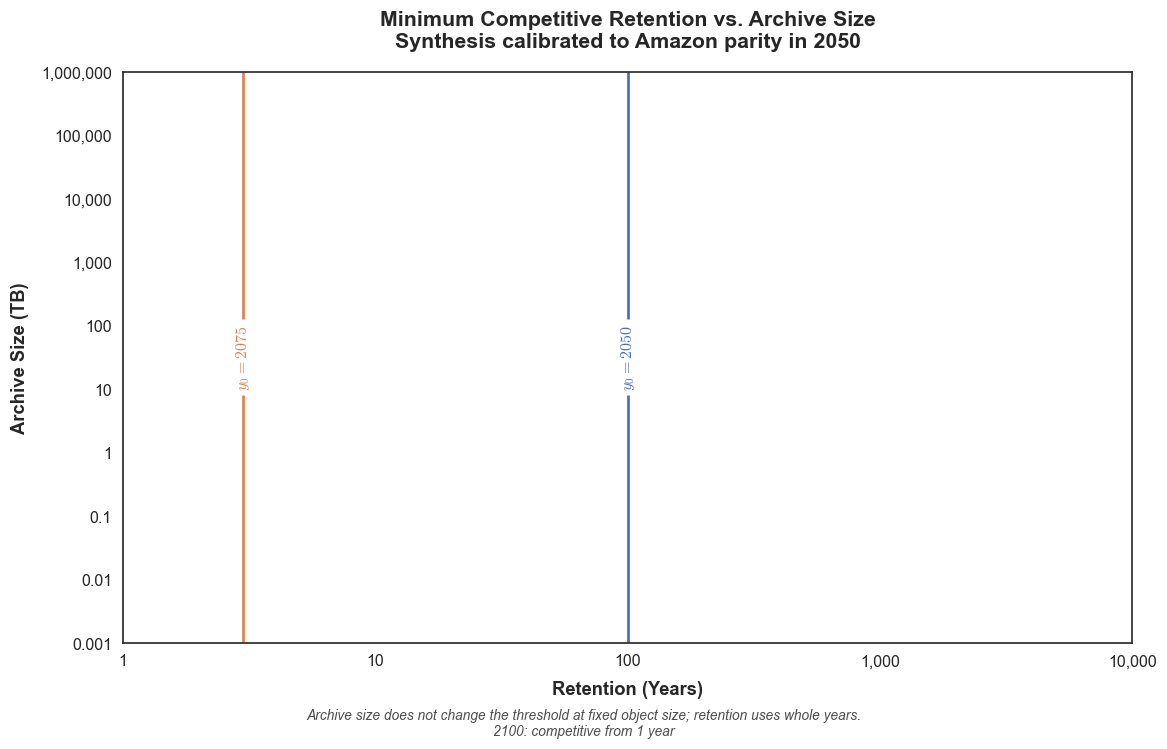

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
USE_PARITY_CALIBRATION = True  # False uses the original fitted synthesis price.
DEPLOYMENT_YEARS = (2050, 2075, 2100)
MAX_RETENTION = 10000
ARCHIVE_RANGE_TB = (0.001, 1000000.0)
workload_base = BASE
if USE_PARITY_CALIBRATION:
    calibration_scenario = replace(BASE, start_year=2050)
    price = threshold_at_start(calibration_scenario).set_index("technology").loc[
        "Amazon Deep Archive", "threshold_start_usd_per_mb"]
    if not np.isfinite(price) or price < 0:
        raise ValueError("No nonnegative synthesis price gives Amazon parity in 2050 with this baseline.")
    workload_base = future_at_price(calibration_scenario, float(price))
scenarios = {str(year): replace(workload_base, start_year=year,
                               technologies=("DNA", "Amazon Deep Archive")) for year in DEPLOYMENT_YEARS}

def workload_costs(scenario, horizon):
    probe = replace(scenario, horizon_years=int(horizon))
    result = simulate_scenario(probe).yearly
    volume = simulate_scenario(replace(probe, amazon_put_usd_per_request=0,
                                      amazon_bulk_restore_usd_per_request=0)).yearly
    dna = result[result.technology == "DNA"].total_cost_usd.to_numpy().cumsum()
    cloud = result[result.technology == "Amazon Deep Archive"].total_cost_usd.to_numpy().cumsum()
    fixed = volume[volume.technology == "Amazon Deep Archive"].total_cost_usd.to_numpy().cumsum()
    # At fixed archive volume, cloud lifecycle cost is A + B / average object size.
    requests = (cloud - fixed) * scenario.average_asset_size_mb
    return dna, fixed, requests

fig, ax = plt.subplots(figsize=(10.5, 6.7), layout="constrained")
rows = []
status_notes = []
from matplotlib.contour import ContourSet

def workload_curve(x, y, year, color):
    points = np.column_stack([x, y])
    valid = np.isfinite(points).all(axis=1) & (points > 0).all(axis=1)
    runs = np.split(np.flatnonzero(valid), np.flatnonzero(np.diff(np.flatnonzero(valid)) > 1) + 1)
    segments = [points[run] for run in runs if len(run) > 1]
    if not segments:
        return
    contour = ContourSet(ax, [0], [segments], colors=[color], linewidths=1.8)
    segment = max(segments, key=len)
    target = segment[len(segment) // 2]
    labels = ax.clabel(contour, fmt={0: f"$y_0 = {year}$"}, inline=True, inline_spacing=5,
                       fontsize=10.5, manual=[tuple(target)])
    for label in labels:
        if label.get_rotation() > 180:
            label.set_rotation((label.get_rotation() + 180) % 360)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1, MAX_RETENTION)
ax.set_ylim(*ARCHIVE_RANGE_TB)
archive_sizes = np.geomspace(*ARCHIVE_RANGE_TB, 101)
for index, (year, scenario) in enumerate(zip(DEPLOYMENT_YEARS, scenarios.values())):
    dna, fixed, requests = workload_costs(scenario, MAX_RETENTION)
    cloud = fixed + requests / scenario.average_asset_size_mb
    # Whole-year retention is the model's domain. A boundary need not be exact equality.
    competitive = dna <= cloud + 1e-12 * np.maximum(dna, cloud)
    first = int(np.flatnonzero(competitive)[0] + 1) if competitive.any() else None
    if first is None:
        status_notes.append(f"{year}: no competitive retention through {MAX_RETENTION:,} years")
    elif first == 1:
        status_notes.append(f"{year}: competitive from 1 year")
    for archive in archive_sizes:
        valid = archive * 1e6 >= scenario.average_asset_size_mb
        rows.append({"deployment_year": year, "archive_size_tb": archive,
            "minimum_retention_years": first if valid and first is not None else np.nan,
            "status": "object_exceeds_archive" if not valid else
                ("no_competitive_retention" if first is None else "first_competitive_retention")})
    valid_sizes = archive_sizes[archive_sizes * 1e6 >= scenario.average_asset_size_mb]
    if first is not None and first > 1 and len(valid_sizes):
        workload_curve(np.full(len(valid_sizes), first), valid_sizes, year, PALETTE[index])

ax.set_xlabel("Retention (Years)", fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel("Archive Size (TB)", fontsize=12, fontweight="bold", color="0.15", labelpad=8)
price_note = "Synthesis calibrated to Amazon parity in 2050" if USE_PARITY_CALIBRATION else "Original fitted synthesis price"
ax.set_title("Minimum Competitive Retention vs. Archive Size" + "\n" + price_note, fontsize=14, fontweight="bold", color="0.15", pad=16)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.6f}".rstrip("0").rstrip(".")))
    axis.set_minor_formatter(NullFormatter())
ax.grid(False, which="both")
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
note = "Archive size does not change the threshold at fixed object size; retention uses whole years."
if status_notes:
    note += "\n" + "; ".join(status_notes)
fig.supxlabel(note, fontsize=9, fontstyle="italic", color="0.3")
table = pd.DataFrame(rows)
configuration = pd.DataFrame([{
    "uses_2050_price_calibration": USE_PARITY_CALIBRATION,
    "synthesis_anchor_year": workload_base.dna_cost_base_year,
    "synthesis_anchor_usd_per_mb": workload_base.dna_synthesis_cost_per_mb,
    "annual_retrieval_percent": workload_base.annual_retrieval_percent,
    "baseline_archive_tb": workload_base.archive_size_tb,
    "baseline_object_mb": workload_base.average_asset_size_mb,
    "baseline_retention_years": workload_base.horizon_years,
}])
record("S4e_retention_vs_archive_size", fig,
       "Minimum whole-year retention with DNA lifecycle cost no greater than Amazon's, varying archive size while holding average object size fixed. Costs scale proportionally with archive volume, so a vertical boundary is expected. Each boundary is the first qualifying integer horizon, not an interpolated fractional-year equality. A relative 1e-12 tolerance handles roundoff at exact calibration parity. " + f" Price basis: {price_note}. Calibration, when enabled, is performed once at "
       f"{BASE.annual_retrieval_percent:g}% retrieval/year, {BASE.average_asset_size_mb:g} MB/object, "
       f"{BASE.archive_size_tb:g} TB and {BASE.horizon_years:g} years retention. The calibrated anchor price "
       "then follows the original synthesis decline in all deployments. Sequencing, cloud prices, "
       "and their decline rates retain the baseline assumptions. There are no fixed infrastructure costs, "
       "volume discounts, or minimum billable object sizes added to this proportional-cost model. "
       "Sub-byte object thresholds are mathematical extrapolations. Invalid objects larger than their "
       "archive are not plotted. Boundaries and statuses are exported with the configuration.",
       {"boundaries": table, "configuration": configuration}, scenarios)


## S4f: retention vs. average object size

Uses S2d's 2050 synthesis-price calibration by default. Set `USE_PARITY_CALIBRATION = False` for the original fit. All other price trajectories stay unchanged.

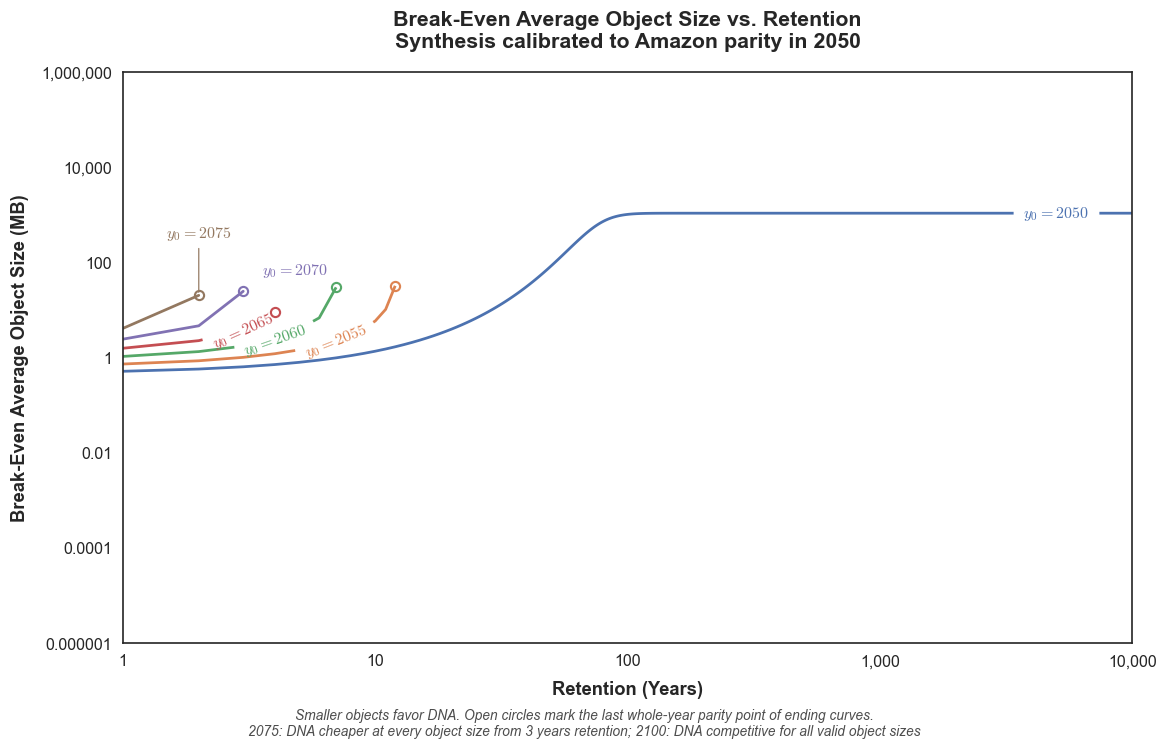

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
USE_PARITY_CALIBRATION = True  # False uses the original fitted synthesis price.
DEPLOYMENT_YEARS = (2050, 2055, 2060, 2065, 2070, 2075, 2100)
MAX_RETENTION = 10000
ARCHIVE_RANGE_TB = (0.001, 1000000.0)
workload_base = BASE
if USE_PARITY_CALIBRATION:
    calibration_scenario = replace(BASE, start_year=2050)
    price = threshold_at_start(calibration_scenario).set_index("technology").loc[
        "Amazon Deep Archive", "threshold_start_usd_per_mb"]
    if not np.isfinite(price) or price < 0:
        raise ValueError("No nonnegative synthesis price gives Amazon parity in 2050 with this baseline.")
    workload_base = future_at_price(calibration_scenario, float(price))
scenarios = {str(year): replace(workload_base, start_year=year,
                               technologies=("DNA", "Amazon Deep Archive")) for year in DEPLOYMENT_YEARS}

def workload_costs(scenario, horizon):
    probe = replace(scenario, horizon_years=int(horizon))
    result = simulate_scenario(probe).yearly
    volume = simulate_scenario(replace(probe, amazon_put_usd_per_request=0,
                                      amazon_bulk_restore_usd_per_request=0)).yearly
    dna = result[result.technology == "DNA"].total_cost_usd.to_numpy().cumsum()
    cloud = result[result.technology == "Amazon Deep Archive"].total_cost_usd.to_numpy().cumsum()
    fixed = volume[volume.technology == "Amazon Deep Archive"].total_cost_usd.to_numpy().cumsum()
    # At fixed archive volume, cloud lifecycle cost is A + B / average object size.
    requests = (cloud - fixed) * scenario.average_asset_size_mb
    return dna, fixed, requests

fig, ax = plt.subplots(figsize=(10.5, 6.7), layout="constrained")
rows = []
status_notes = []
from matplotlib.contour import ContourSet

def workload_curve(x, y, year, color):
    points = np.column_stack([x, y])
    valid = np.isfinite(points).all(axis=1) & (points > 0).all(axis=1)
    runs = np.split(np.flatnonzero(valid), np.flatnonzero(np.diff(np.flatnonzero(valid)) > 1) + 1)
    segments = [points[run] for run in runs if len(run) > 1]
    if not segments:
        return
    contour = ContourSet(ax, [0], [segments], colors=[color], linewidths=1.8)
    segment = max(segments, key=len)
    target = segment[len(segment) // 2]
    labels = ax.clabel(contour, fmt={0: f"$y_0 = {year}$"}, inline=True, inline_spacing=5,
                       fontsize=10.5, manual=[tuple(target)])
    for label in labels:
        if label.get_rotation() > 180:
            label.set_rotation((label.get_rotation() + 180) % 360)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(1, MAX_RETENTION)
ax.set_ylim(1e-6, workload_base.archive_size_mb)
retentions = np.arange(1, MAX_RETENTION + 1)
for index, (year, scenario) in enumerate(zip(DEPLOYMENT_YEARS, scenarios.values())):
    dna, fixed, requests = workload_costs(scenario, MAX_RETENTION)
    gap = dna - fixed
    thresholds = np.divide(requests, gap, out=np.full_like(gap, np.nan), where=(gap > 0) & (requests > 0))
    statuses = np.where(gap <= 0, "DNA_competitive_at_every_object_size",
                       np.where(thresholds > scenario.archive_size_mb, "DNA_competitive_at_every_valid_object_size", "parity"))
    invalid = thresholds > scenario.archive_size_mb
    thresholds[invalid] = np.nan
    for retention, threshold, status in zip(retentions, thresholds, statuses):
        rows.append({"deployment_year": year, "retention_years": int(retention),
                     "object_size_mb": threshold, "status": status})
    if not np.isfinite(thresholds).any():
        status_notes.append(f"{year}: DNA competitive for all valid object sizes")
    color = PALETTE[index % len(PALETTE)]
    valid_indices = np.flatnonzero(np.isfinite(thresholds))
    if len(valid_indices):
        last = valid_indices[-1]
        if last < len(retentions) - 1:
            ax.plot(retentions[last], thresholds[last], "o", color=color,
                    markersize=6, markerfacecolor="none", markeredgewidth=1.4)
        if len(valid_indices) <= 3:
            ax.plot(retentions, thresholds, color=color, linewidth=1.8)
            ax.annotate(f"$y_0 = {year}$", (retentions[last], thresholds[last]),
                        xytext=(0, 35) if year == 2075 else (12, 8),
                        textcoords="offset points", color=color,
                        ha="center" if year == 2075 else "left",
                        arrowprops=dict(arrowstyle="-", color=color, lw=0.8) if year == 2075 else None,
                        fontsize=10.5, va="bottom")
        else:
            workload_curve(retentions, thresholds, year, color)
        if year == 2075 and last < len(retentions) - 1 and np.all(gap[last + 1:] <= 0):
            status_notes.append(f"2075: DNA cheaper at every object size from {retentions[last + 1]} years retention")

ax.set_xlabel("Retention (Years)", fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel("Break-Even Average Object Size (MB)", fontsize=12, fontweight="bold", color="0.15", labelpad=8)
price_note = "Synthesis calibrated to Amazon parity in 2050" if USE_PARITY_CALIBRATION else "Original fitted synthesis price"
ax.set_title("Break-Even Average Object Size vs. Retention" + "\n" + price_note, fontsize=14, fontweight="bold", color="0.15", pad=16)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.6f}".rstrip("0").rstrip(".")))
    axis.set_minor_formatter(NullFormatter())
ax.grid(False, which="both")
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
note = "Smaller objects favor DNA. Open circles mark the last whole-year parity point of ending curves."
if status_notes:
    note += "\n" + "; ".join(status_notes)
fig.supxlabel(note, fontsize=9, fontstyle="italic", color="0.3")
table = pd.DataFrame(rows)
configuration = pd.DataFrame([{
    "uses_2050_price_calibration": USE_PARITY_CALIBRATION,
    "synthesis_anchor_year": workload_base.dna_cost_base_year,
    "synthesis_anchor_usd_per_mb": workload_base.dna_synthesis_cost_per_mb,
    "annual_retrieval_percent": workload_base.annual_retrieval_percent,
    "baseline_archive_tb": workload_base.archive_size_tb,
    "baseline_object_mb": workload_base.average_asset_size_mb,
    "baseline_retention_years": workload_base.horizon_years,
}])
record("S4f_retention_vs_object_size", fig,
       "Average object size giving DNA/Amazon lifecycle parity at each whole-year retention, at fixed archive volume. Curves connect integer-horizon results for display; a durability replacement can cause a jump. Cloud cost is A + B/object_size, solved exactly for object size. Missing thresholds and sub-byte values remain classified in the CSV. Open circles mark the last whole-year parity point before a curve ends; curves are not extrapolated into horizons without a valid parity threshold. " + f" Price basis: {price_note}. Calibration, when enabled, is performed once at "
       f"{BASE.annual_retrieval_percent:g}% retrieval/year, {BASE.average_asset_size_mb:g} MB/object, "
       f"{BASE.archive_size_tb:g} TB and {BASE.horizon_years:g} years retention. The calibrated anchor price "
       "then follows the original synthesis decline in all deployments. Sequencing, cloud prices, "
       "and their decline rates retain the baseline assumptions. There are no fixed infrastructure costs, "
       "volume discounts, or minimum billable object sizes added to this proportional-cost model. "
       "Sub-byte object thresholds are mathematical extrapolations. Invalid objects larger than their "
       "archive are not plotted. Boundaries and statuses are exported with the configuration.",
       {"boundaries": table, "configuration": configuration}, scenarios)


## S4g: archive size vs. average object size

Uses S2d's 2050 synthesis-price calibration by default. Set `USE_PARITY_CALIBRATION = False` for the original fit. All other price trajectories stay unchanged.

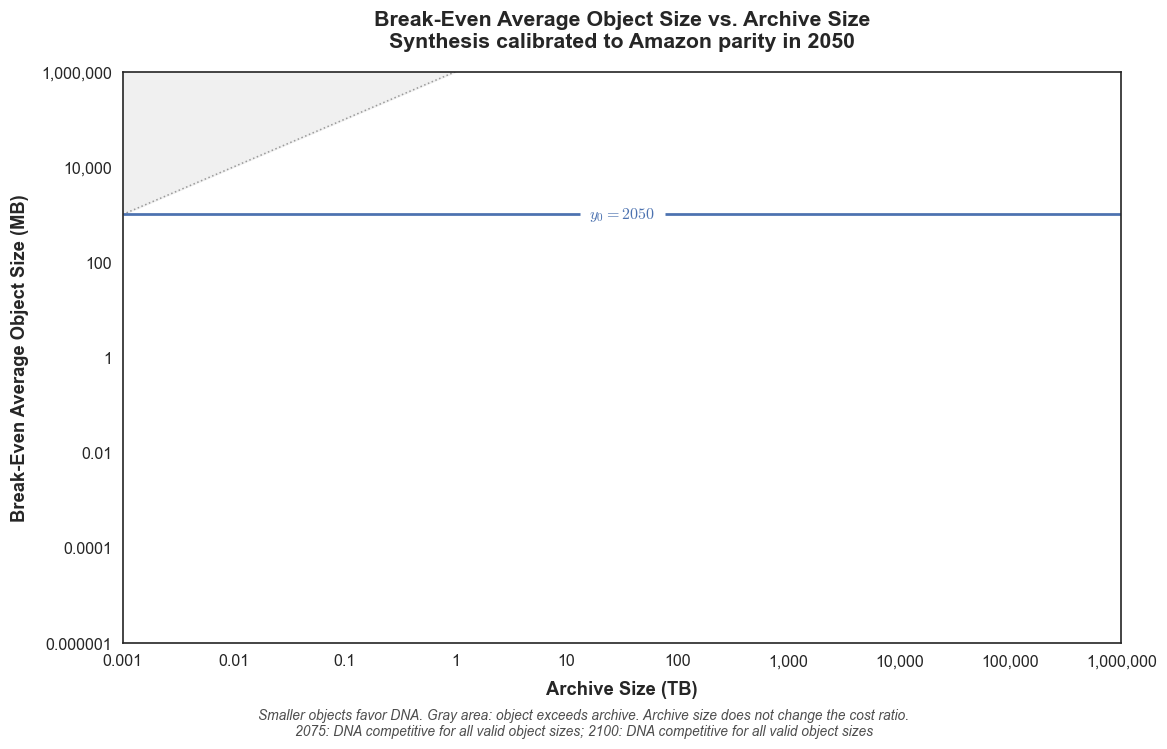

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
USE_PARITY_CALIBRATION = True  # False uses the original fitted synthesis price.
DEPLOYMENT_YEARS = (2050, 2075, 2100)
MAX_RETENTION = 10000
ARCHIVE_RANGE_TB = (0.001, 1000000.0)
workload_base = BASE
if USE_PARITY_CALIBRATION:
    calibration_scenario = replace(BASE, start_year=2050)
    price = threshold_at_start(calibration_scenario).set_index("technology").loc[
        "Amazon Deep Archive", "threshold_start_usd_per_mb"]
    if not np.isfinite(price) or price < 0:
        raise ValueError("No nonnegative synthesis price gives Amazon parity in 2050 with this baseline.")
    workload_base = future_at_price(calibration_scenario, float(price))
scenarios = {str(year): replace(workload_base, start_year=year,
                               technologies=("DNA", "Amazon Deep Archive")) for year in DEPLOYMENT_YEARS}

def workload_costs(scenario, horizon):
    probe = replace(scenario, horizon_years=int(horizon))
    result = simulate_scenario(probe).yearly
    volume = simulate_scenario(replace(probe, amazon_put_usd_per_request=0,
                                      amazon_bulk_restore_usd_per_request=0)).yearly
    dna = result[result.technology == "DNA"].total_cost_usd.to_numpy().cumsum()
    cloud = result[result.technology == "Amazon Deep Archive"].total_cost_usd.to_numpy().cumsum()
    fixed = volume[volume.technology == "Amazon Deep Archive"].total_cost_usd.to_numpy().cumsum()
    # At fixed archive volume, cloud lifecycle cost is A + B / average object size.
    requests = (cloud - fixed) * scenario.average_asset_size_mb
    return dna, fixed, requests

fig, ax = plt.subplots(figsize=(10.5, 6.7), layout="constrained")
rows = []
status_notes = []
from matplotlib.contour import ContourSet

def workload_curve(x, y, year, color):
    points = np.column_stack([x, y])
    valid = np.isfinite(points).all(axis=1) & (points > 0).all(axis=1)
    runs = np.split(np.flatnonzero(valid), np.flatnonzero(np.diff(np.flatnonzero(valid)) > 1) + 1)
    segments = [points[run] for run in runs if len(run) > 1]
    if not segments:
        return
    contour = ContourSet(ax, [0], [segments], colors=[color], linewidths=1.8)
    segment = max(segments, key=len)
    target = segment[len(segment) // 2]
    labels = ax.clabel(contour, fmt={0: f"$y_0 = {year}$"}, inline=True, inline_spacing=5,
                       fontsize=10.5, manual=[tuple(target)])
    for label in labels:
        if label.get_rotation() > 180:
            label.set_rotation((label.get_rotation() + 180) % 360)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*ARCHIVE_RANGE_TB)
ax.set_ylim(1e-6, workload_base.archive_size_mb)
archive_sizes = np.geomspace(*ARCHIVE_RANGE_TB, 151)
ax.fill_between(archive_sizes, archive_sizes * 1e6, ARCHIVE_RANGE_TB[1] * 1e6,
                color="0.94", zorder=0)
ax.plot(archive_sizes, archive_sizes * 1e6, color="0.6", ls=":", lw=1)
for index, (year, scenario) in enumerate(zip(DEPLOYMENT_YEARS, scenarios.values())):
    dna, fixed, requests = workload_costs(scenario, scenario.horizon_years)
    gap = dna[-1] - fixed[-1]
    threshold = requests[-1] / gap if gap > 0 and requests[-1] > 0 else np.nan
    points = []
    for archive in archive_sizes:
        valid = np.isfinite(threshold) and threshold <= archive * 1e6
        points.append(threshold if valid else np.nan)
        rows.append({"deployment_year": year, "archive_size_tb": archive,
            "object_size_mb": threshold if valid else np.nan,
            "status": "parity" if valid else "DNA_competitive_at_every_valid_object_size"})
    if not np.isfinite(points).any():
        status_notes.append(f"{year}: DNA competitive for all valid object sizes")
    workload_curve(archive_sizes, points, year, PALETTE[index])

ax.set_xlabel("Archive Size (TB)", fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel("Break-Even Average Object Size (MB)", fontsize=12, fontweight="bold", color="0.15", labelpad=8)
price_note = "Synthesis calibrated to Amazon parity in 2050" if USE_PARITY_CALIBRATION else "Original fitted synthesis price"
ax.set_title("Break-Even Average Object Size vs. Archive Size" + "\n" + price_note, fontsize=14, fontweight="bold", color="0.15", pad=16)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.6f}".rstrip("0").rstrip(".")))
    axis.set_minor_formatter(NullFormatter())
ax.grid(False, which="both")
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
note = "Smaller objects favor DNA. Gray area: object exceeds archive. Archive size does not change the cost ratio."
if status_notes:
    note += "\n" + "; ".join(status_notes)
fig.supxlabel(note, fontsize=9, fontstyle="italic", color="0.3")
table = pd.DataFrame(rows)
configuration = pd.DataFrame([{
    "uses_2050_price_calibration": USE_PARITY_CALIBRATION,
    "synthesis_anchor_year": workload_base.dna_cost_base_year,
    "synthesis_anchor_usd_per_mb": workload_base.dna_synthesis_cost_per_mb,
    "annual_retrieval_percent": workload_base.annual_retrieval_percent,
    "baseline_archive_tb": workload_base.archive_size_tb,
    "baseline_object_mb": workload_base.average_asset_size_mb,
    "baseline_retention_years": workload_base.horizon_years,
}])
record("S4g_archive_vs_object_size", fig,
       "Average object size giving DNA/Amazon lifecycle parity as archive volume varies, at fixed baseline retention. Volume multiplies every cost component, so it cancels from the parity equation and the object-size threshold is horizontal. The gray area is physically invalid: an object exceeds its archive. Where a mathematical threshold exceeds the archive size, every valid object size favors DNA. " + f" Price basis: {price_note}. Calibration, when enabled, is performed once at "
       f"{BASE.annual_retrieval_percent:g}% retrieval/year, {BASE.average_asset_size_mb:g} MB/object, "
       f"{BASE.archive_size_tb:g} TB and {BASE.horizon_years:g} years retention. The calibrated anchor price "
       "then follows the original synthesis decline in all deployments. Sequencing, cloud prices, "
       "and their decline rates retain the baseline assumptions. There are no fixed infrastructure costs, "
       "volume discounts, or minimum billable object sizes added to this proportional-cost model. "
       "Sub-byte object thresholds are mathematical extrapolations. Invalid objects larger than their "
       "archive are not plotted. Boundaries and statuses are exported with the configuration.",
       {"boundaries": table, "configuration": configuration}, scenarios)


## S5 — discounting and the affordable synthesis price

These plots use **present value**, discounting annual costs back to each archive's deployment year. Both panels use rare retrieval (0.001%/year) to allow nonnegative synthesis thresholds, comparing deployments in the baseline and future start years. A larger discount rate discounts ongoing storage bills more than DNA's up-front synthesis, often lowering the affordable synthesis price. Discounting is distinct from technological cost decline.

Saved S5_discounting_synthesis_threshold: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


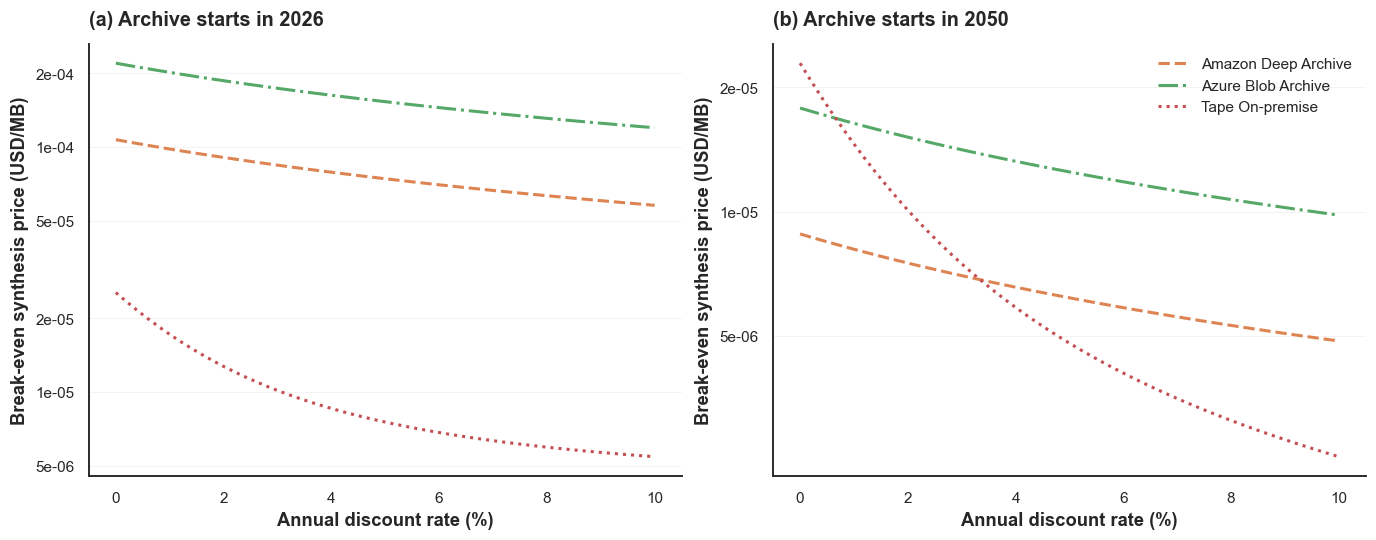

In [44]:
SAVE = True  # False previews only; True exports this figure and its data.
s5_scenarios = {
    "baseline": replace(BASE, annual_retrieval_percent=RARE_RETRIEVAL),
    "future": replace(BASE, start_year=FUTURE_START, annual_retrieval_percent=RARE_RETRIEVAL),
}
rows = []
for label, scenario in s5_scenarios.items():
    for rate in np.linspace(0, 10, 51):
        probe = replace(scenario, discount_rate_percent=float(rate))
        frame = threshold_at_start(probe, present_value=True)
        frame["discount_rate_percent"] = rate
        frame["scenario"] = label
        rows.append(frame)
s5 = pd.concat(rows, ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8), layout="constrained")
for index, ((label, scenario), ax) in enumerate(zip(s5_scenarios.items(), axes)):
    for tech in PEERS:
        frame = s5[(s5.scenario == label) & (s5.technology == tech)]
        ax.plot(frame.discount_rate_percent, frame.threshold_start_usd_per_mb,
                color=COLORS[tech], ls=STYLES[tech], label=tech)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0e}"))
    tidy(ax, "Annual discount rate (%)", "Break-even synthesis price (USD/MB)",
         f"({chr(97 + index)}) Archive starts in {scenario.start_year}")
legend(axes[1], loc="upper right")
record("S5_discounting_synthesis_threshold", fig,
       f"Effect of discounting on the deployment-year synthesis price that gives present-value "
       f"parity with each alternative. Archives start in {BASE.start_year} and {FUTURE_START}; "
       f"retrieval is {RARE_RETRIEVAL:g}%/year in both panels. "
       f"Retention is {BASE.horizon_years} years. The price threshold is in USD/MB in the deployment "
       "year. Annual costs are discounted to that year's beginning, with the initial synthesis "
       "charged at time zero. All technological decline rates remain fixed; missing thresholds "
       "indicate no parity at a nonnegative synthesis price.",
       {"thresholds": s5}, s5_scenarios)

## S6 — when DNA durability matters

Durability is an integer number of years. The plateau starts when durability reaches the retention period: there are then no replacements. Shorter durability may cause additional synthesis writes, producing steps.

The baseline synthesis decline makes distant replacement writes cheap. A second, explicitly labelled **zero-synthesis-decline** scenario isolates how that assumption changes the value of durability. Each curve is normalized to its own no-replacement cost; this is not a comparison of absolute costs between scenarios.

Saved S6_durability_and_replacements: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


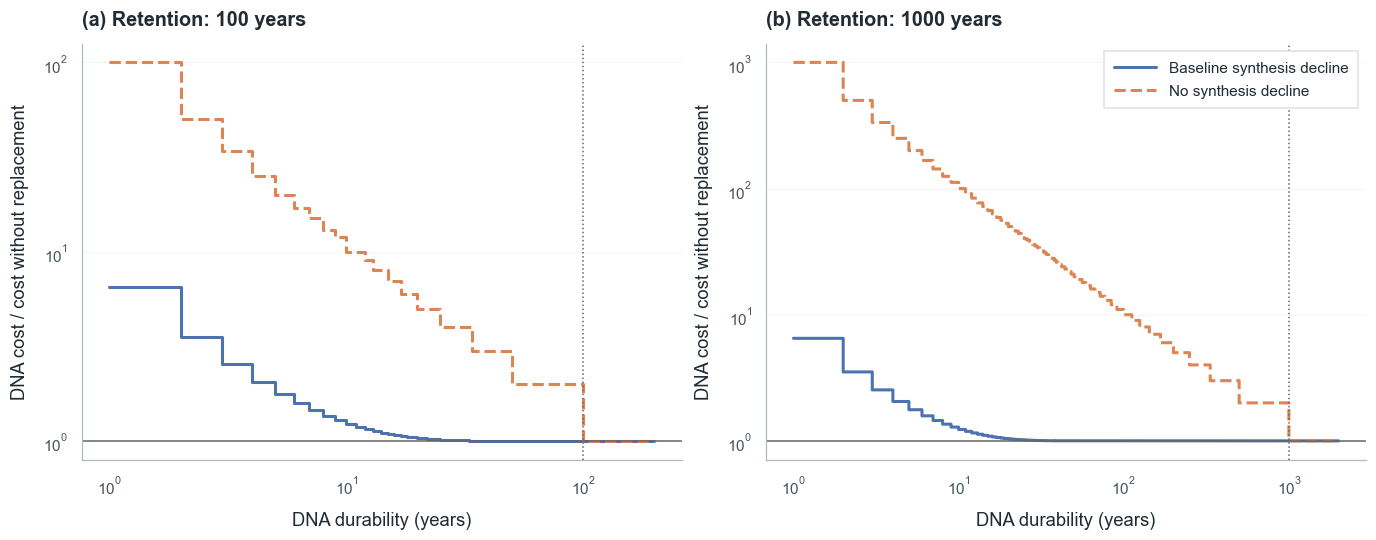

In [30]:
SAVE = True  # False previews only; True exports this figure and its data.
durability_grid = np.arange(1, min(1000, BASE.horizon_years * 2) + 1)
horizons = [BASE.horizon_years, 1000]
s6_scenarios = {
    "Baseline synthesis decline": BASE,
    "No synthesis decline": replace(BASE, synthesis_decline_percent=0.0),
}
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8), layout="constrained")
rows = []
for index, (horizon, ax) in enumerate(zip(horizons, axes)):
    grid = np.unique(np.r_[durability_grid, np.arange(1, horizon * 2 + 1)])
    for curve_index, (label, scenario) in enumerate(s6_scenarios.items()):
        no_replacement = replace(scenario, horizon_years=horizon, dna_durability_years=horizon,
                                 technologies=("DNA",))
        # Evaluate potential writes once with the public engine, then select
        # the integer replacement schedule for each durability.
        annual = simulate_scenario(replace(no_replacement, dna_durability_years=1)).yearly
        potential_writes = annual.write_cost_usd.to_numpy()
        other_cost = float(annual[["read_cost_usd", "maintenance_cost_usd"]].to_numpy().sum())
        reference = float(potential_writes[0] + other_cost)
        values = []
        for durability in grid:
            probe = replace(no_replacement, dna_durability_years=int(durability))
            cost = float(potential_writes[::int(durability)].sum() + other_cost)
            values.append(cost / reference)
            rows.append({"horizon_years": horizon, "durability_years": int(durability),
                         "scenario": label, "synthesis_decline_percent": probe.synthesis_decline_percent,
                         "dna_cost_usd": cost, "no_replacement_cost_usd": reference,
                         "relative_cost": cost / reference,
                         "replacement_count": (horizon - 1) // int(durability)})
        ax.step(grid, values, where="post", color=PALETTE[curve_index],
                ls=("-", "--")[curve_index], label=label)
    ax.axvline(horizon, color="0.4", ls=":", lw=1)
    ax.axhline(1, color="0.4", lw=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    tidy(ax, "DNA durability (years)", "DNA cost / cost without replacement",
         f"({chr(97 + index)}) Retention: {horizon} years")
legend(axes[1], loc="upper right")
record("S6_durability_and_replacements", fig,
       f"DNA lifecycle cost relative to the same scenario without replacement, as durability varies "
       f"in whole years. The archive starts in {BASE.start_year}. Retention is {horizons[0]} years "
       f"in (a) and {horizons[1]} years in (b). Curves compare the baseline synthesis decline "
       f"({BASE.synthesis_decline_percent:.2f}%/year) with zero synthesis decline; sequencing is unchanged. "
       "Each curve has its own no-replacement denominator. Replacement occurs at integer multiples "
       "of durability strictly before the end of the horizon. Vertical dotted lines mark durability "
       "equal to retention; longer durability has no further cost effect in this model.",
       {"durability": pd.DataFrame(rows)}, s6_scenarios)

## S7 — robustness to a nonzero synthesis-cost floor

This is the one extension calculated inside this notebook: replace each year's synthesis price by
\[
p_{\rm synth}(y)=\max\{p_{\rm anchor}(1-r_{\rm synth})^{y-y_{\rm anchor}},\ p_{\min}\}.
\]
All other calculations use the calculator's workload, sequencing, replacement, and tariff conventions. The floor is in **USD per MB**, held constant over calendar time. It is not USD per nucleotide.

The logarithmic plots show total DNA/comparator lifecycle ratios for independently started archives. Nonzero floors can delay or eliminate parity, or make DNA lose an earlier advantage as comparator prices continue falling. A first crossing is therefore not proof of lasting competitiveness. Floor levels are illustrative stress tests, not empirical lower-bound estimates.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved S7_synthesis_cost_floor: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


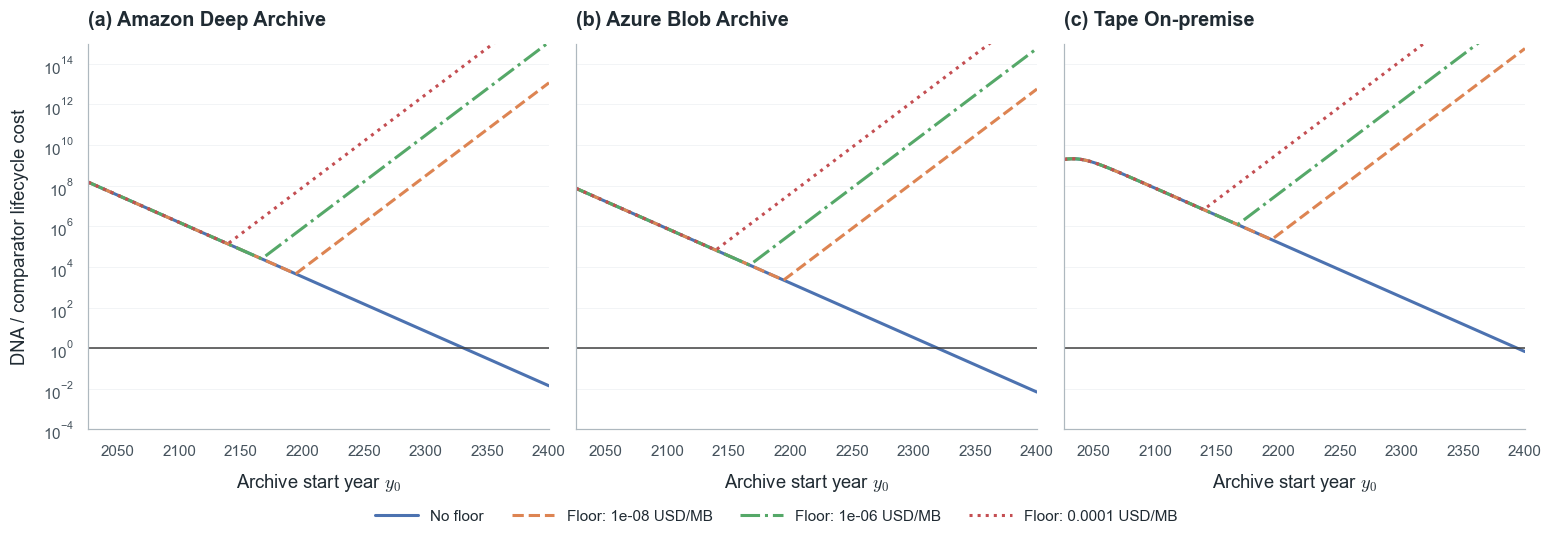

In [31]:
SAVE = True  # False previews only; True exports this figure and its data.
floor_values = [0.0, 1e-8, 1e-6, 1e-4]  # USD/MB; hypothetical, editable
start_years = np.arange(BASE.start_year, FINAL_START + 1)
reference = simulate_start_years(BASE, FINAL_START).pivot(
    index="start_year", columns="technology", values="total_cost_usd")
fig, axes = plt.subplots(1, len(PEERS), figsize=(14, 4.8), sharey=True, layout="constrained")
rows = []
for floor_index, floor in enumerate(floor_values):
    dna_cost = np.array([dna_cost_with_floor(replace(BASE, start_year=int(year)), floor)
                         for year in start_years])
    for ax, tech in zip(axes, PEERS):
        ratio = dna_cost / reference.loc[start_years, tech].to_numpy()
        label = "No floor" if floor == 0 else f"Floor: {floor:g} USD/MB"
        ax.plot(start_years, ratio, color=PALETTE[floor_index],
                ls=("-", "--", "-.", ":")[floor_index], label=label)
        rows.append(pd.DataFrame({"start_year": start_years, "technology": tech,
                                  "floor_usd_per_mb": floor, "dna_cost_usd": dna_cost,
                                  "comparison_cost_usd": reference.loc[start_years, tech].to_numpy(),
                                  "cost_ratio": ratio}))
for index, (ax, tech) in enumerate(zip(axes, PEERS)):
    ax.axhline(1, color="0.25", lw=1)
    ax.set_yscale("log")
    ax.set_xlim(BASE.start_year, FINAL_START)
    ax.set_ylim(1e-4, 1e15)
    tidy(ax, r"Archive start year $y_0$", "DNA / comparator lifecycle cost" if index == 0 else None,
         f"({chr(97 + index)}) {tech}")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
record("S7_synthesis_cost_floor", fig,
       f"Effect of illustrative synthesis-price floors on DNA/comparator lifecycle cost ratios for "
       f"independent archive deployments from {BASE.start_year} through {FINAL_START}. Other settings: "
       f"{describe(BASE)}. Each synthesis price is the larger of the baseline declining price and "
       "the fixed floor (USD/MB), including replacement writes. The horizontal line denotes parity. "
       "Floor levels are sensitivity assumptions, not measured technology limits. Comparator prices "
       "continue to decline under their baseline models. Ratios outside the displayed range are "
       "retained in the CSV; an initial parity crossing need not persist.",
       {"ratios": pd.concat(rows, ignore_index=True)}, {"baseline": BASE})

## S8 — sequencing decline versus Amazon decline

This replaces the **synthesis-decline horizontal axis of S4 with sequencing decline**. Both panels use the same archive and fixed deployment year as S4. Panel (a) holds synthesis at its baseline decline; panel (b) uses the explicitly hypothetical 60% annual synthesis decline set by `HEATMAP_SYNTHESIS_DECLINE`.

At the baseline synthesis trajectory, even free sequencing cannot overcome the up-front write cost in this range, so **no break-even line exists**. The conditional panel shows where faster sequencing can make DNA competitive once synthesis is sufficiently inexpensive. All DNA prices remain anchored as in BASE; the conditional scenario is not a measured trend.

The black boundary is solved numerically for actual cost equality, not inferred from colours. Missing roots remain absent. Both panels share a symmetric colour scale and S4's sign convention: blue favours DNA; red favours Amazon. The star shows baseline sequencing and Amazon declines within each panel, not necessarily the original full baseline.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved S8_sequencing_decline_sensitivity: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


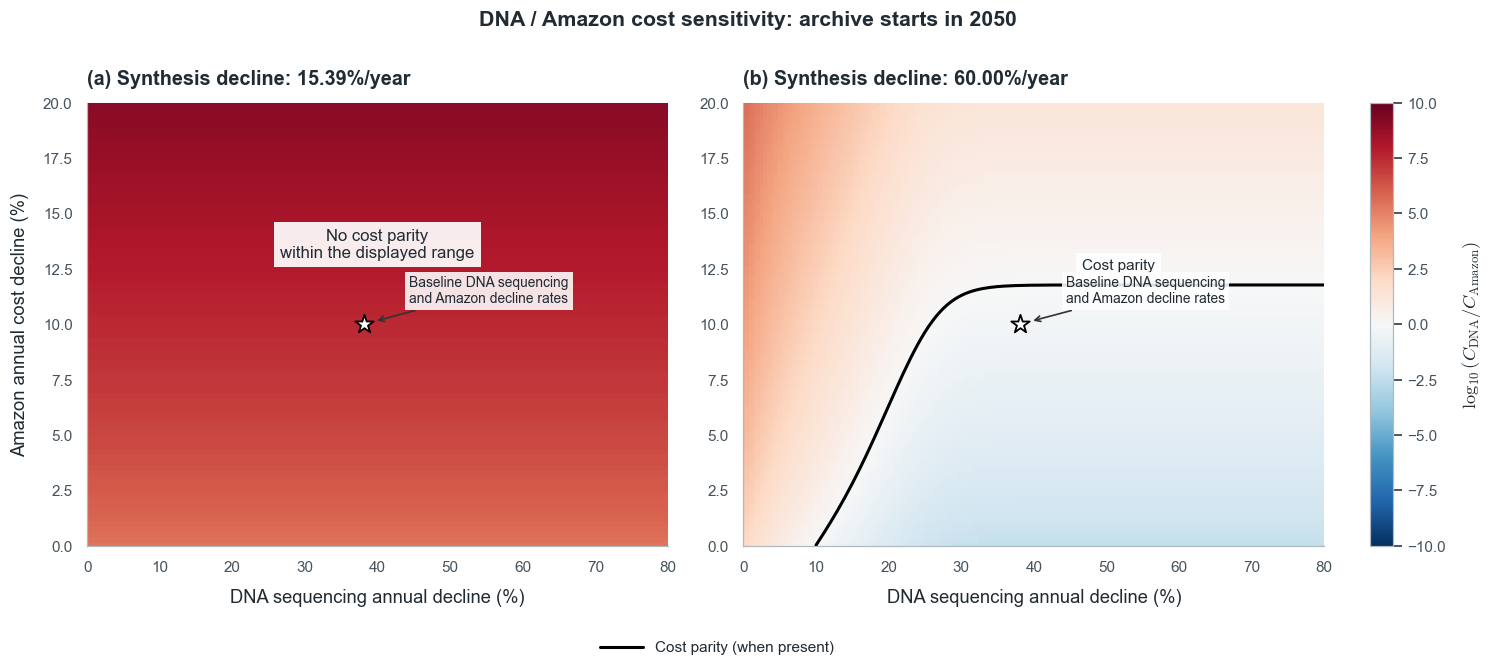

scenario
accelerated_synthesis    141
baseline_synthesis         0
Name: Number of solved parity points, dtype: int64

In [32]:
SAVE = True  # False previews only; True exports this figure and its data.
s8_scenarios = {
    "baseline_synthesis": replace(BASE, start_year=FUTURE_START,
                                 technologies=("DNA", "Amazon Deep Archive")),
    "accelerated_synthesis": replace(BASE, start_year=FUTURE_START,
                                    synthesis_decline_percent=HEATMAP_SYNTHESIS_DECLINE,
                                    technologies=("DNA", "Amazon Deep Archive")),
}
sequencing_grid = np.linspace(0, 80, 161)
s8_cloud_grid = np.linspace(0, 20, 81)
grid_frames, root_rows = [], []
for key, scenario in s8_scenarios.items():
    _, _, dna_total, cloud_total = heatmap_evaluator(scenario, scenario.horizon_years)
    dna_costs = np.array([dna_total(rate, scenario.horizon_years) for rate in sequencing_grid])
    for cloud_rate in s8_cloud_grid:
        peer = cloud_total(cloud_rate, scenario.horizon_years)
        grid_frames.append(pd.DataFrame({
            "scenario": key, "sequencing_decline_percent": sequencing_grid,
            "amazon_decline_percent": cloud_rate, "dna_cost_usd": dna_costs,
            "comparison_cost_usd": peer, "log10_cost_ratio": np.log10(dna_costs / peer),
        }))
    # Solve along each x coordinate, retaining the near-horizontal asymptote.
    for sequencing_rate, dna_cost in zip(sequencing_grid, dna_costs):
        rate = parity_root(
            lambda r: dna_cost - cloud_total(r, scenario.horizon_years),
            float(s8_cloud_grid.min()), float(s8_cloud_grid.max()),
        )
        root_rows.append({
            "scenario": key, "sequencing_decline_percent": sequencing_rate,
            "amazon_decline_percent": rate, "dna_cost_usd": dna_cost,
            "comparison_cost_usd": cloud_total(rate, scenario.horizon_years) if np.isfinite(rate) else np.nan,
            "root_exists": bool(np.isfinite(rate)),
        })
s8 = pd.concat(grid_frames, ignore_index=True)
s8_boundaries = pd.DataFrame(root_rows)
fig = joint_heatmap_panels(
    s8, s8_boundaries, s8_scenarios, "sequencing_decline_percent",
    "DNA sequencing annual decline (%)", BASE.sequencing_decline_percent,
)
record("S8_sequencing_decline_sensitivity", fig,
       f"Joint sensitivity to DNA sequencing and Amazon tariff decline, for an archive starting in "
       f"{FUTURE_START}. Workload: {describe(s8_scenarios['baseline_synthesis'])}. "
       f"Synthesis decline is fixed at {BASE.synthesis_decline_percent:.2f}%/year in (a) and at an "
       f"illustrative {HEATMAP_SYNTHESIS_DECLINE:g}%/year in (b), with the same DNA price anchor. "
       "Sequencing decline spans 0–80%/year and Amazon decline 0–20%/year. "
       "Black lines denote numerically solved lifecycle cost equality; absent lines mean no root "
       "within the displayed range. Colour is the log cost ratio, using a common symmetric scale; "
       "negative values favour DNA. Stars mark baseline sequencing and Amazon inputs. The second "
       "panel is conditional on accelerated synthesis, not a forecast.",
       {"grid": s8, "parity_boundary": s8_boundaries}, s8_scenarios)
display(s8_boundaries.groupby("scenario").root_exists.sum().rename("Number of solved parity points"))

## S8 (2026): sequencing and Amazon declines

Same sweep and price anchors as the 2050 figure, but the archive starts in 2026. With the baseline 100-year retention, the initial synthesis bill is paid immediately at the 2026 price. Later declines cannot reduce that bill, and there is no lifecycle break-even rate at Amazon decline 10%/year. A missing parity contour is intentional, not a plotting error.

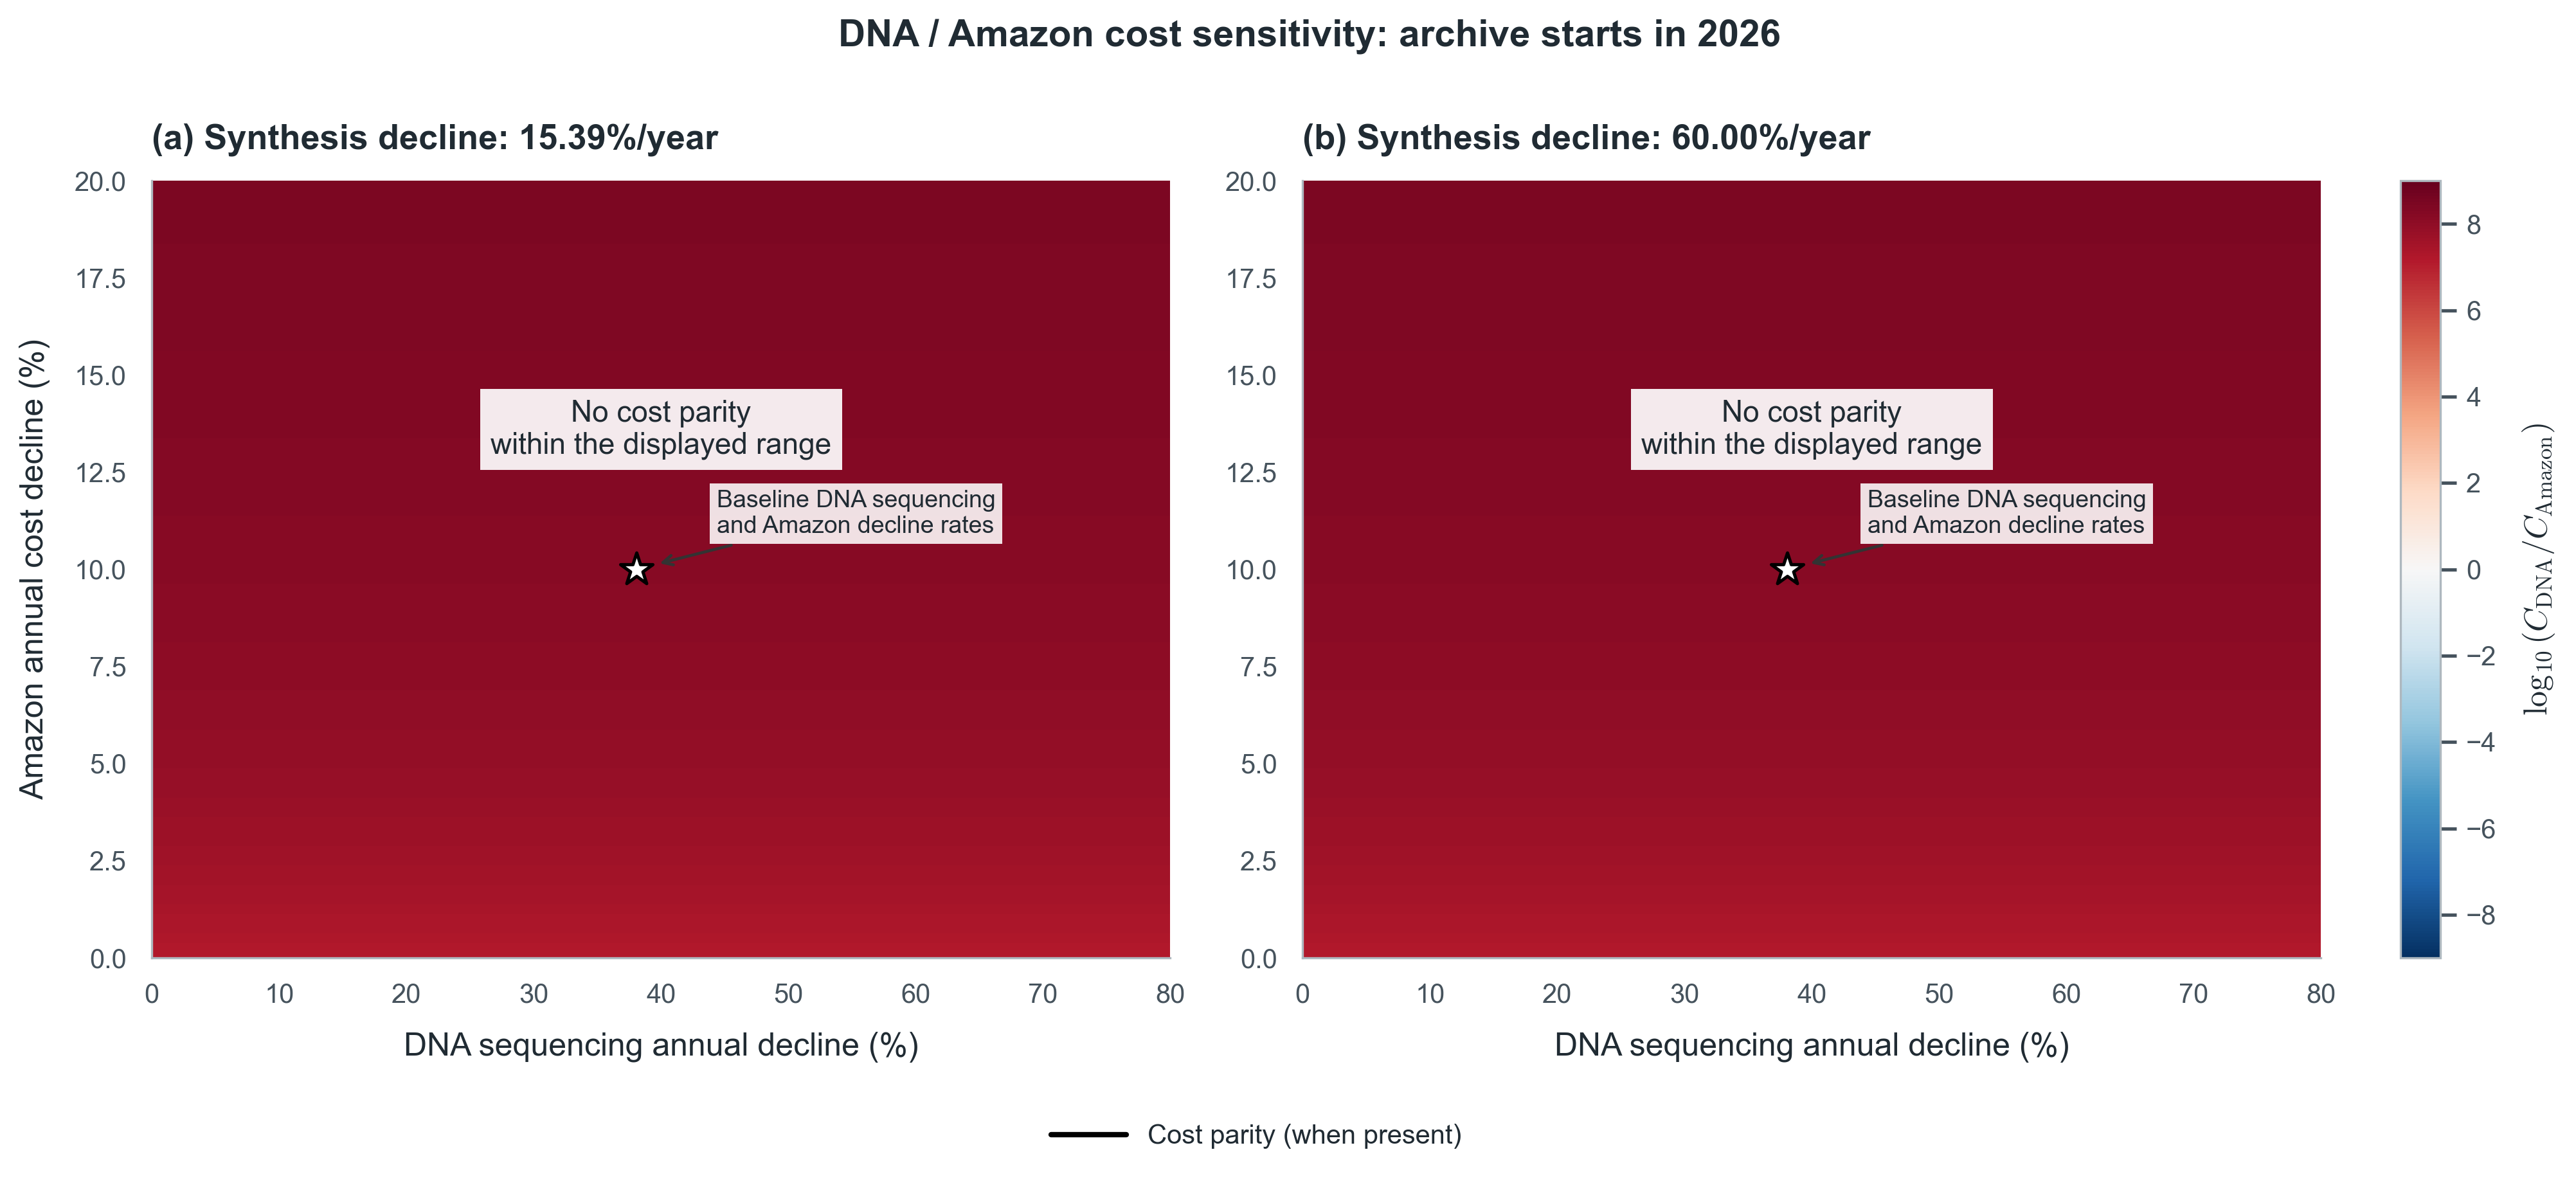

No lifecycle parity for a 2026 deployment at Amazon decline 10%/year.


In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
s8_scenarios = {
    "baseline_synthesis": replace(BASE, start_year=2026,
                                 technologies=("DNA", "Amazon Deep Archive")),
    "accelerated_synthesis": replace(BASE, start_year=2026,
                                    synthesis_decline_percent=HEATMAP_SYNTHESIS_DECLINE,
                                    technologies=("DNA", "Amazon Deep Archive")),
}
sequencing_grid = np.linspace(0, 80, 161)
s8_cloud_grid = np.linspace(0, 20, 81)
grid_frames, root_rows = [], []
for key, scenario in s8_scenarios.items():
    _, _, dna_total, cloud_total = heatmap_evaluator(scenario, scenario.horizon_years)
    dna_costs = np.array([dna_total(rate, scenario.horizon_years) for rate in sequencing_grid])
    for cloud_rate in s8_cloud_grid:
        peer = cloud_total(cloud_rate, scenario.horizon_years)
        grid_frames.append(pd.DataFrame({
            "scenario": key, "sequencing_decline_percent": sequencing_grid,
            "amazon_decline_percent": cloud_rate, "dna_cost_usd": dna_costs,
            "comparison_cost_usd": peer, "log10_cost_ratio": np.log10(dna_costs / peer),
        }))
    # Solve along each x coordinate, retaining the near-horizontal asymptote.
    for sequencing_rate, dna_cost in zip(sequencing_grid, dna_costs):
        rate = parity_root(
            lambda r: dna_cost - cloud_total(r, scenario.horizon_years),
            float(s8_cloud_grid.min()), float(s8_cloud_grid.max()),
        )
        root_rows.append({
            "scenario": key, "sequencing_decline_percent": sequencing_rate,
            "amazon_decline_percent": rate, "dna_cost_usd": dna_cost,
            "comparison_cost_usd": cloud_total(rate, scenario.horizon_years) if np.isfinite(rate) else np.nan,
            "root_exists": bool(np.isfinite(rate)),
        })
s8 = pd.concat(grid_frames, ignore_index=True)
s8_boundaries = pd.DataFrame(root_rows)
fig = joint_heatmap_panels(
    s8, s8_boundaries, s8_scenarios, "sequencing_decline_percent",
    "DNA sequencing annual decline (%)", BASE.sequencing_decline_percent,
)
record("S8_sequencing_decline_sensitivity_2026", fig,
       f"Joint sensitivity to DNA sequencing and Amazon tariff decline, for an archive starting in "
       f"{2026}. Workload: {describe(s8_scenarios['baseline_synthesis'])}. "
       f"Synthesis decline is fixed at {BASE.synthesis_decline_percent:.2f}%/year in (a) and at an "
       f"illustrative {HEATMAP_SYNTHESIS_DECLINE:g}%/year in (b), with the same DNA price anchor. "
       "Sequencing decline spans 0–80%/year and Amazon decline 0–20%/year. "
       "Black lines denote numerically solved lifecycle cost equality; absent lines mean no root "
       "within the displayed range. Colour is the log cost ratio, using a common symmetric scale; "
       "negative values favour DNA. Stars mark baseline sequencing and Amazon inputs. The second "
       "panel is conditional on accelerated synthesis, not a forecast.",
       {"grid": s8, "parity_boundary": s8_boundaries}, s8_scenarios)
display(s8_boundaries.groupby("scenario").root_exists.sum().rename("Number of solved parity points"))
sequencing_threshold_2026 = s8_sequencing_parity(10.0, start_year=2026)
print(f"Sequencing parity: {sequencing_threshold_2026:.6f}%/year" if np.isfinite(sequencing_threshold_2026) else "No sequencing-decline parity for a 2026 deployment at Amazon decline 10%/year.")

## S9 — retention years versus Amazon decline

This replaces S4's horizontal axis with the **retention period**, keeping the deployment year fixed. The horizontal axis is logarithmic and every evaluated retention period is a whole number of years. The panels use the same two synthesis scenarios as S8; sequencing follows its baseline trajectory.

The black line solves for the Amazon annual decline giving cost equality at each sampled integer retention. Thus the line is a boundary between regions, not a claim that fractional retention years were simulated. Lines join sampled solutions for visual guidance; exact roots and integer horizons are exported.

Increasing retention does not guarantee parity: when future tariffs keep declining, their accumulated cost can approach a finite limit. DNA replacement writes are included every 1,000 years, strictly before the retention endpoint. The baseline panel retains its genuine no-parity result through 10,000 years.

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved S9_retention_decline_sensitivity: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


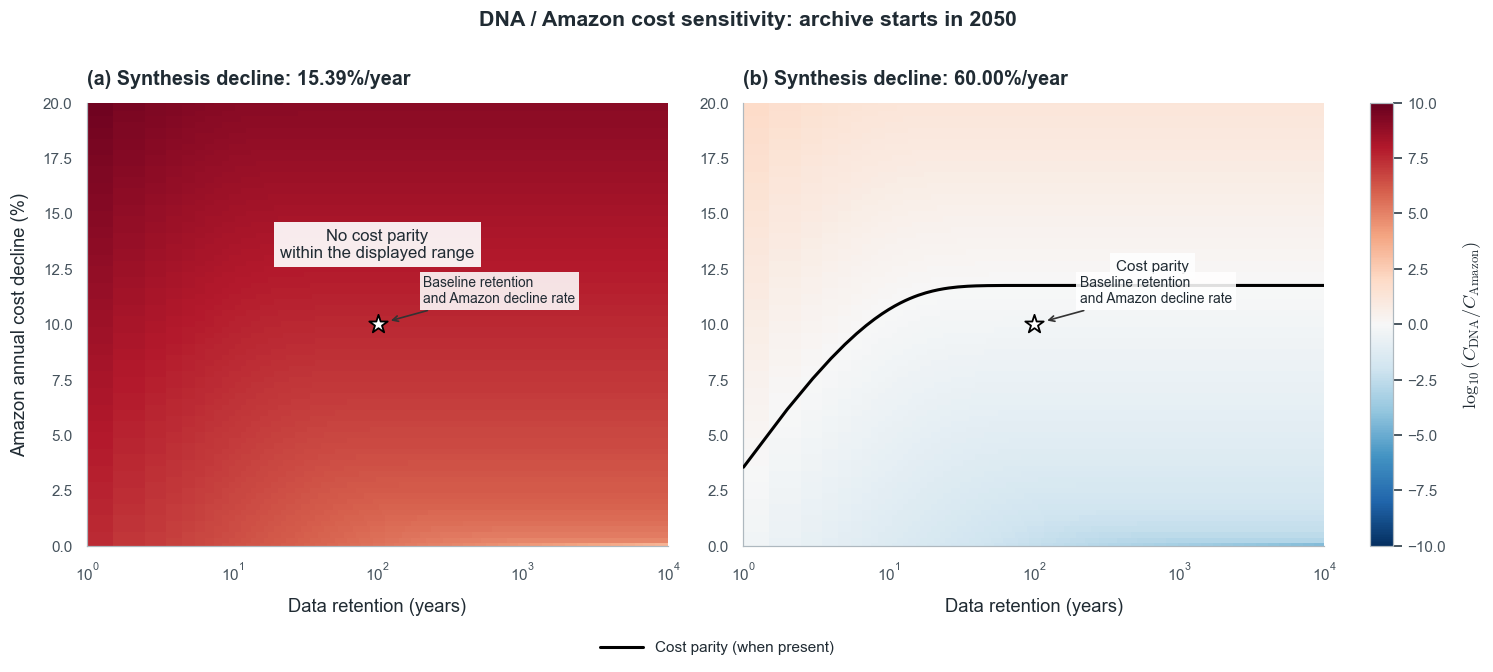

scenario
accelerated_synthesis    156
baseline_synthesis         0
Name: Number of solved parity points, dtype: int64

In [33]:
SAVE = True  # False previews only; True exports this figure and its data.
s9_scenarios = {
    "baseline_synthesis": replace(BASE, start_year=FUTURE_START,
                                 technologies=("DNA", "Amazon Deep Archive")),
    "accelerated_synthesis": replace(BASE, start_year=FUTURE_START,
                                    synthesis_decline_percent=HEATMAP_SYNTHESIS_DECLINE,
                                    technologies=("DNA", "Amazon Deep Archive")),
}
retention_grid = np.unique(np.r_[
    np.round(np.geomspace(1, HEATMAP_MAX_RETENTION, 201)).astype(int),
    BASE.horizon_years, BASE.dna_durability_years,
    BASE.dna_durability_years + 1,
])
retention_grid = retention_grid[(retention_grid >= 1) & (retention_grid <= HEATMAP_MAX_RETENTION)]
s9_cloud_grid = np.linspace(0, 20, 81)
grid_frames, root_rows = [], []
for key, scenario in s9_scenarios.items():
    dna_cumulative, cloud_cumulative, dna_total, cloud_total = heatmap_evaluator(
        scenario, int(retention_grid.max()))
    dna_costs = dna_cumulative(scenario.sequencing_decline_percent)[retention_grid - 1]
    for cloud_rate in s9_cloud_grid:
        peer = cloud_cumulative(cloud_rate)[retention_grid - 1]
        grid_frames.append(pd.DataFrame({
            "scenario": key, "retention_years": retention_grid,
            "amazon_decline_percent": cloud_rate, "dna_cost_usd": dna_costs,
            "comparison_cost_usd": peer, "log10_cost_ratio": np.log10(dna_costs / peer),
        }))
    for horizon, dna_cost in zip(retention_grid, dna_costs):
        rate = parity_root(
            lambda r: dna_cost - cloud_total(r, int(horizon)),
            float(s9_cloud_grid.min()), float(s9_cloud_grid.max()),
        )
        root_rows.append({
            "scenario": key, "retention_years": int(horizon), "amazon_decline_percent": rate,
            "dna_cost_usd": dna_cost,
            "comparison_cost_usd": cloud_total(rate, int(horizon)) if np.isfinite(rate) else np.nan,
            "root_exists": bool(np.isfinite(rate)),
        })
s9 = pd.concat(grid_frames, ignore_index=True)
s9_boundaries = pd.DataFrame(root_rows)
fig = joint_heatmap_panels(
    s9, s9_boundaries, s9_scenarios, "retention_years",
    "Data retention (years)", BASE.horizon_years, log_x=True,
)
record("S9_retention_decline_sensitivity", fig,
       f"Joint sensitivity to data retention and Amazon annual tariff decline, for archives deployed "
       f"in {FUTURE_START}. The archive is {BASE.archive_size_tb:g} TB, with "
       f"{BASE.average_asset_size_mb:g} MB/object and {BASE.annual_retrieval_percent:g}% annual retrieval; retention varies "
       f"from 1 to {HEATMAP_MAX_RETENTION:,} whole years. Synthesis decline is "
       f"{BASE.synthesis_decline_percent:.2f}%/year in (a) and an illustrative "
       f"{HEATMAP_SYNTHESIS_DECLINE:g}%/year in (b); sequencing decline stays at "
       f"{BASE.sequencing_decline_percent:.2f}%/year. Both panels share the same log cost-ratio "
       "colour scale. Black boundaries solve for Amazon decline giving exact cost equality at each "
       "sampled integer retention; connecting lines guide the eye. Stars mark baseline retention and "
       "Amazon decline. Initial writes, annual reads, storage costs, and DNA replacement writes are "
       "included. No parity line is drawn where no solution exists in the sampled parameter domain.",
       {"grid": s9, "parity_boundary": s9_boundaries}, s9_scenarios)
display(s9_boundaries.groupby("scenario").root_exists.sum().rename("Number of solved parity points"))

## S10 — sequencing break-even curves for several synthesis declines

A line-only companion to S8. Each curve fixes the annual synthesis decline at **50%, 55%, 60%, or 65%** and solves for the Amazon annual decline that makes DNA's lifecycle cost equal to Amazon's as sequencing decline varies. These are illustrative scenarios, not empirical estimates.

Amazon decline spans **0–30%/year**, extending S8's 0–20% range so the faster-synthesis scenarios fit. At a given sequencing decline, **below a curve DNA is cheaper; above it Amazon is cheaper**. Missing segments indicate no equality within the displayed range; the CSV distinguishes DNA being more expensive everywhere from being cheaper everywhere. The baseline synthesis scenario is evaluated too and explicitly noted when it has no parity.

The star marks baseline sequencing and Amazon inputs; it does not select one synthesis scenario. Run the setup and helper cells first; this figure is otherwise independent of S8.

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
s10_x = np.linspace(0, 80, 321)
s10, s10_scenarios = synthesis_parity_lines("sequencing", s10_x)
fig = plot_synthesis_parity_lines(s10, "sequencing")

ax = fig.axes[0]
fig.set_size_inches(5.8, 4.4)
ax.grid(False, which="both")
ax.set_title("", loc="left")
ax.set_title(f"DNA / Amazon Cost Parity\nDeployment Year $y_0 = {FUTURE_START}$",
             fontsize=11, fontweight="bold", color="0.15", pad=16)
ax.set_xlabel("DNA Sequencing Cost\nAnnual Decline (%)",
              fontsize=10, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel("Amazon Deep Archive Cost\nAnnual Decline (%)",
              fontsize=10, fontweight="bold", color="0.15", labelpad=8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
ax.tick_params(which="major", labelsize=10, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
baseline_note = ""
for text in list(ax.texts):
    if text.get_text().startswith("Baseline synthesis ("):
        baseline_note = text.get_text().replace("\n", " ")
        text.remove()
    else:
        text.set_fontsize(9)
        text.set_position((14, -15))
        text.set_ha("left")
        text.set_va("top")
        text.set_color("0.15")
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
paper_legend = fig.legend(handles, [label.replace("%/year", "%") for label in labels],
    title="Synthesis decline", loc="outside right center",
    ncol=1, frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
    framealpha=0.9, fontsize=10, title_fontsize=10, handlelength=2,
    handletextpad=0.8, columnspacing=1.8, borderpad=0.7)
paper_legend.get_title().set_fontweight("bold")

record("S10_sequencing_parity_by_synthesis", fig,
       f"Lifecycle cost parity between DNA and Amazon Deep Archive as a function of sequencing decline, "
       f"for archives starting in {FUTURE_START}. Workload: {BASE.archive_size_tb:g} TB; "
       f"{BASE.average_asset_size_mb:g} MB/object; {BASE.annual_retrieval_percent:g}% retrieval/year; "
       f"{BASE.horizon_years} years; no discounting. Each curve fixes synthesis decline at one of "
       f"{', '.join(f'{rate:g}%' for rate in PARITY_SYNTHESIS_RATES)} per year. "
       "The vertical coordinate is the numerically solved Amazon decline giving equal total costs. "
       "Below a curve DNA is cheaper; above it Amazon is cheaper. The Amazon search domain is "
       f"{PARITY_AMAZON_RANGE[0]:g}–{PARITY_AMAZON_RANGE[1]:g}%/year. Missing curve segments have no "
       "parity in this domain. The baseline synthesis scenario is also evaluated. The star marks "
       "baseline sequencing and Amazon inputs, irrespective of synthesis scenario. "
       "All DNA price anchors remain fixed; accelerated synthesis rates are illustrative assumptions.",
       {"parity_boundary": s10}, s10_scenarios)
display(s10.groupby("synthesis_decline_percent").root_exists.sum().rename("Solved parity points"))

## S10b: synthesis break-even curves for several sequencing declines

S10 with synthesis and sequencing exchanged: synthesis decline varies along the x-axis, while each curve fixes sequencing decline at 50%, 55%, 60%, or 65%. The baseline sequencing trajectory is also evaluated. Below each boundary DNA is cheaper; above it Amazon is cheaper. Nearly overlapping curves indicate weak sensitivity to sequencing in this range. This cell is independent of S10; run the two setup cells first.

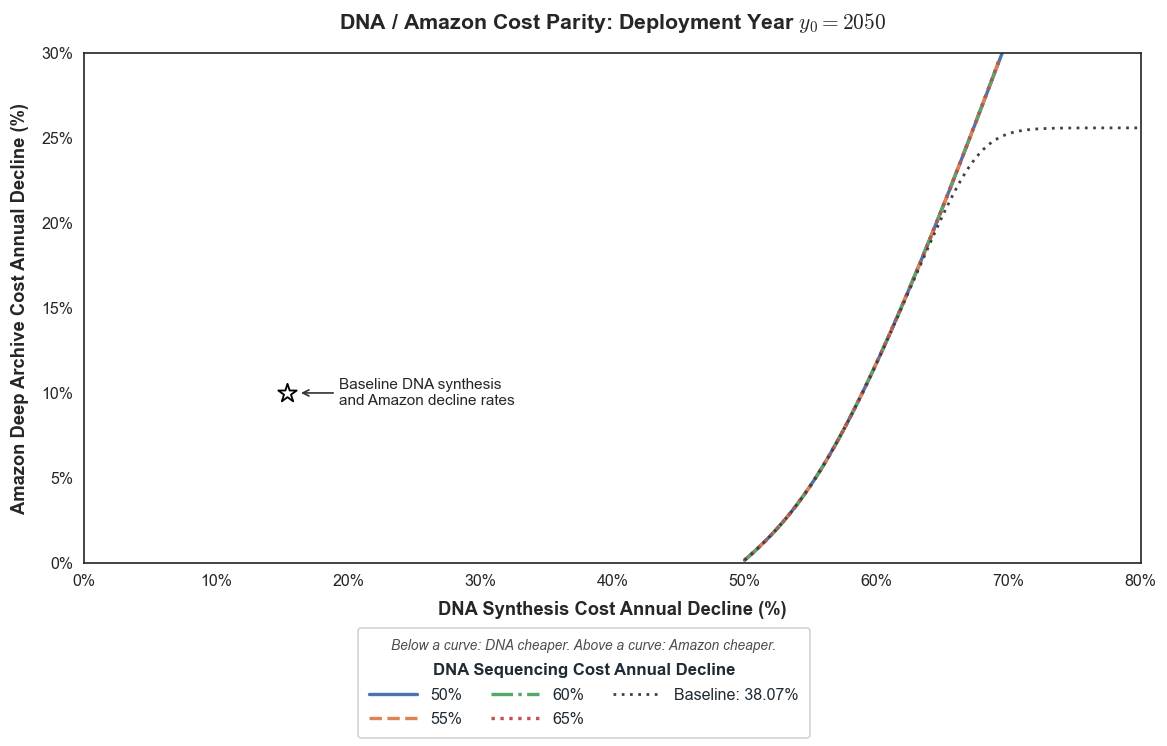

sequencing_decline_percent
38.065945    121
50.000000     79
55.000000     78
60.000000     78
65.000000     78
Name: Solved parity points, dtype: int64

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
SEQUENCING_RATES = (50.0, 55.0, 60.0, 65.0)
s10b_x = np.linspace(0, 80, 321)
s10b_scenarios = {
    f"sequencing_{rate:g}": replace(BASE, start_year=FUTURE_START,
        sequencing_decline_percent=float(rate), technologies=("DNA", "Amazon Deep Archive"))
    for rate in (*SEQUENCING_RATES, float(BASE.sequencing_decline_percent))
}
rows = []
for key, scenario in s10b_scenarios.items():
    # Scale public-model write costs, retaining its workload and replacement years.
    flat = simulate_scenario(replace(scenario, synthesis_decline_percent=0.0,
                                     amazon_decline_percent=0.0)).yearly
    dna = flat[flat.technology == "DNA"]
    amazon = flat[flat.technology == "Amazon Deep Archive"]
    write = dna.write_cost_usd.to_numpy()
    read = dna.read_cost_usd.to_numpy().sum()
    dna_age = dna.year.to_numpy() - scenario.dna_cost_base_year
    cloud_age = amazon.year.to_numpy() - scenario.amazon_price_base_year
    cloud = amazon.total_cost_usd.to_numpy()
    def cloud_total(rate):
        return float(np.dot(cloud, np.power(1 - rate / 100, cloud_age)))
    for synthesis_rate in s10b_x:
        dna_cost = float(np.dot(write, np.power(1 - synthesis_rate / 100, dna_age)) + read)
        def difference(rate):
            return dna_cost - cloud_total(rate)
        cloud_rate = parity_root(difference, *PARITY_AMAZON_RANGE)
        status = ("parity_in_range" if np.isfinite(cloud_rate) else
                  "DNA_more_expensive_throughout_range" if difference(PARITY_AMAZON_RANGE[0]) > 0
                  else "DNA_cheaper_throughout_range")
        rows.append({"scenario": key, "synthesis_decline_percent": float(synthesis_rate),
            "sequencing_decline_percent": scenario.sequencing_decline_percent,
            "retention_years": scenario.horizon_years, "amazon_decline_percent": cloud_rate,
            "dna_cost_usd": dna_cost,
            "comparison_cost_usd": cloud_total(cloud_rate) if np.isfinite(cloud_rate) else np.nan,
            "root_exists": bool(np.isfinite(cloud_rate)), "status": status})
s10b = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10.5, 6.7), layout="constrained")
for index, rate in enumerate(SEQUENCING_RATES):
    part = s10b[s10b.sequencing_decline_percent == rate]
    ax.plot(part.synthesis_decline_percent, part.amazon_decline_percent,
            color=PALETTE[index], ls=("-", "--", "-.", ":")[index], lw=2.2, label=f"{rate:g}%/year")
baseline = s10b[np.isclose(s10b.sequencing_decline_percent, BASE.sequencing_decline_percent)]
if baseline.root_exists.any():
    ax.plot(baseline.synthesis_decline_percent, baseline.amazon_decline_percent,
            color="0.25", ls=(0, (1, 2)), lw=1.8,
            label=f"Baseline: {BASE.sequencing_decline_percent:.2f}%/year")
else:
    ax.text(0.98, 0.98, f"Baseline sequencing ({BASE.sequencing_decline_percent:.2f}%/year):\n"
            "no parity within this range", transform=ax.transAxes)
ax.scatter(BASE.synthesis_decline_percent, BASE.amazon_decline_percent,
           marker="*", s=160, facecolor="white", edgecolor="black", linewidth=1.2, zorder=5)
ax.annotate("Baseline DNA synthesis\nand Amazon decline rates",
            (BASE.synthesis_decline_percent, BASE.amazon_decline_percent),
            xytext=(34, 0), textcoords="offset points", ha="left", va="center", zorder=6,
            arrowprops={"arrowstyle": "->", "color": "0.2", "lw": 1.1, "shrinkB": 9},
            bbox={"facecolor": "white", "alpha": 0.92, "edgecolor": "none", "pad": 2.5})
ax.set_xlim(s10b_x.min(), s10b_x.max())
ax.set_ylim(*PARITY_AMAZON_RANGE)
ax.legend()

ax = fig.axes[0]
fig.set_size_inches(10.5, 6.7)
ax.grid(False, which="both")
ax.set_title("", loc="left")
ax.set_title(f"DNA / Amazon Cost Parity: Deployment Year $y_0 = {FUTURE_START}$",
             fontsize=14, fontweight="bold", color="0.15", pad=16)
ax.set_xlabel("DNA Synthesis Cost Annual Decline (%)",
              fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel("Amazon Deep Archive Cost Annual Decline (%)",
              fontsize=12, fontweight="bold", color="0.15", labelpad=8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
ax.tick_params(which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
baseline_note = ""
for text in list(ax.texts):
    if text.get_text().startswith("Baseline sequencing ("):
        baseline_note = text.get_text().replace("\n", " ")
        text.remove()
    else:
        text.set_fontsize(10)
        text.set_color("0.15")
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
paper_legend = fig.legend(handles, [label.replace("%/year", "%") for label in labels],
    title="DNA Sequencing Cost Annual Decline", loc="outside lower center",
    ncol=3, frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
    framealpha=0.9, fontsize=10.5, title_fontsize=11, handlelength=3,
    handletextpad=0.8, columnspacing=1.8, borderpad=0.7)
paper_legend.get_title().set_fontweight("bold")
from matplotlib.offsetbox import TextArea
legend_note = "Below a curve: DNA cheaper. Above a curve: Amazon cheaper."
if baseline_note:
    legend_note += "\n" + baseline_note
note_box = TextArea(legend_note,
    textprops={"fontsize": 9, "fontstyle": "italic", "color": "0.3", "ha": "center"})
note_box.set_figure(fig)
paper_legend._legend_box.get_children().insert(0, note_box)

record("S10b_synthesis_parity_by_sequencing", fig,
       f"Lifecycle cost parity between DNA and Amazon Deep Archive for deployment in {FUTURE_START}. "
       f"Workload: {BASE.archive_size_tb:g} TB; {BASE.average_asset_size_mb:g} MB/object; "
       f"{BASE.annual_retrieval_percent:g}% retrieval/year; {BASE.horizon_years} years; no discounting. "
       "The x-axis varies annual synthesis cost decline; curves hold annual sequencing cost decline "
       f"at {', '.join(f'{rate:g}%' for rate in SEQUENCING_RATES)}, plus the baseline "
       f"{BASE.sequencing_decline_percent:.2f}%. All DNA price anchors remain fixed. "
       "The y-axis solves Amazon annual decline at equal lifecycle cost. Below a curve DNA is cheaper; "
       "above it Amazon is cheaper. Missing segments have no parity in the Amazon search range "
       f"{PARITY_AMAZON_RANGE[0]:g}-{PARITY_AMAZON_RANGE[1]:g}%. "
       "Curves can nearly coincide where sequencing contributes little to total cost. "
       "The star marks baseline synthesis and Amazon inputs, irrespective of sequencing scenario. "
       "Accelerated sequencing declines are illustrative assumptions, not empirical estimates.",
       {"parity_boundary": s10b}, s10b_scenarios)
display(s10b.groupby("sequencing_decline_percent").root_exists.sum().rename("Solved parity points"))


## S11 — retention break-even curves for several synthesis declines

A line-only companion to S9 using the same synthesis scenarios and colours as S10. Sequencing follows its baseline trajectory; each curve solves for Amazon decline at equal lifecycle cost as **integer retention years** vary from 1 to 10,000 on a logarithmic axis.

At a fixed retention, **below a curve DNA is cheaper; above it Amazon is cheaper**. The curves can approach a plateau because future cloud costs decline. DNA replacement writes are included at the model's durability intervals. Lines join solved integer-retention points for visual guidance and never substitute a fractional horizon into the model.

The star marks baseline retention and Amazon decline, not a synthesis scenario. Run the setup and helper cells first; this figure is otherwise independent of S9 and S10.

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
s11_x = np.unique(np.r_[
    np.round(np.geomspace(1, HEATMAP_MAX_RETENTION, 241)).astype(int),
    BASE.horizon_years, BASE.dna_durability_years, BASE.dna_durability_years + 1,
])
s11_x = s11_x[(s11_x >= 1) & (s11_x <= HEATMAP_MAX_RETENTION)]
s11, s11_scenarios = synthesis_parity_lines("retention", s11_x)
fig = plot_synthesis_parity_lines(s11, "retention")

ax = fig.axes[0]
fig.set_size_inches(5.8, 4.4)
ax.grid(False, which="both")
ax.set_title("", loc="left")
ax.set_title(f"DNA / Amazon Cost Parity\nDeployment Year $y_0 = {FUTURE_START}$",
             fontsize=11, fontweight="bold", color="0.15", pad=16)
ax.set_xlabel("Retention\n(Years)",
              fontsize=10, fontweight="bold", color="0.15", labelpad=8)
ax.set_ylabel("Amazon Deep Archive Cost\nAnnual Decline (%)",
              fontsize=10, fontweight="bold", color="0.15", labelpad=8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))
ax.tick_params(which="major", labelsize=10, colors="0.15", length=0, pad=7)
ax.tick_params(which="minor", length=0)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("0.15")
    spine.set_linewidth(1.1)
baseline_note = ""
for text in list(ax.texts):
    if text.get_text().startswith("Baseline synthesis ("):
        baseline_note = text.get_text().replace("\n", " ")
        text.remove()
    else:
        text.set_fontsize(9)
        text.set_position((0, -13))
        text.set_ha("center")
        text.set_va("top")
        text.set_color("0.15")
handles, labels = ax.get_legend_handles_labels()
ax.get_legend().remove()
paper_legend = fig.legend(handles, [label.replace("%/year", "%") for label in labels],
    title="Synthesis decline", loc="outside right center",
    ncol=1, frameon=True, fancybox=True, facecolor="white", edgecolor="0.8",
    framealpha=0.9, fontsize=10, title_fontsize=10, handlelength=2,
    handletextpad=0.8, columnspacing=1.8, borderpad=0.7)
paper_legend.get_title().set_fontweight("bold")

record("S11_retention_parity_by_synthesis", fig,
       f"Lifecycle cost parity between DNA and Amazon Deep Archive as a function of retention, "
       f"for archives deployed in {FUTURE_START}. The archive is {BASE.archive_size_tb:g} TB with "
       f"{BASE.average_asset_size_mb:g} MB/object and {BASE.annual_retrieval_percent:g}% retrieval/year. "
       f"Synthesis declines are {', '.join(f'{rate:g}%' for rate in PARITY_SYNTHESIS_RATES)} per year; "
       f"sequencing decline remains {BASE.sequencing_decline_percent:.2f}%/year. There is no discounting. "
       f"Retention ranges from 1 to {HEATMAP_MAX_RETENTION:,} whole years; replacement writes are included. "
       "Each line gives the Amazon annual decline at exact cost equality for sampled integer "
       "retentions; the connecting lines guide the eye. Below each curve DNA is cheaper; above it "
       "Amazon is cheaper. Missing segments indicate no equality in the "
       f"{PARITY_AMAZON_RANGE[0]:g}–{PARITY_AMAZON_RANGE[1]:g}% Amazon-decline range. The baseline synthesis "
       "case is also evaluated. The star marks baseline retention and Amazon decline. "
       "The accelerated synthesis rates are illustrative, with fixed price anchors.",
       {"parity_boundary": s11}, s11_scenarios)
display(s11.groupby("synthesis_decline_percent").root_exists.sum().rename("Solved parity points"))

## S10 + S11: combined parity figure

Two panels with a shared legend. Run after the setup cells; standalone S10 and S11 remain available.


In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
FIGURE_SIZE = (10.5, 4.5)  # Width and height in inches, including the shared legend.

sequencing_x = np.linspace(0, 80, 321)
retention_x = np.unique(np.r_[
    np.round(np.geomspace(1, HEATMAP_MAX_RETENTION, 241)).astype(int),
    BASE.horizon_years, BASE.dna_durability_years, BASE.dna_durability_years + 1,
])
retention_x = retention_x[(retention_x >= 1) & (retention_x <= HEATMAP_MAX_RETENTION)]
sequencing_data, sequencing_scenarios = synthesis_parity_lines("sequencing", sequencing_x)
retention_data, retention_scenarios = synthesis_parity_lines("retention", retention_x)

fig = plt.figure(figsize=FIGURE_SIZE, layout="constrained")
grid = fig.add_gridspec(1, 3, width_ratios=(1, 1, 0.48))
axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[0, 1])]
legend_ax = fig.add_subplot(grid[0, 2])
legend_ax.set_axis_off()
for ax, frame, kind, panel in zip(
        axes, (sequencing_data, retention_data), ("sequencing", "retention"), ("a", "b")):
    column = "sequencing_decline_percent" if kind == "sequencing" else "retention_years"
    for index, rate in enumerate(PARITY_SYNTHESIS_RATES):
        part = frame[frame.synthesis_decline_percent == rate].sort_values(column)
        ax.plot(part[column], part.amazon_decline_percent, color=PALETTE[index],
                ls=("-", "--", "-.", ":")[index], lw=2.2, label=f"{rate:g}%")
    baseline = frame[np.isclose(frame.synthesis_decline_percent, BASE.synthesis_decline_percent)]
    if baseline.root_exists.any():
        ax.plot(baseline[column], baseline.amazon_decline_percent, color="0.25",
                ls=(0, (1, 2)), label=f"Baseline: {BASE.synthesis_decline_percent:.2f}%")
    reference_x = BASE.sequencing_decline_percent if kind == "sequencing" else BASE.horizon_years
    ax.scatter(reference_x, BASE.amazon_decline_percent, marker="*", s=140,
               facecolor="white", edgecolor="black", linewidth=1.2, zorder=5)
    annotation = ("Baseline sequencing\nand Amazon declines" if kind == "sequencing"
                  else "Baseline retention\nand Amazon decline")
    ax.annotate(annotation, (reference_x, BASE.amazon_decline_percent),
                xytext=(14, -15) if kind == "sequencing" else (0, -15),
                textcoords="offset points", ha="left" if kind == "sequencing" else "center",
                va="top", fontsize=9, color="0.15", zorder=6,
                arrowprops={"arrowstyle": "->", "color": "black", "lw": 1.1, "shrinkB": 9})
    if kind == "retention":
        ax.set_xscale("log")
        ax.set_xticks([value for value in (1, 10, 100, 1000, 10000) if value <= HEATMAP_MAX_RETENTION])
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
        ax.xaxis.set_minor_formatter(NullFormatter())
    else:
        ax.set_xticks(np.arange(0, 81, 20))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}%"))
    ax.set_xlim(frame[column].min(), frame[column].max())
    ax.set_ylim(*PARITY_AMAZON_RANGE)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}%"))
    ax.set_xlabel("DNA Sequencing Cost\nAnnual Decline (%)" if kind == "sequencing" else "Retention\n(Years)",
                  fontsize=11, fontweight="bold", color="0.15", labelpad=8)
    ax.set_title(f"({panel}) " + ("Sequencing Decline" if kind == "sequencing" else "Retention"),
                 fontsize=12, fontweight="bold", color="0.15", pad=12)
    ax.tick_params(which="major", labelsize=10, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    ax.grid(False, which="both")
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
axes[0].set_ylabel("Amazon Deep Archive Cost\nAnnual Decline (%)", fontsize=11,
                   fontweight="bold", color="0.15", labelpad=8)
handles, labels = [], []
for ax in axes:
    for handle, label in zip(*ax.get_legend_handles_labels()):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
shared_legend = legend_ax.legend(handles, labels, loc="center left",
    title="DNA Synthesis Cost\nAnnual Decline", frameon=False, fontsize=10,
    title_fontsize=10, handlelength=2.6, labelspacing=1.0, borderaxespad=0)
shared_legend.get_title().set_fontweight("bold")
fig.suptitle(f"DNA / Amazon Cost Parity: Deployment Year $y_0 = {FUTURE_START}$",
             fontsize=14, fontweight="bold", color="0.15")
record("S10_S11_combined_parity", fig,
       f"DNA/Amazon lifecycle parity for deployment in {FUTURE_START}. "
       f"(a) Sequencing decline varies at {BASE.horizon_years}-year retention. "
       f"(b) Retention varies at the fitted sequencing decline of {BASE.sequencing_decline_percent:.2f}%/year. "
       "The shared legend identifies annual synthesis declines. Below a curve DNA is cheaper; "
       "above it Amazon is cheaper. Missing segments have no parity within the displayed range. "
       "Stars mark baseline sequencing or retention and baseline Amazon decline, not a synthesis scenario. "
       "The baseline synthesis trajectory is evaluated in both panels. All price anchors are unchanged.",
       {"sequencing_parity": sequencing_data, "retention_parity": retention_data},
       {**{f"sequencing_{key}": value for key, value in sequencing_scenarios.items()},
        **{f"retention_{key}": value for key, value in retention_scenarios.items()}})


## S12: DNA cost sensitivity with 2,000-year retention

Supplementary counterpart to M1, retaining its styling and deployment years. The archive is retained for 2,000 years; baseline DNA lifetime remains 1,000 years and is varied by +/-50% in its sensitivity row. Replacement writes are included. The console and exported audit quantify why lifetime still has a negligible cost effect under the baseline exponential decline without a price floor. Run the two setup cells first; this cell does not require M1 and does not change BASE.

S12: 2,000-year retention; replacement writes are included, not omitted.
 deployment_year  retention_years  dna_lifetime_years  replacement_count replacement_years  initial_write_usd  replacement_write_usd  replacement_to_initial_write_ratio
            2026             2000                 500                  3  2526; 3026; 3526       1.657384e+10           8.592492e-27                        5.184371e-37
            2026             2000                1000                  1              3026       1.657384e+10           4.454666e-63                        2.687770e-73
            2026             2000                1500                  1              3526       1.657384e+10           2.309464e-99                       1.393439e-109
            2050             2000                 500                  3  2550; 3050; 3550       3.004198e+08           1.557487e-28                        5.184371e-37
            2050             2000                1000                  1          

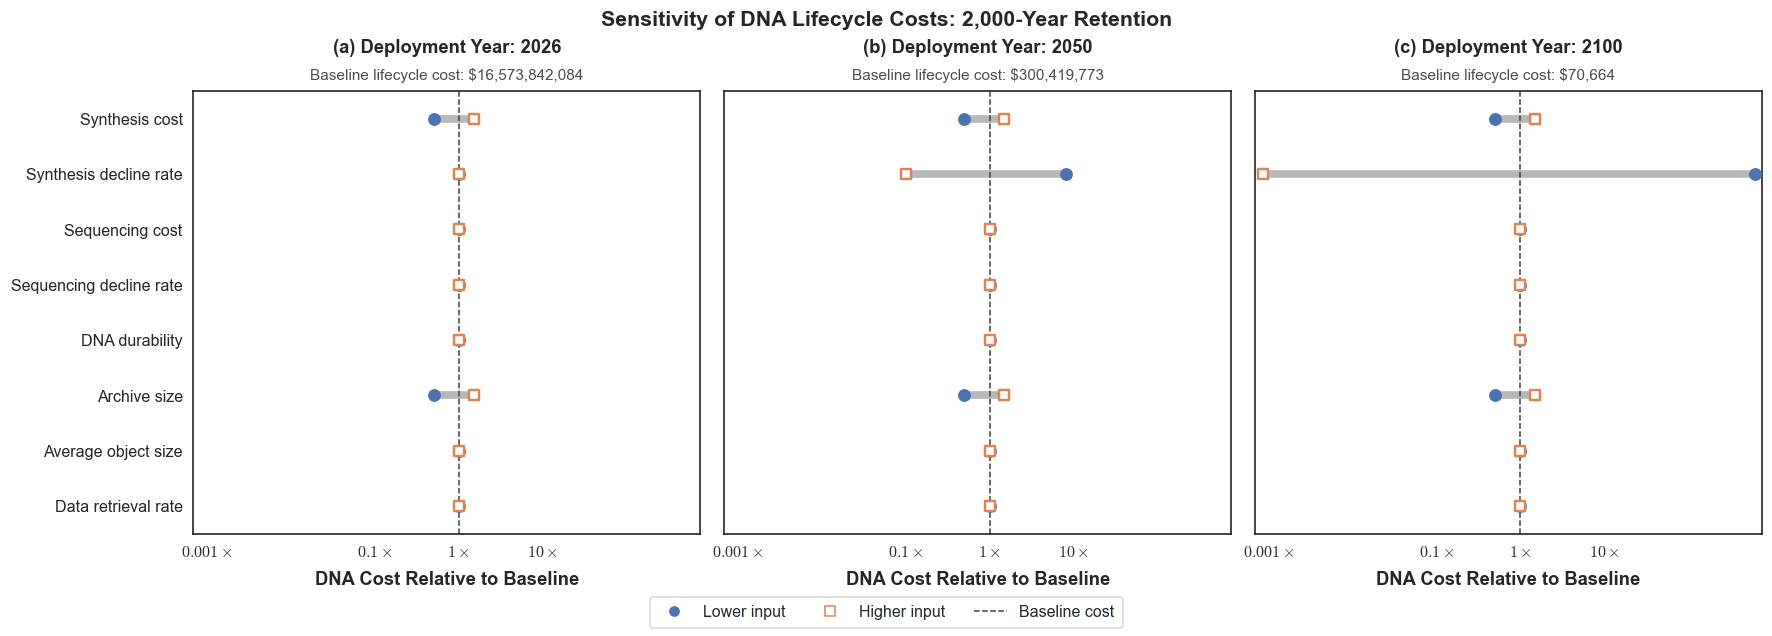

In [ ]:
SAVE = True  # False previews only; True exports this figure and its data.
long_retention_base = replace(BASE, horizon_years=2000)
s12_scenarios = {"baseline": long_retention_base, "future": replace(long_retention_base, start_year=FUTURE_START),
                "2100": replace(long_retention_base, start_year=2100)}
frames = []
for label, scenario in s12_scenarios.items():
    frame = dna_cost_sensitivity(scenario, use_present_value=False)
    frame = frame[frame.parameter != "Discount rate"].copy()
    frame["scenario"] = label
    frame["start_year"] = scenario.start_year
    frame["low_ratio"] = frame.low_cost / frame.baseline_cost
    frame["high_ratio"] = frame.high_cost / frame.baseline_cost
    frames.append(frame)
s12 = pd.concat(frames, ignore_index=True)
order = [
    "Synthesis cost", "Synthesis decline rate",
    "Sequencing cost", "Sequencing decline rate",
    "DNA durability", "Archive size", "Average asset size", "Annual retrieval",
]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.7), sharey=True, layout="constrained")
for index, ((label, scenario), ax) in enumerate(zip(s12_scenarios.items(), axes)):
    frame = s12[s12.scenario == label].set_index("parameter").loc[order]
    for y, row in enumerate(frame.itertuples()):
        ax.plot([row.low_ratio, row.high_ratio], [y, y], color="0.72", lw=5,
                solid_capstyle="butt", zorder=1)
        ax.scatter(row.low_ratio, y, marker="o", s=55, color=PALETTE[0], zorder=3)
        ax.scatter(row.high_ratio, y, marker="s", s=48, facecolor="white",
                   edgecolor=PALETTE[1], linewidth=1.6, zorder=4)
    ax.axvline(1, color="0.25", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_xticks([0.001, 0.1, 1, 10, 1000])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: rf"${x:g}\times$"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(min(0.08, s12[["low_ratio", "high_ratio"]].min().min() * 0.8),
                max(12, s12[["low_ratio", "high_ratio"]].max().max() * 1.2))
    ax.set_yticks(range(len(order)), [p.replace("Average asset size", "Average object size").replace("Annual retrieval", "Data retrieval rate") for p in order])
    ax.set_ylim(len(order) - 0.5, -0.5)
    cost = frame.baseline_cost.iloc[0]
    ax.set_title(f"({chr(97 + index)}) Deployment Year: {scenario.start_year}",
                 fontsize=12, fontweight="bold", color="0.15", pad=25)
    ax.text(0.5, 1.025, f"Baseline lifecycle cost: ${cost:,.0f}",
            transform=ax.transAxes, fontsize=10, ha="center", color="0.3")
    ax.set_xlabel("DNA Cost Relative to Baseline", fontsize=12, fontweight="bold", color="0.15", labelpad=7)
    ax.grid(False, which="both")
    ax.tick_params(axis="both", which="major", labelsize=10.5, colors="0.15", length=0, pad=7)
    ax.tick_params(which="minor", length=0)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("0.15")
        spine.set_linewidth(1.1)
handles = [
    Line2D([], [], marker="o", color=PALETTE[0], ls="", label="Lower input"),
    Line2D([], [], marker="s", markerfacecolor="white", color=PALETTE[1], ls="", label="Higher input"),
]
handles.append(Line2D([], [], color="0.25", ls="--", lw=1, label="Baseline cost"))
fig.suptitle("Sensitivity of DNA Lifecycle Costs: 2,000-Year Retention", fontsize=14, fontweight="bold", color="0.15")
fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=True,
           fancybox=True, facecolor="white", edgecolor="0.8", framealpha=0.8,
           fontsize=10.5, handlelength=2, handletextpad=0.8, borderpad=0.5)
# Isolate replacement costs, which can be too small to change a float-valued total.
replacement_rows = []
for scenario in s12_scenarios.values():
    for lifetime in (500, 1000, 1500):
        probe = replace(scenario, dna_durability_years=lifetime, technologies=("DNA",))
        annual = simulate_scenario(probe).yearly
        initial_write = float(annual.loc[annual.year == probe.start_year, "write_cost_usd"].sum())
        replacement_write = float(annual.loc[annual.year > probe.start_year, "write_cost_usd"].sum())
        replacement_rows.append({"deployment_year": probe.start_year, "retention_years": probe.horizon_years,
            "dna_lifetime_years": lifetime,
            "replacement_count": (probe.horizon_years - 1) // lifetime,
            "replacement_years": "; ".join(str(y) for y in range(
                probe.start_year + lifetime, probe.start_year + probe.horizon_years, lifetime)),
            "initial_write_usd": initial_write, "replacement_write_usd": replacement_write,
            "replacement_to_initial_write_ratio": replacement_write / initial_write})
s12_replacements = pd.DataFrame(replacement_rows)
print("S12: 2,000-year retention; replacement writes are included, not omitted.")
print(s12_replacements.to_string(index=False, float_format=lambda value: f"{value:.6e}"))

record("S12_dna_cost_sensitivity_long_retention", fig,
       f"One-at-a-time sensitivity of DNA lifecycle cost for archives starting in {long_retention_base.start_year}, "
       f"{FUTURE_START}, and 2100. Workload: {describe(long_retention_base)}. Inputs vary by +/-50%. Data retrieval rate is the percentage of archive volume retrieved per year. "
       "Discount rate is omitted because costs here are undiscounted. Inputs appear in a fixed order across deployment years. Symbols identify lower and higher "
       "inputs, while connecting segments span their costs. Each panel is normalized to its own "
       "baseline (dashed line); the horizontal scale is logarithmic. DNA prices are anchored in "
       f"{long_retention_base.dna_cost_base_year}. Small or overlapping effects are quantified in the accompanying CSV. Retention is fixed at 2,000 years. DNA lifetimes of 500, 1,000, and 1,500 years require three, one, and one replacements, respectively; no replacement is charged at the retention endpoint. Continued exponential synthesis decline makes these future writes negligible relative to the initial write. This result depends on the absence of a synthesis-price floor; it does not establish that durability is generally irrelevant.",
       {"sensitivity": s12, "replacement_audit": s12_replacements}, s12_scenarios)

## Optional: export all rendered figures

Includes only figures run in this session, in notebook order. Rerun this cell after changing figures; it does not require running every figure.

In [37]:
if not FIGURES:
    raise RuntimeError("Run at least one figure cell first.")
OUT.mkdir(parents=True, exist_ok=True)
notebook = json.loads((ROOT / "Figures_Paper_2026.ipynb").read_text(encoding="utf-8"))
ordered_names = []
for cell in notebook["cells"]:
    source = "".join(cell["source"])
    for name in FIGURES:
        if f'record("{name}"' in source and name not in ordered_names:
            ordered_names.append(name)
with PdfPages(OUT / "Paper_Figures.pdf") as pdf:
    for name in ordered_names:
        save_figure(name)
        pdf.savefig(FIGURES[name], bbox_inches="tight", facecolor="white")
(OUT / "figure_captions.md").write_text(
    "# Figure captions\n\n" + "\n\n".join(f"## {name}\n\n{CAPTIONS[name]}" for name in ordered_names), encoding="utf-8")
display(pd.DataFrame({"Figure": ordered_names, "PDF": [f"{name}.pdf" for name in ordered_names]}))
print(f"Combined PDF: {OUT / 'Paper_Figures.pdf'}")

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F1_dna_trajectories: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved F2a_unit_costs: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


...

'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Saved S9_retention_decline_sensitivity: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026
Saved S10_sequencing_parity_by_synthesis: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026
Saved S11_retention_parity_by_synthesis: PDF, SVG, PNG, CSV and metadata in C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


,Figure,PDF
0,F1_dna_trajectories,F1_dna_trajectories.pdf
1,F2a_unit_costs,F2a_unit_costs.pdf
2,F2b_unit_costs,F2b_unit_costs.pdf
3,F2c_unit_costs,F2c_unit_costs.pdf
4,F3a_lifecycle_components,F3a_lifecycle_components.pdf
5,F4a_start_year_outlook,F4a_start_year_outlook.pdf
6,F4b_lifecycle_near_parity,F4b_lifecycle_near_parity.pdf
7,F5a_encoding_overhead,F5a_encoding_overhead.pdf
8,F5b_addressing,F5b_addressing.pdf
9,F5c_addressing,F5c_addressing.pdf


Combined PDF: C:\Users\Alex\PycharmProjects\Economic_DNA\figs\paper_2026\Paper_Figures.pdf


## Export Results figures to the paper

Save this notebook first. Run the final cell to define `export_results_figures()`, then uncomment one of the example calls. It regenerates the 15 selected figures, including the combined S10/S11 figure, from the saved setup and figure cells, without requiring earlier cells to have run. Existing `F1.pdf`, `F1.eps`, etc. in the paper's `figures/results` folder are replaced. Other files are untouched.

Sizes are canvas dimensions in inches; tight cropping can change final page dimensions. Omit sizes to keep each figure's defaults. EPS uses opaque styling where PDF supports transparency.

In [40]:
def export_results_figures(
    output_dir=r"C:\Users\Alex\papers\An_Economic_Analysis_of_DNA_based_Data_Storage_Systems\figures\results",
    figure_sizes=None,
    default_size=None,
    notebook_path=None,
):
    """Regenerate the Results figures from saved notebook cells; export PDF/EPS.

    Sizes are (width, height) in inches. None retains each figure's own size;
    figure_sizes (e.g. {"F1": (9, 6)}) overrides default_size for individual plots.
    Exports use tight bounding boxes, so final page dimensions include the labels
    and may differ from the requested canvas size. Save notebook edits first.
    This reruns saved setup defaults, not unsaved in-memory parameter changes.
    Existing selected exports are replaced; other files are left untouched.
    """
    import ast
    import json
    import math
    import os
    import sys
    import tempfile
    from pathlib import Path
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    import pandas as pd
    from IPython.utils.capture import capture_output

    selected = {
        "F1": "F1_dna_trajectories",
        "F2a": "F2a_unit_costs", "F2b": "F2b_unit_costs", "F2c": "F2c_unit_costs",
        "F3a": "F3a_lifecycle_components", "F3b": "F3b_lifecycle_components",
        "F3c": "F3c_lifecycle_components", "M1": "M1_dna_cost_sensitivity",
        "S2": "S2_retrieval_vs_synthesis_threshold", "S4": "S4_joint_decline_sensitivity",
        "S4c": "S4c_deployment_year_parity", "S4d": "S4d_dna_declines_deployment_parity",
        "S10": "S10_sequencing_parity_by_synthesis", "S11": "S11_retention_parity_by_synthesis",
        "S10_S11": "S10_S11_combined_parity",
    }
    figure_sizes = {} if figure_sizes is None else dict(figure_sizes)
    unknown = set(figure_sizes) - selected.keys()
    if unknown:
        raise ValueError(f"Unknown figure size keys: {sorted(unknown)}")

    def checked_size(size):
        if size is None:
            return None
        try:
            width, height = map(float, size)
        except (TypeError, ValueError) as error:
            raise ValueError("Figure sizes must be (width, height) pairs in inches.") from error
        if not all(math.isfinite(v) and v > 0 for v in (width, height)):
            raise ValueError("Figure dimensions must be finite and positive.")
        return width, height

    default_size = checked_size(default_size)
    figure_sizes = {key: checked_size(value) for key, value in figure_sizes.items()}
    if notebook_path is None:
        root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "Figures_Paper_2026.ipynb").is_file()), None)
        if root is None:
            raise FileNotFoundError("Run from the Economic_DNA repository or pass notebook_path.")
        notebook_path = root / "Figures_Paper_2026.ipynb"
    notebook_path = Path(notebook_path).resolve()
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    setups, sources = [], {}
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        source = "".join(cell["source"])
        if "setup" in cell.get("metadata", {}).get("tags", []):
            setups.append(source)
        if "figure" not in cell.get("metadata", {}).get("tags", []):
            continue
        tree = ast.parse(source)
        names = [node.args[0].value for node in ast.walk(tree)
                 if isinstance(node, ast.Call) and isinstance(node.func, ast.Name)
                 and node.func.id == "record" and node.args
                 and isinstance(node.args[0], ast.Constant)]
        for name in names:
            if name in selected.values():
                if name in sources:
                    raise ValueError(f"Duplicate figure cell: {name}")
                # Disable normal PNG/CSV exports; only the requested PDF/EPS files are written.
                for node in ast.walk(tree):
                    if isinstance(node, ast.Assign) and any(
                        isinstance(target, ast.Name) and target.id == "SAVE" for target in node.targets
                    ):
                        node.value = ast.Constant(False)
                sources[name] = compile(ast.fix_missing_locations(tree), str(notebook_path), "exec")
    missing = set(selected.values()) - sources.keys()
    if missing or not setups:
        raise ValueError(f"Missing setup or figure cells: {sorted(missing)}")

    destination = Path(output_dir).expanduser().resolve()
    destination.mkdir(parents=True, exist_ok=True)
    namespace = {"__name__": "__paper_results_export__"}
    original_cwd, original_path = Path.cwd(), list(sys.path)
    existing_figures = set(plt.get_fignums())
    rows = []
    try:
        os.chdir(notebook_path.parent)
        with mpl.rc_context(), plt.ioff(), tempfile.TemporaryDirectory(
            prefix=".results-export-", dir=destination
        ) as staging:
            with capture_output():
                for source in setups:
                    exec(compile(source, str(notebook_path), "exec"), namespace)
            namespace["display"] = lambda *args, **kwargs: None
            for label, stem in selected.items():
                print(f"Regenerating {label}...")
                with capture_output():
                    exec(sources[stem], namespace)
                fig = namespace["FIGURES"][stem]
                size = figure_sizes.get(label, default_size)
                if size is not None:
                    fig.set_size_inches(*size, forward=True)
                fig.savefig(Path(staging) / f"{label}.pdf", bbox_inches="tight", facecolor="white")
                # EPS cannot encode alpha: use opaque artwork, retaining hidden artists.
                translucent = [(artist, artist.get_alpha()) for artist in fig.findobj()
                               if artist.get_alpha() is not None and 0 < artist.get_alpha() < 1]
                try:
                    for artist, _ in translucent:
                        artist.set_alpha(1)
                    fig.savefig(Path(staging) / f"{label}.eps", bbox_inches="tight", facecolor="white")
                finally:
                    for artist, alpha in translucent:
                        artist.set_alpha(alpha)
                width, height = fig.get_size_inches()
                rows.append({"Figure": label, "Width (in)": width, "Height (in)": height,
                             "PDF": str(destination / f"{label}.pdf"),
                             "EPS": str(destination / f"{label}.eps")})
                plt.close(fig)
            # Publish only after every figure has regenerated and saved successfully.
            for label in selected:
                for extension in ("pdf", "eps"):
                    filename = f"{label}.{extension}"
                    os.replace(Path(staging) / filename, destination / filename)
    finally:
        os.chdir(original_cwd)
        sys.path[:] = original_path
        for number in set(plt.get_fignums()) - existing_figures:
            plt.close(number)
    print(f"Exported {len(rows)} figures as PDF and EPS to {destination}")
    return pd.DataFrame(rows)


# Keep every figure's default size:
exported_results = export_results_figures()

# Override selected figures only (width, height in inches):
# exported_results = export_results_figures(figure_sizes={"F1": (9, 6), "M1": (16, 5.7)})

# Or set one canvas size for all figures, with optional individual overrides:
# exported_results = export_results_figures(default_size=(10.5, 6.7), figure_sizes={"M1": (16, 5.7)})


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Regenerating F1...


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Regenerating F2a...


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


...

Regenerating S10...


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Regenerating S11...


'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


FileNotFoundError: [WinError 2] The system cannot find the file specified: 'C:\\Users\\Alex\\papers\\An_Economic_Analysis_of_DNA_based_Data_Storage_Systems\\figures\\results\\.results-export-v_zhxd6j\\F1.jpeg' -> 'C:\\Users\\Alex\\papers\\An_Economic_Analysis_of_DNA_based_Data_Storage_Systems\\figures\\results\\F1.jpeg'